<span style="color:blue">
    
## Import important python liberaries

</span>

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

<span style="color:blue">
    
# Load dataset

- We have three csv file, stored in "dataset" directory.
- Customers.csv file conains customer personal information
- bureau_data.csv file contains, customer's credit beureau details.
- Loan.csv file contains customer's loan information and related data.

</span>

In [2]:
loan_df=pd.read_csv("../dataset/loans.csv")
customers_df=pd.read_csv("../dataset/customers.csv")
bureau_df=pd.read_csv("../dataset/bureau_data.csv")

In [3]:
loan_df.head(1)


,loan_id,cust_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,L00001,C00001,Auto,Secured,3004000,2467000,49340.0,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False


In [4]:
customers_df.head(1)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001


In [5]:
bureau_df.head(1)

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,1,1,42,0,0,3,7


In [6]:
bureau_df.shape,customers_df.shape,loan_df.shape

((50000, 8), (50000, 12), (50000, 15))

<span style="color:blue">

# Merging the dataset

- Merging loan_df and customers_df on the cust_id column and storing the merged data in df_cust_loan dataframe.

</span>

In [7]:
df_cust_loan=pd.merge(customers_df,loan_df, on="cust_id")

<span style="color:blue">

### Merging the datasets
    
 - Merging df_cust_loan with bureau_df on column cust_id columns.

</span>

In [8]:
df=pd.merge(df_cust_loan,bureau_df,on="cust_id")
df.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'default',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   cust_id                      50000 non-null  object 
 1   age                          50000 non-null  int64  
 2   gender                       50000 non-null  object 
 3   marital_status               50000 non-null  object 
 4   employment_status            50000 non-null  object 
 5   income                       50000 non-null  int64  
 6   number_of_dependants         50000 non-null  int64  
 7   residence_type               49938 non-null  object 
 8   years_at_current_address     50000 non-null  int64  
 9   city                         50000 non-null  object 
 10  state                        50000 non-null  object 
 11  zipcode                      50000 non-null  int64  
 12  loan_id                      50000 non-null  object 
 13  loan_purpose    

<span style="color:blue">

### Interpretation:
- In the above dataset info(), there are only one clumns which contains some null values. Rest of all columns are okay. Because each columns contains some values, and have 50k rows but in residence_type columns, have less records.

</span>

In [10]:
df.default.unique()

array([False,  True])

In [11]:
# checking target columns
print("Unique values in default columns:",df.default.unique())

#  checking the frequency 
print("Checking the frequency of unique values:",df.default.value_counts())

# percentage of frequecy, it helps to check class imbalance problem
print("Percentage of the frequency",df['default'].value_counts(normalize=True) * 100)

Unique values in default columns: [False  True]
Checking the frequency of unique values: default
False    45703
True      4297
Name: count, dtype: int64
Percentage of the frequency default
False    91.406
True      8.594
Name: proportion, dtype: float64


<span style="color:blue">

### Interpretation:

- From the above output, we can conclude that the dataset seems imbalanced becuase default column contains more than 91% false value and only 8% true value.
- That means, it is highly imbalanced (class imbalance), that needs some corrections.

</span>

<span style="color:blue">

## Data Cleaning:

- In the current data frame, cust_id, loan_id are row data labels, they have zero predictive signals.
- If they kept in dataframe, model may memorise the records.
- Zip code have too many unique values (high cardinality) and city + state already contains geographical information, this columns seems unnessary, but before removing this, need to discuss with SME/Management.

</span>

<span style="color:red">

## Dropped column:cust_id, loan_id, zip code

</span>

In [12]:
new_df = df.drop(columns=['cust_id', 'loan_id'])


<span style="color:blue">

## Preventive Steps of Data Leakage

-  Preventive steps from data leakage.
-  Splitting train and test data
-  Train set data should not be any influcence with Test set data.
-  Train Test Contamination
-  Target leakage
-  The reason, it model may show good result with test data but when new data comes, it may not perform well.
-  So, we hae to do saparatly EDA, Feature Engineering and Transformation on each train and test data separatly, to prevent with data leakage.

</span>

In [13]:
X=new_df.drop("default",axis="columns")
y=new_df["default"]


In [14]:
from sklearn.model_selection import train_test_split

In [15]:
X_train, X_test, y_train, y_test=train_test_split(X,y,stratify=y,random_state=42, test_size=0.25)


<span style="color:blue">

## Interpretation

- Here, using, stratify=y because dataset is highly imbalanced.
- The distribution in the train and test data also will be in the same test size, means, 25% of the class distribution data also preserved.

</span>

In [16]:
df_train=pd.concat([X_train,y_train],axis=1)
df_test=pd.concat([X_test,y_test],axis=1)
df_train.head(2)


,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
12746,59,M,Married,Self-Employed,11327000,3,Owned,30,Hyderabad,Telangana,...,2020-10-31,2020-11-11,4,2,152,20,118,4,36,False
32495,44,F,Single,Salaried,715000,0,Owned,27,Mumbai,Maharashtra,...,2022-10-22,2022-10-27,3,1,160,10,62,5,5,False


In [17]:
df_train.shape,df_test.shape

((37500, 31), (12500, 31))

<span style="color:blue">

## Data Cleaning

</span>

In [18]:
df_test.isna().sum()

age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 15
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_at_application     0
disbursal_date                  0
installment_start_dt            0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_months               0
total_dpd                       0
enquiry_count                   0
credit_utiliza

In [19]:
df_train.employment_status.value_counts()

employment_status
Self-Employed    24045
Salaried         13455
Name: count, dtype: int64

In [20]:
df_train.isna().sum()

age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 47
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_at_application     0
disbursal_date                  0
installment_start_dt            0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_months               0
total_dpd                       0
enquiry_count                   0
credit_utiliza

In [21]:
# unique values
df_test['residence_type'].unique()
# checking frequency of each unique values
df_test['residence_type'].value_counts()

residence_type
Owned       7105
Mortgage    2961
Rented      2419
Name: count, dtype: int64

In [22]:
# unique values
df_train['residence_type'].unique()
# checking frequency of each unique values
df_train['residence_type'].value_counts()

residence_type
Owned       21133
Mortgage     8858
Rented       7462
Name: count, dtype: int64

<span style="color:blue">

## Interpretation 

- There are only 0.12% values have null values, so it dropping those rows will not affact much, but replacing those with most frequent category will be much better.
- Owned category is very high in residence_type column, so replacing null values with maximum frequent category.

</span>

In [23]:
df_test['residence_type'] = df_test['residence_type'].fillna(df_test['residence_type'].mode()[0])
df_test['residence_type'].unique()

array(['Owned', 'Mortgage', 'Rented'], dtype=object)

In [24]:
df_train['residence_type'] = df_train['residence_type'].fillna(df_train['residence_type'].mode()[0])
df_train['residence_type'].unique()

array(['Owned', 'Mortgage', 'Rented'], dtype=object)

In [25]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12500 entries, 19205 to 26116
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          12500 non-null  int64  
 1   gender                       12500 non-null  object 
 2   marital_status               12500 non-null  object 
 3   employment_status            12500 non-null  object 
 4   income                       12500 non-null  int64  
 5   number_of_dependants         12500 non-null  int64  
 6   residence_type               12500 non-null  object 
 7   years_at_current_address     12500 non-null  int64  
 8   city                         12500 non-null  object 
 9   state                        12500 non-null  object 
 10  zipcode                      12500 non-null  int64  
 11  loan_purpose                 12500 non-null  object 
 12  loan_type                    12500 non-null  object 
 13  sanction_amount  

In [26]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 37500 entries, 12746 to 37784
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          37500 non-null  int64  
 1   gender                       37500 non-null  object 
 2   marital_status               37500 non-null  object 
 3   employment_status            37500 non-null  object 
 4   income                       37500 non-null  int64  
 5   number_of_dependants         37500 non-null  int64  
 6   residence_type               37500 non-null  object 
 7   years_at_current_address     37500 non-null  int64  
 8   city                         37500 non-null  object 
 9   state                        37500 non-null  object 
 10  zipcode                      37500 non-null  int64  
 11  loan_purpose                 37500 non-null  object 
 12  loan_type                    37500 non-null  object 
 13  sanction_amount  

In [27]:
# separating numerical and categorical columns

num_cols_test = df_test.select_dtypes(include='number').columns

num_cols_test

Index(['age', 'income', 'number_of_dependants', 'years_at_current_address',
       'zipcode', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio'],
      dtype='object')

In [28]:
# separating numerical and categorical columns

num_cols = df_train.select_dtypes(include='number').columns

num_cols,

(Index(['age', 'income', 'number_of_dependants', 'years_at_current_address',
        'zipcode', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
        'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
        'bank_balance_at_application', 'number_of_open_accounts',
        'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
        'total_dpd', 'enquiry_count', 'credit_utilization_ratio'],
       dtype='object'),)

## Graphical Visualization For EDA and Outlair detection

In [29]:
import math
# for dynamic length, firstly make colmns and rows
n_cols_test=3
n_rows_test=math.ceil(len(num_cols_test)/n_cols_test)



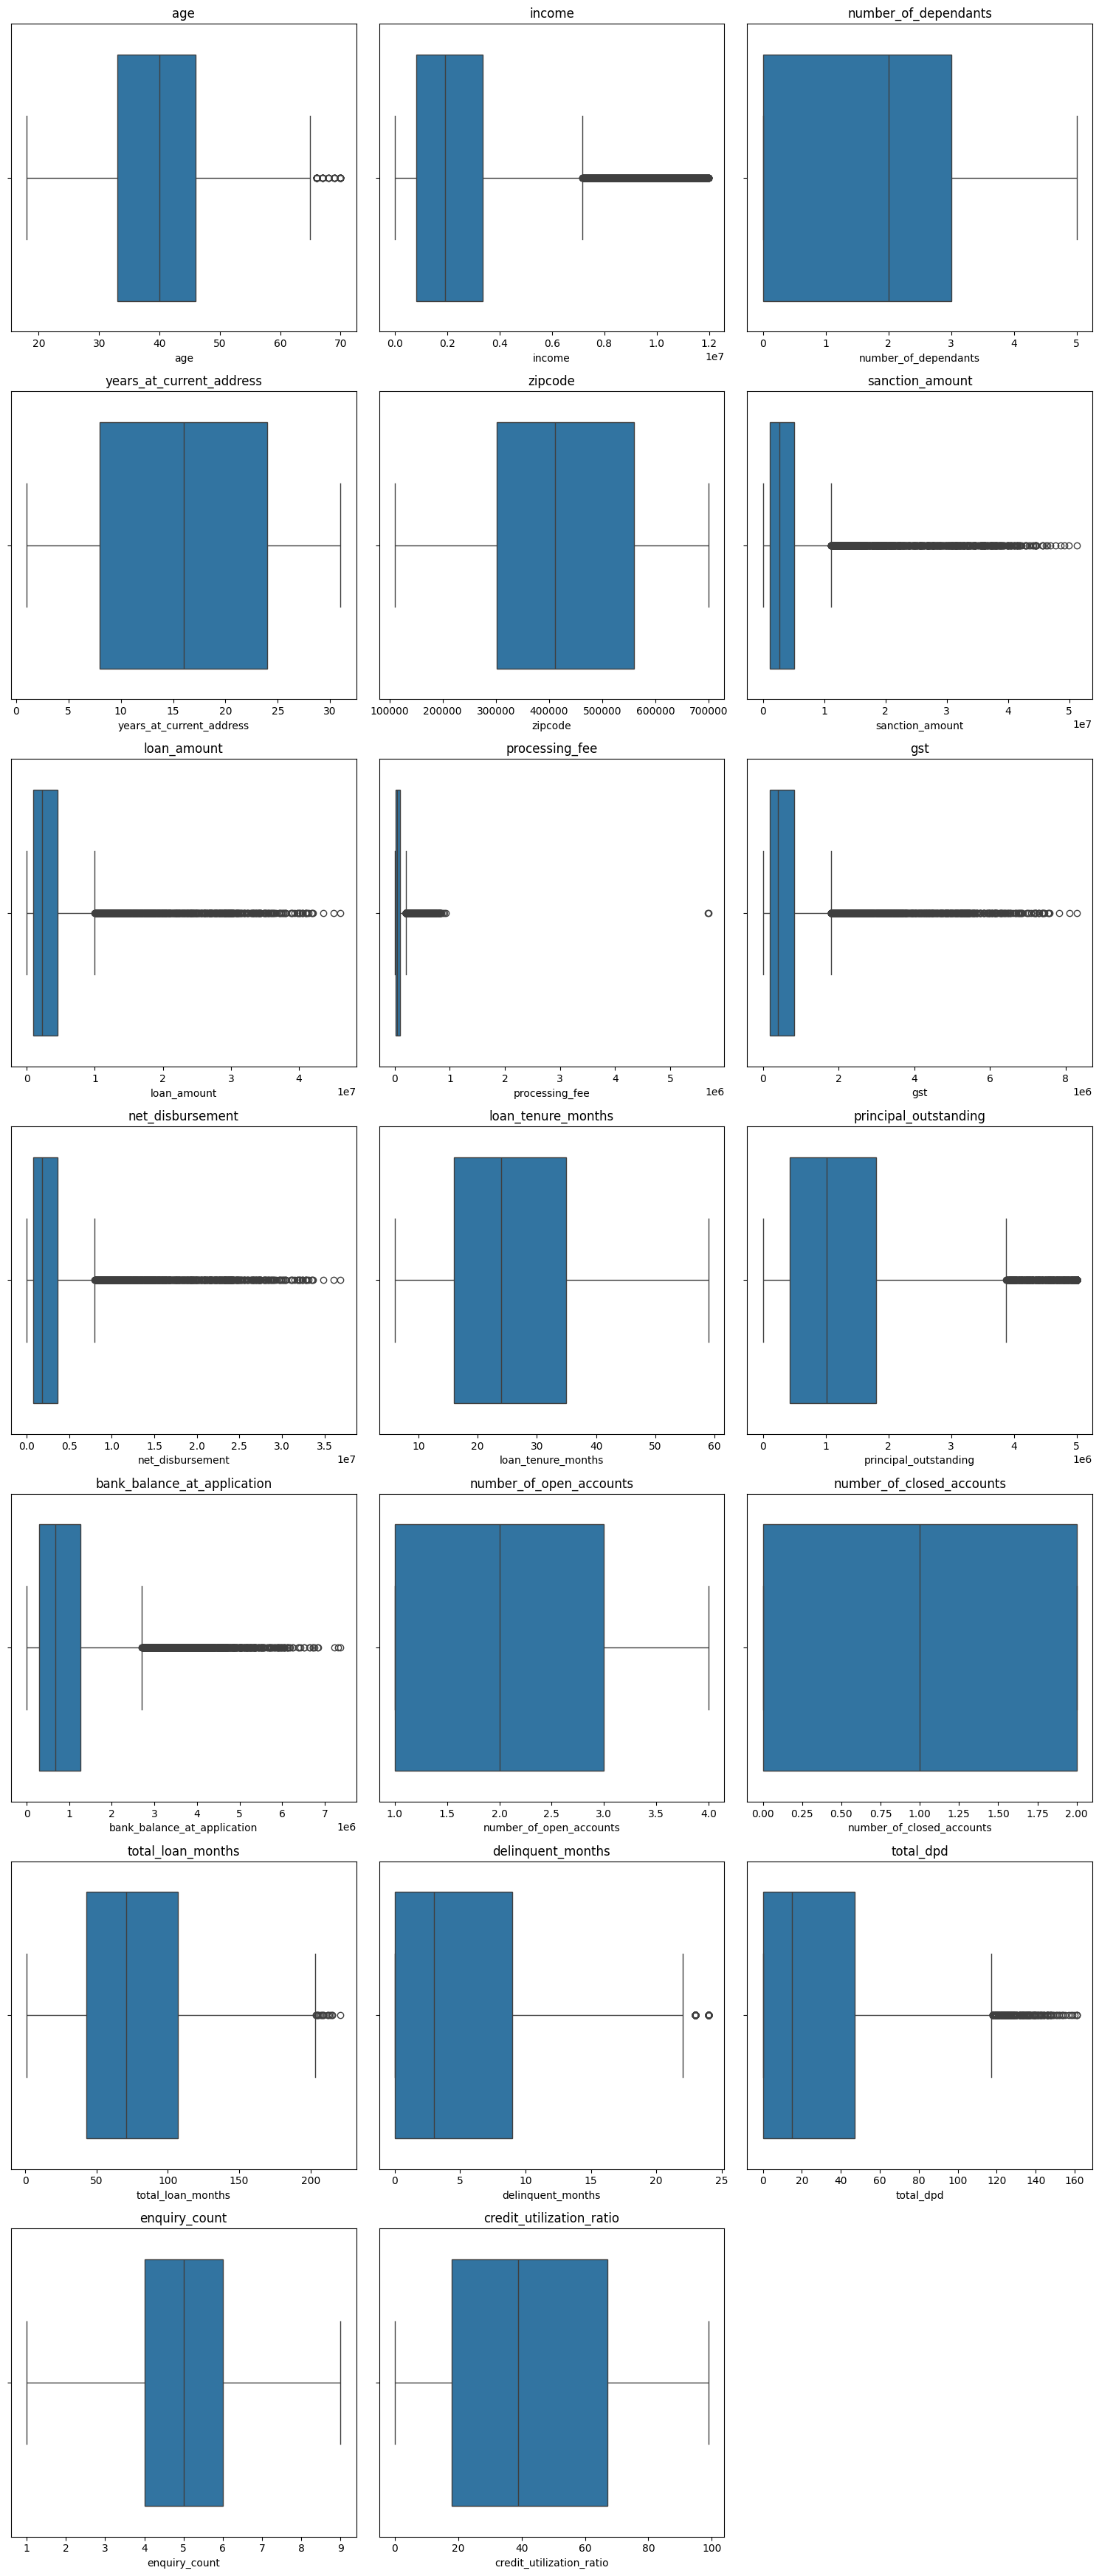

In [30]:


fig_test, axes_test = plt.subplots(n_rows_test, n_cols_test, figsize=(15, 5*n_rows_test))
axes_test = axes_test.flatten()

for ax, col in zip(axes_test, num_cols_test):
    sns.boxplot(x=df_test[col], ax=ax)
    ax.set_title(col)

# remove extra empty plots
for i in range(len(num_cols_test), len(axes_test)):
    fig_test.delaxes(axes_test[i])

plt.tight_layout()
plt.show()


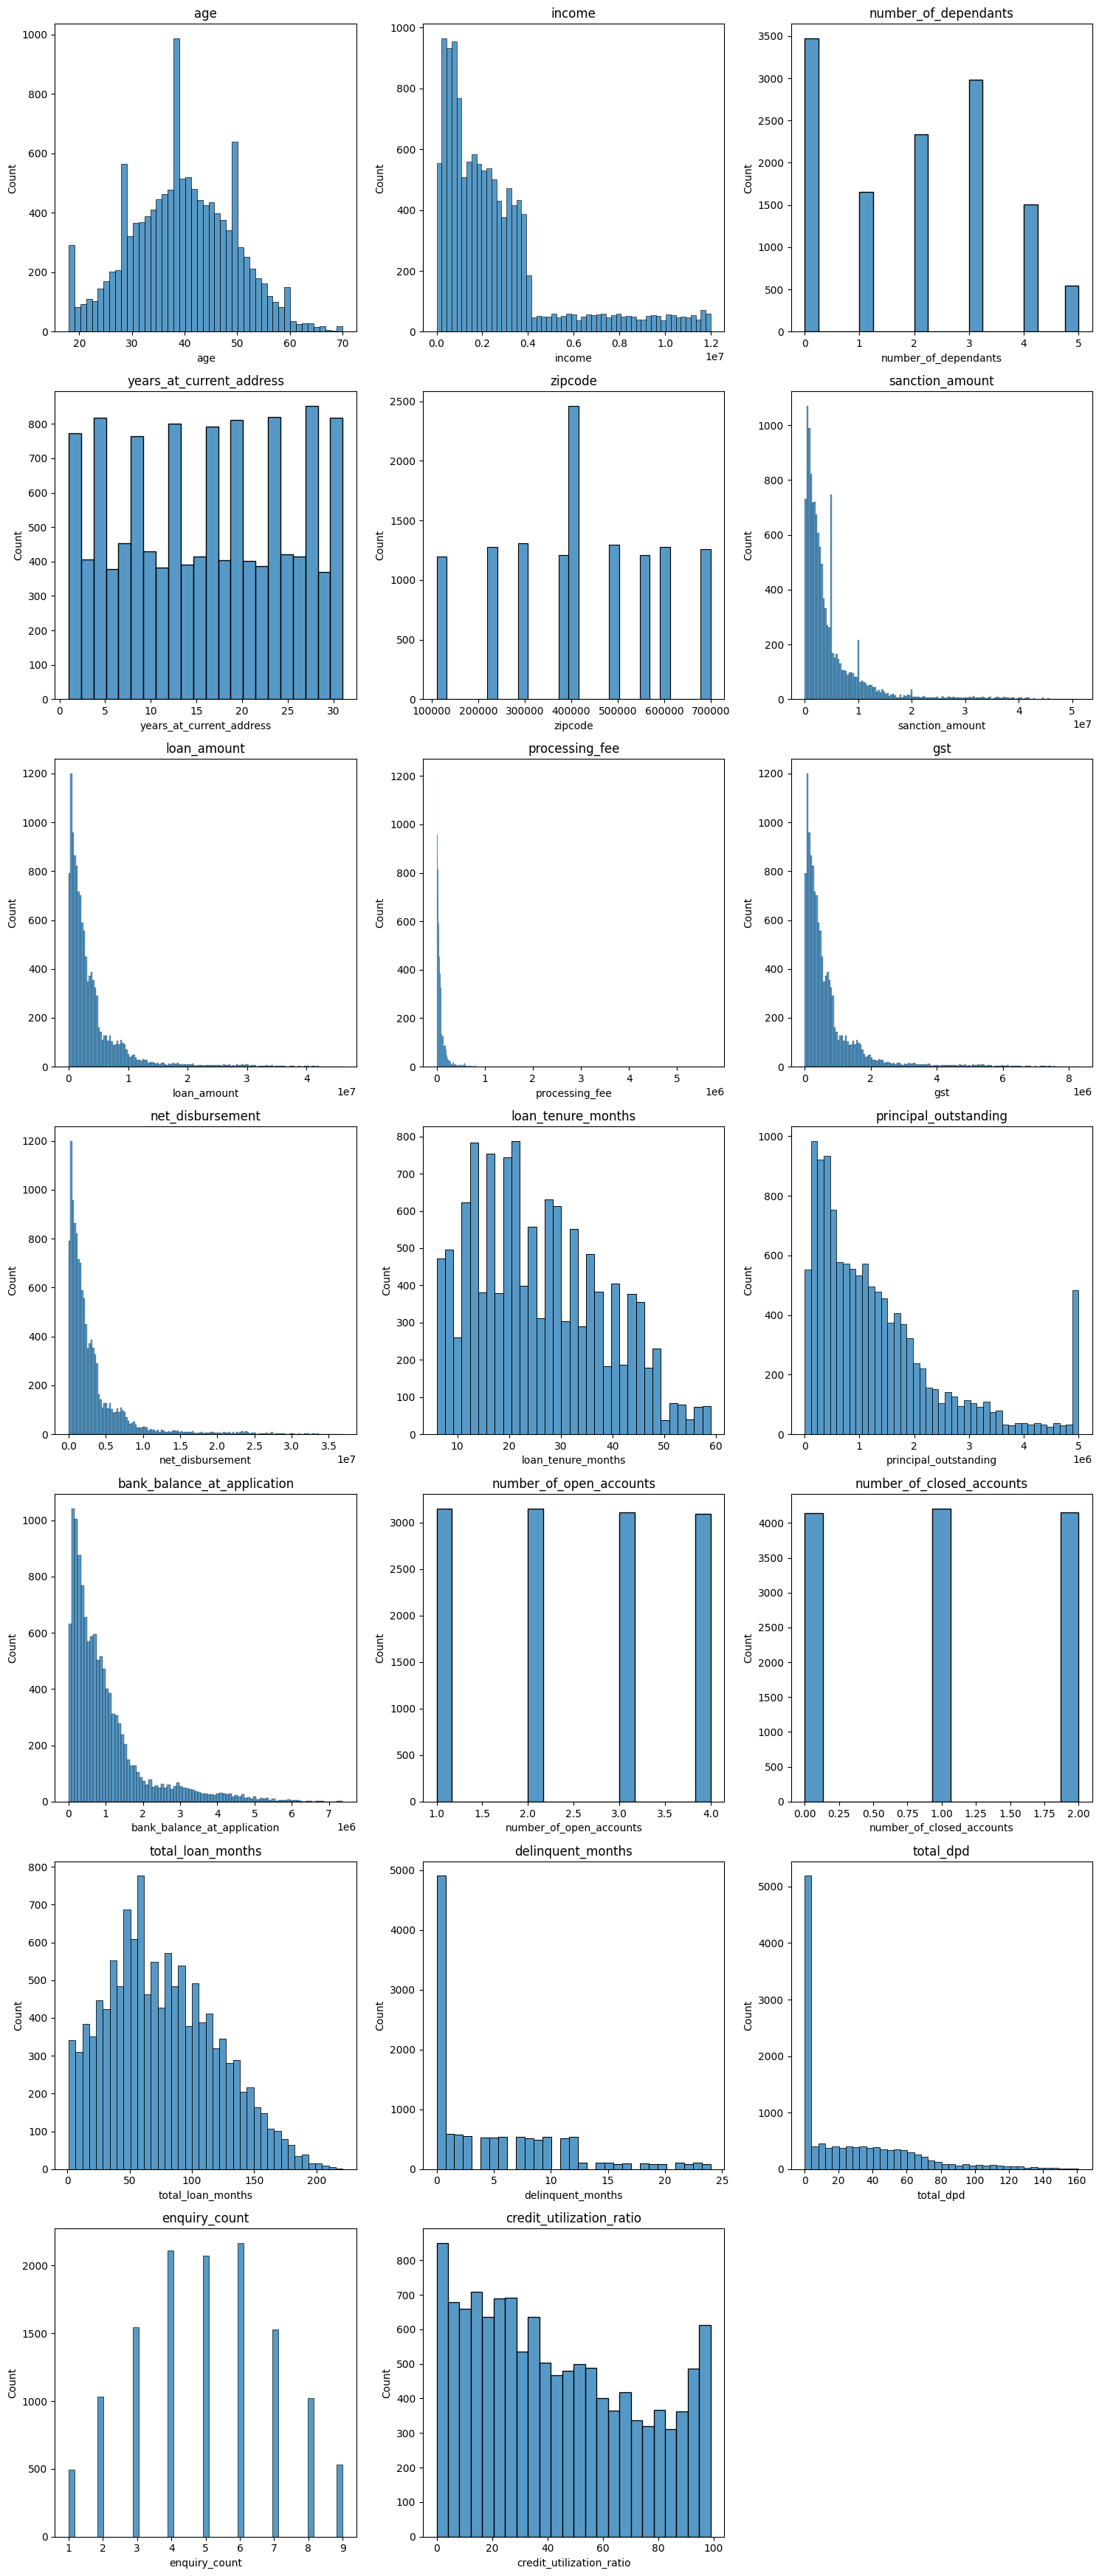

In [31]:
fig_test, axes_test = plt.subplots(n_rows_test, n_cols_test, figsize=(15, 5*n_rows_test))
axes_test = axes_test.flatten()

for ax, col in zip(axes_test, num_cols_test):
    sns.histplot(x=df_test[col], ax=ax)
    ax.set_title(col)


# remove extra empty plots
for i in range(len(num_cols_test), len(axes_test)):
    fig_test.delaxes(axes_test[i])


plt.tight_layout()
plt.show()

In [32]:
import math
# for dynamic length, firstly make colmns and rows
n_cols=3
n_rows=math.ceil(len(num_cols)/n_cols)



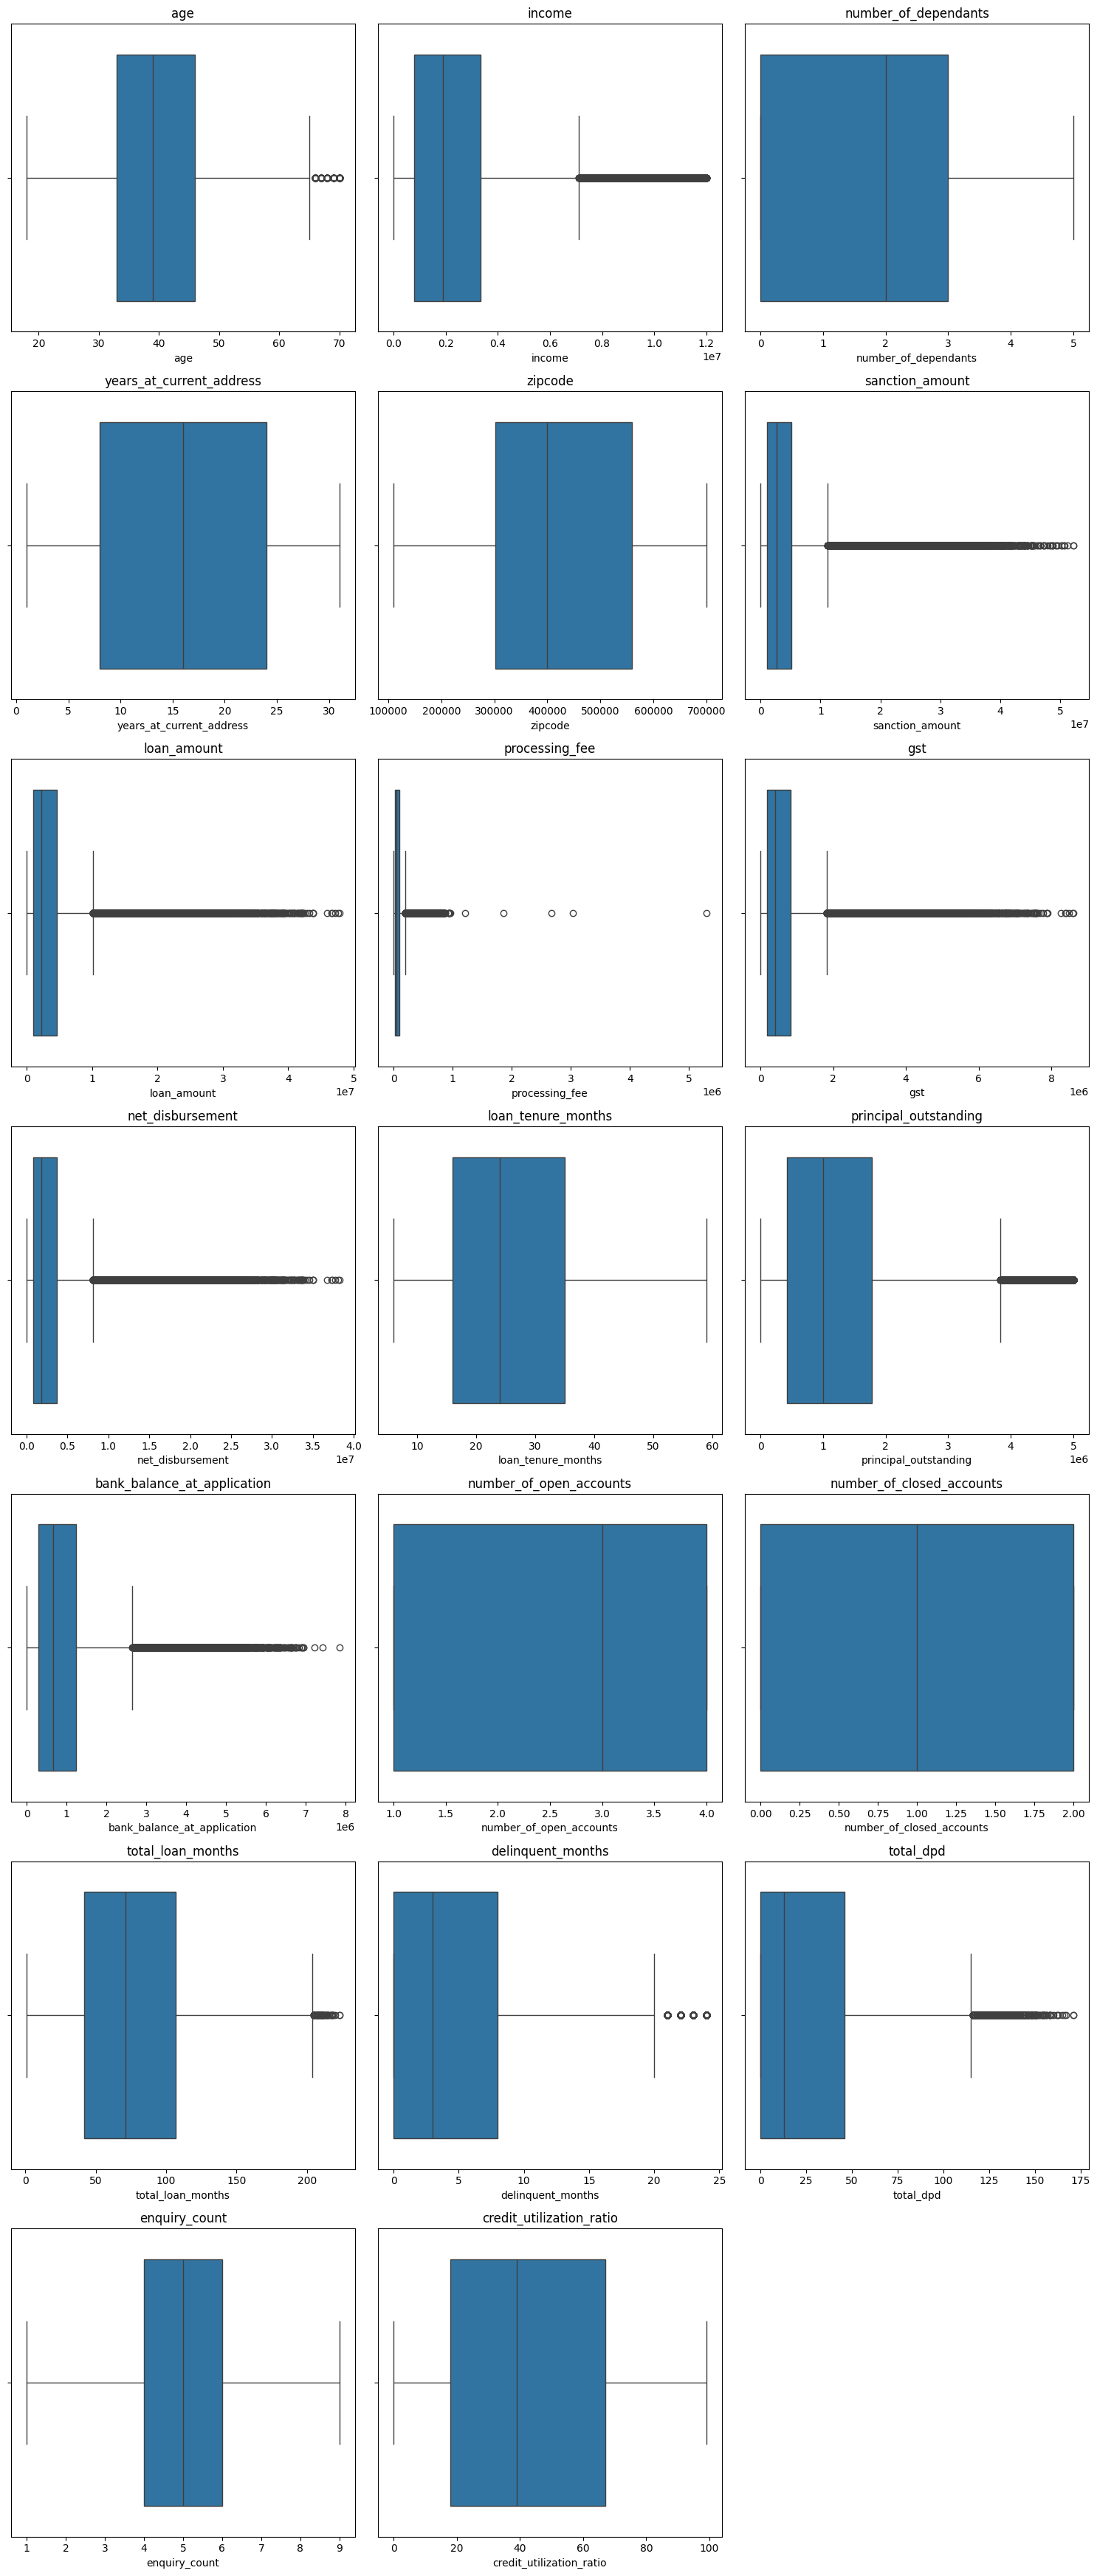

In [33]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.boxplot(x=df_train[col], ax=ax)
    ax.set_title(col)


# remove extra empty plots
for i in range(len(num_cols), len(axes)):
    fig.delaxes(axes[i])


plt.tight_layout()
plt.show()

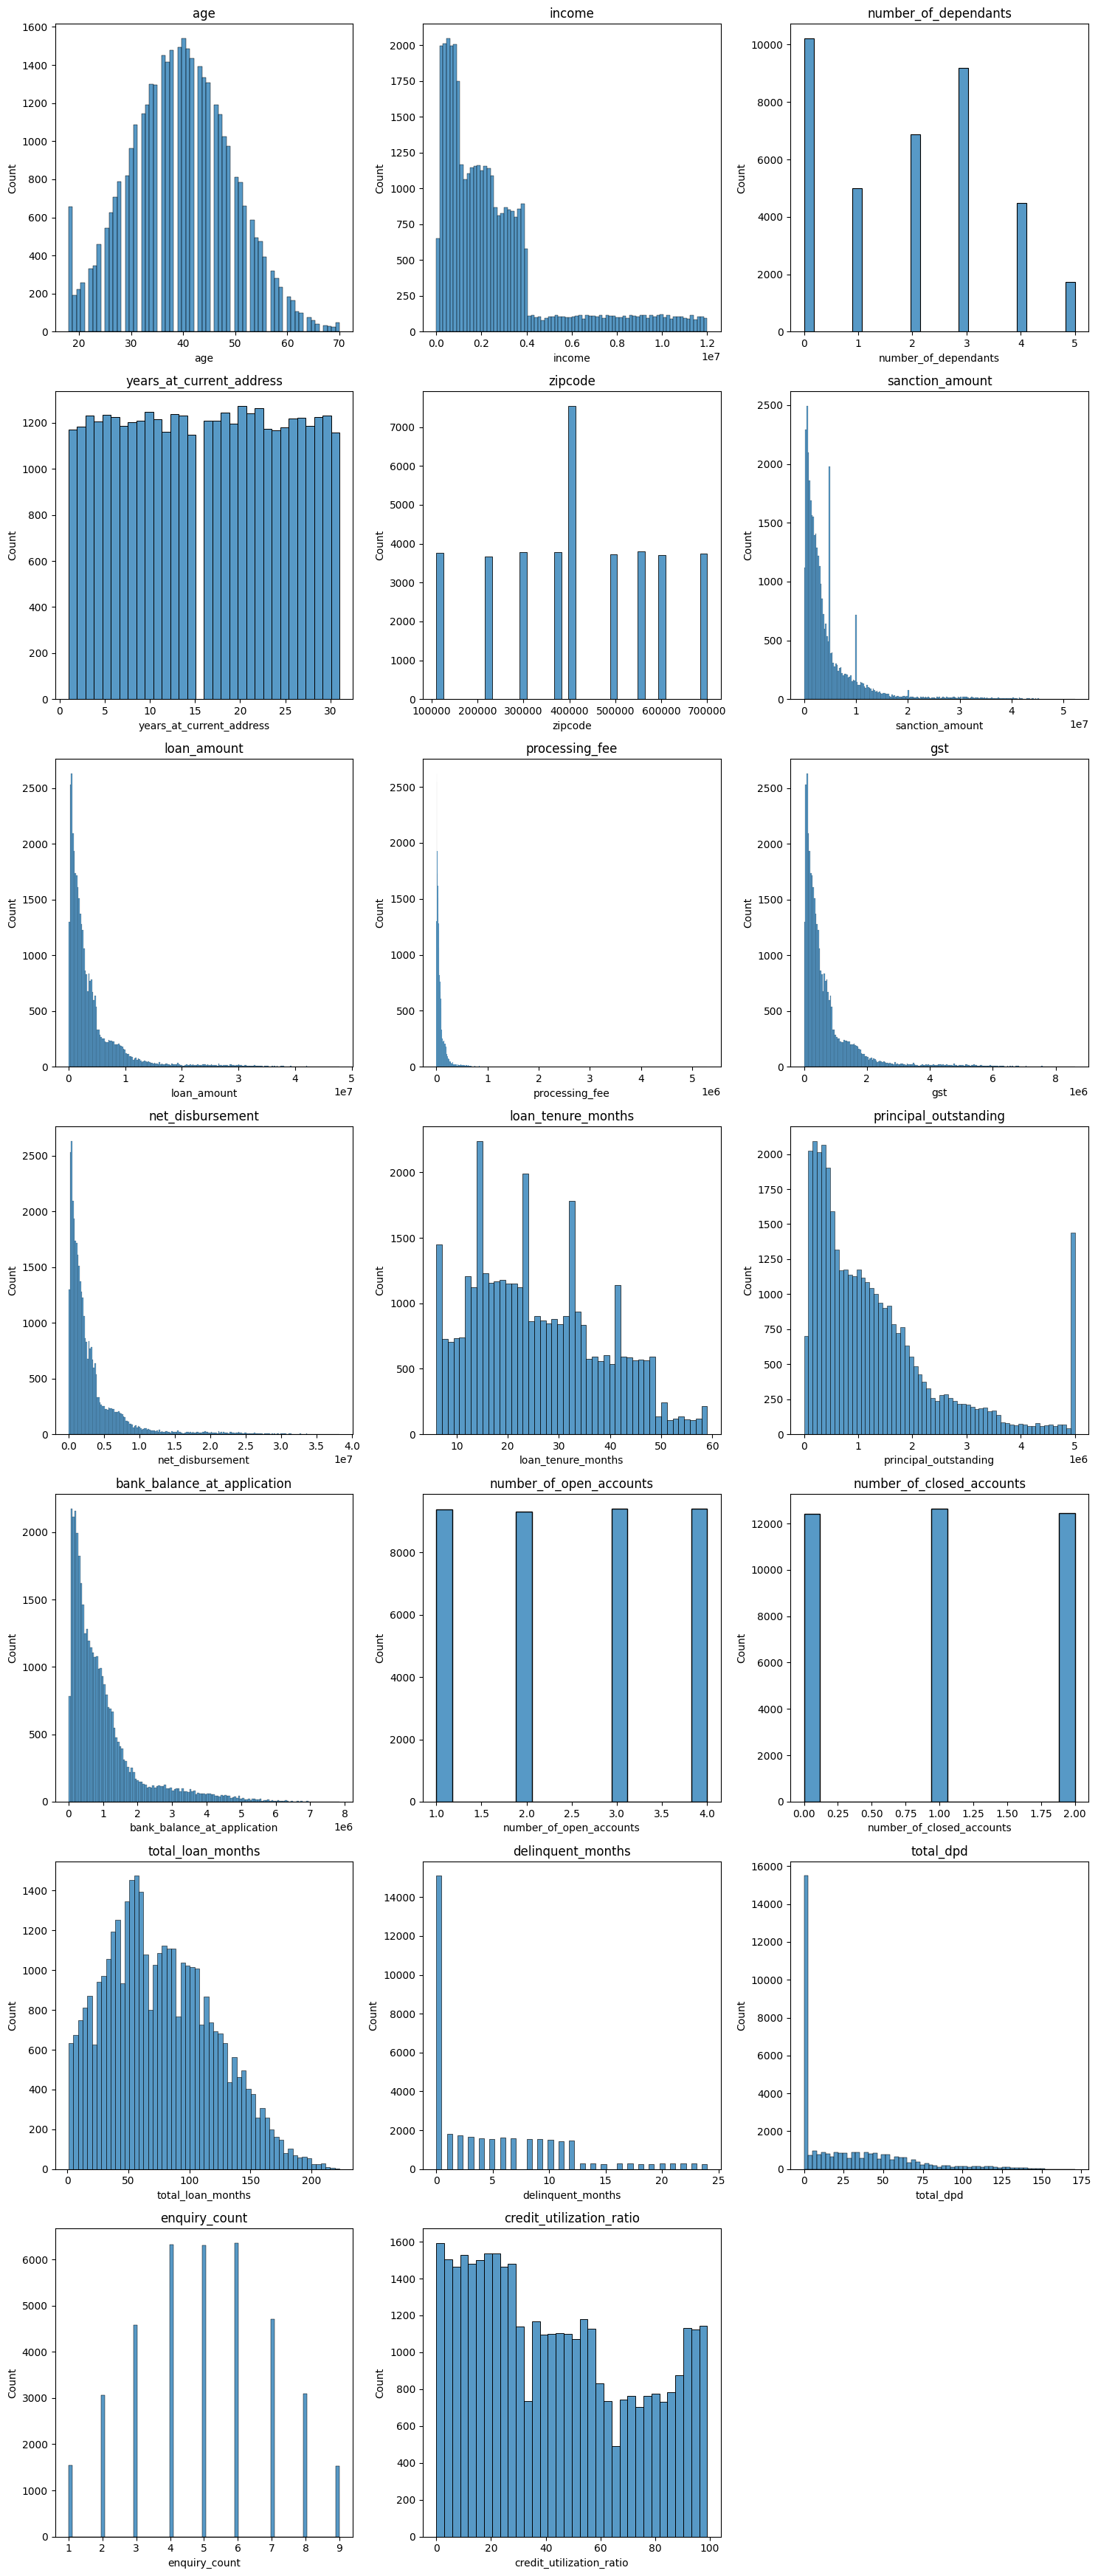

In [34]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.histplot(x=df_train[col], ax=ax)
    ax.set_title(col)


# remove extra empty plots
for i in range(len(num_cols), len(axes)):
    fig.delaxes(axes[i])


plt.tight_layout()
plt.show()

In [35]:
df_test.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'disbursal_date', 'installment_start_dt',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'default'],
      dtype='object')

In [36]:
df_train.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'disbursal_date', 'installment_start_dt',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'default'],
      dtype='object')

<span style="color:blue">

## Outlier removal

- Processing fee can not be greater than sanction loan amount, so these are clearly outliers.
- Either we can drop these rows or will remove at the time of correlation check, because processing fee is derived from loan amount, so there are a chance that these two columns may carry the same information

</span>

In [37]:
df_test[df_test['loan_amount']<df_test['processing_fee']][['loan_amount','processing_fee']]

,loan_amount,processing_fee
33705,3812000,5.678021e+06
12294,4639000,5.698030e+06


In [38]:
df_train[df_train['loan_amount']<df_train['processing_fee']][['loan_amount','processing_fee']]

,loan_amount,processing_fee
23981,2234000,2.669791e+06
28174,966000,1.214493e+06
47089,1738000,1.858965e+06
29305,2616000,3.036378e+06
9898,3626000,5.293544e+06


In [39]:
df_test[df_test['processing_fee']/df_test['loan_amount']>=0.03][['loan_amount','processing_fee']]


,loan_amount,processing_fee
33705,3812000,5.678021e+06
12294,4639000,5.698030e+06


In [40]:
df_train[df_train['processing_fee']/df_train['loan_amount']>=0.03][['loan_amount','processing_fee']]


,loan_amount,processing_fee
23981,2234000,2.669791e+06
28174,966000,1.214493e+06
47089,1738000,1.858965e+06
29305,2616000,3.036378e+06
9898,3626000,5.293544e+06


## Checking Correlation

- If the correlation value is greater than 0.95, it means they carry same information.
- Sanction amount, Gst, Processing fee, Net disbursement, these columns can be derived from loan amount columns, so they may carry correlation issue.

In [41]:
print("Sanction vs Loan Amount correlation:", df_test['sanction_amount'].corr(df_test['loan_amount']))
print("GST vs Loan Amount correlation:", df_test['gst'].corr(df_test['loan_amount']))
print("Processing fee vs Loan Amount correlation:", df_test['processing_fee'].corr(df_test['loan_amount']))
print("Net disbursement vs Loan Amount correlation:", df_test['net_disbursement'].corr(df_test['loan_amount']))

Sanction vs Loan Amount correlation: 0.9922141826722823
GST vs Loan Amount correlation: 0.9999999999999998
Processing fee vs Loan Amount correlation: 0.8356960523930145
Net disbursement vs Loan Amount correlation: 0.9999999999999987


In [42]:
print("Sanction vs Loan Amount correlation:", df_train['sanction_amount'].corr(df_train['loan_amount']))
print("GST vs Loan Amount correlation:", df_train['gst'].corr(df_train['loan_amount']))
print("Processing fee vs Loan Amount correlation:", df_train['processing_fee'].corr(df_train['loan_amount']))
print("Net disbursement vs Loan Amount correlation:", df_train['net_disbursement'].corr(df_train['loan_amount']))

Sanction vs Loan Amount correlation: 0.9920699941035432
GST vs Loan Amount correlation: 0.9999999999999931
Processing fee vs Loan Amount correlation: 0.9488869966619777
Net disbursement vs Loan Amount correlation: 0.9999999999999994


<span style="color:red">

## Dropped column:

- cust_id, loan_id, zip code, loan amount, gst, processing fee, net disbursement amount

</span>

In [43]:
cat_cols_test = df_test.select_dtypes(include=['object','bool']).columns
cat_cols_test

Index(['gender', 'marital_status', 'employment_status', 'residence_type',
       'city', 'state', 'loan_purpose', 'loan_type', 'disbursal_date',
       'installment_start_dt', 'default'],
      dtype='object')

In [44]:
cat_cols_test
for cat in cat_cols_test:
    print(f"{cat}:{df_test[cat].unique()}")

gender:['M' 'F']
marital_status:['Married' 'Single']
employment_status:['Self-Employed' 'Salaried']
residence_type:['Owned' 'Mortgage' 'Rented']
city:['Jaipur' 'Delhi' 'Pune' 'Chennai' 'Ahmedabad' 'Lucknow' 'Kolkata'
 'Mumbai' 'Bangalore' 'Hyderabad']
state:['Rajasthan' 'Delhi' 'Maharashtra' 'Tamil Nadu' 'Gujarat' 'Uttar Pradesh'
 'West Bengal' 'Karnataka' 'Telangana']
loan_purpose:['Home' 'Education' 'Auto' 'Personal' 'Personaal']
loan_type:['Secured' 'Unsecured']
disbursal_date:['2021-06-24' '2021-02-09' '2022-08-06' ... '2020-01-05' '2024-05-01'
 '2022-03-27']
installment_start_dt:['2021-07-23' '2021-02-18' '2022-08-21' ... '2023-07-15' '2024-02-15'
 '2021-01-07']
default:[False  True]


In [45]:
cat_cols = df_train.select_dtypes(include=['object','bool']).columns
cat_cols

Index(['gender', 'marital_status', 'employment_status', 'residence_type',
       'city', 'state', 'loan_purpose', 'loan_type', 'disbursal_date',
       'installment_start_dt', 'default'],
      dtype='object')

In [46]:
cat_cols
for cat in cat_cols:
    print(f"{cat}:{df_train[cat].unique()}")

gender:['M' 'F']
marital_status:['Married' 'Single']
employment_status:['Self-Employed' 'Salaried']
residence_type:['Owned' 'Mortgage' 'Rented']
city:['Hyderabad' 'Mumbai' 'Chennai' 'Bangalore' 'Pune' 'Kolkata' 'Ahmedabad'
 'Delhi' 'Lucknow' 'Jaipur']
state:['Telangana' 'Maharashtra' 'Tamil Nadu' 'Karnataka' 'West Bengal'
 'Gujarat' 'Delhi' 'Uttar Pradesh' 'Rajasthan']
loan_purpose:['Home' 'Education' 'Personal' 'Auto' 'Personaal']
loan_type:['Secured' 'Unsecured']
disbursal_date:['2020-10-31' '2022-10-22' '2023-12-04' ... '2022-02-07' '2019-10-30'
 '2022-10-04']
installment_start_dt:['2020-11-11' '2022-10-27' '2023-12-29' ... '2024-08-19' '2019-07-28'
 '2019-07-25']
default:[False  True]


<span style="color:blue">

    
 - Loan_purpose: column, column contains two values with same records, "Personal" and "Personaal",
 - Replacing Personaal with Personal
 - Remove installment start and disbursal date because it does not much affact the target columns.  


</span>

In [47]:
df_test['loan_purpose'].value_counts()

loan_purpose
Personal     4353
Home         3722
Auto         2486
Education    1935
Personaal       4
Name: count, dtype: int64

In [48]:
df_train['loan_purpose'].value_counts()

loan_purpose
Personal     13104
Home         11306
Auto          7450
Education     5622
Personaal       18
Name: count, dtype: int64

In [49]:
df_test['loan_purpose']=df_test['loan_purpose'].replace('Personaal','Personal')

In [50]:
df_train['loan_purpose']=df_train['loan_purpose'].replace('Personaal','Personal')

In [51]:
df_test['loan_purpose'].value_counts()

loan_purpose
Personal     4357
Home         3722
Auto         2486
Education    1935
Name: count, dtype: int64

In [52]:
df_train['loan_purpose'].value_counts()

loan_purpose
Personal     13122
Home         11306
Auto          7450
Education     5622
Name: count, dtype: int64

In [53]:
df_test.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'disbursal_date', 'installment_start_dt',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'default'],
      dtype='object')

In [54]:
df_train.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'disbursal_date', 'installment_start_dt',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'default'],
      dtype='object')

In [55]:
df_test.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'disbursal_date', 'installment_start_dt',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'default'],
      dtype='object')

In [56]:
df_train.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'disbursal_date', 'installment_start_dt',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'default'],
      dtype='object')

<span style="color:blue">

## EDA - Exploratory Data Analysis

### Insights:

1. **Age:** Orange graph is little shifted left with respect to the blue graph, which means,
    - Default person seems little younger age as comparison with normal.
2. **Loan Tenure:** Loan_Tenure_Months vs Default - The orange distribution (default) is shifted right, that means, default is increased with respect to higher loan tenure months.

3. **Total Loan History:** Total loan month Vs Default - The orange distribution is shifted little left, that means, who have very less number of loan month they also have higher default numbers.
   - Borrowers with lower total loan history (less borrowing experience) tend to have slightly higher default risk.
4. Those who have higher credit utilization ratio, they have higher number of default cases.

</span>

In [57]:
num_cols_test=df_test.select_dtypes(include='number').columns
num_cols_test

Index(['age', 'income', 'number_of_dependants', 'years_at_current_address',
       'zipcode', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio'],
      dtype='object')

In [58]:
num_cols=df_train.select_dtypes(include='number').columns
num_cols

Index(['age', 'income', 'number_of_dependants', 'years_at_current_address',
       'zipcode', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio'],
      dtype='object')

In [59]:
len(num_cols_test)

20

In [60]:
len(num_cols)

20

In [61]:
n_cols_test=3
n_rows_test=math.ceil(len(num_cols_test)/n_cols_test)


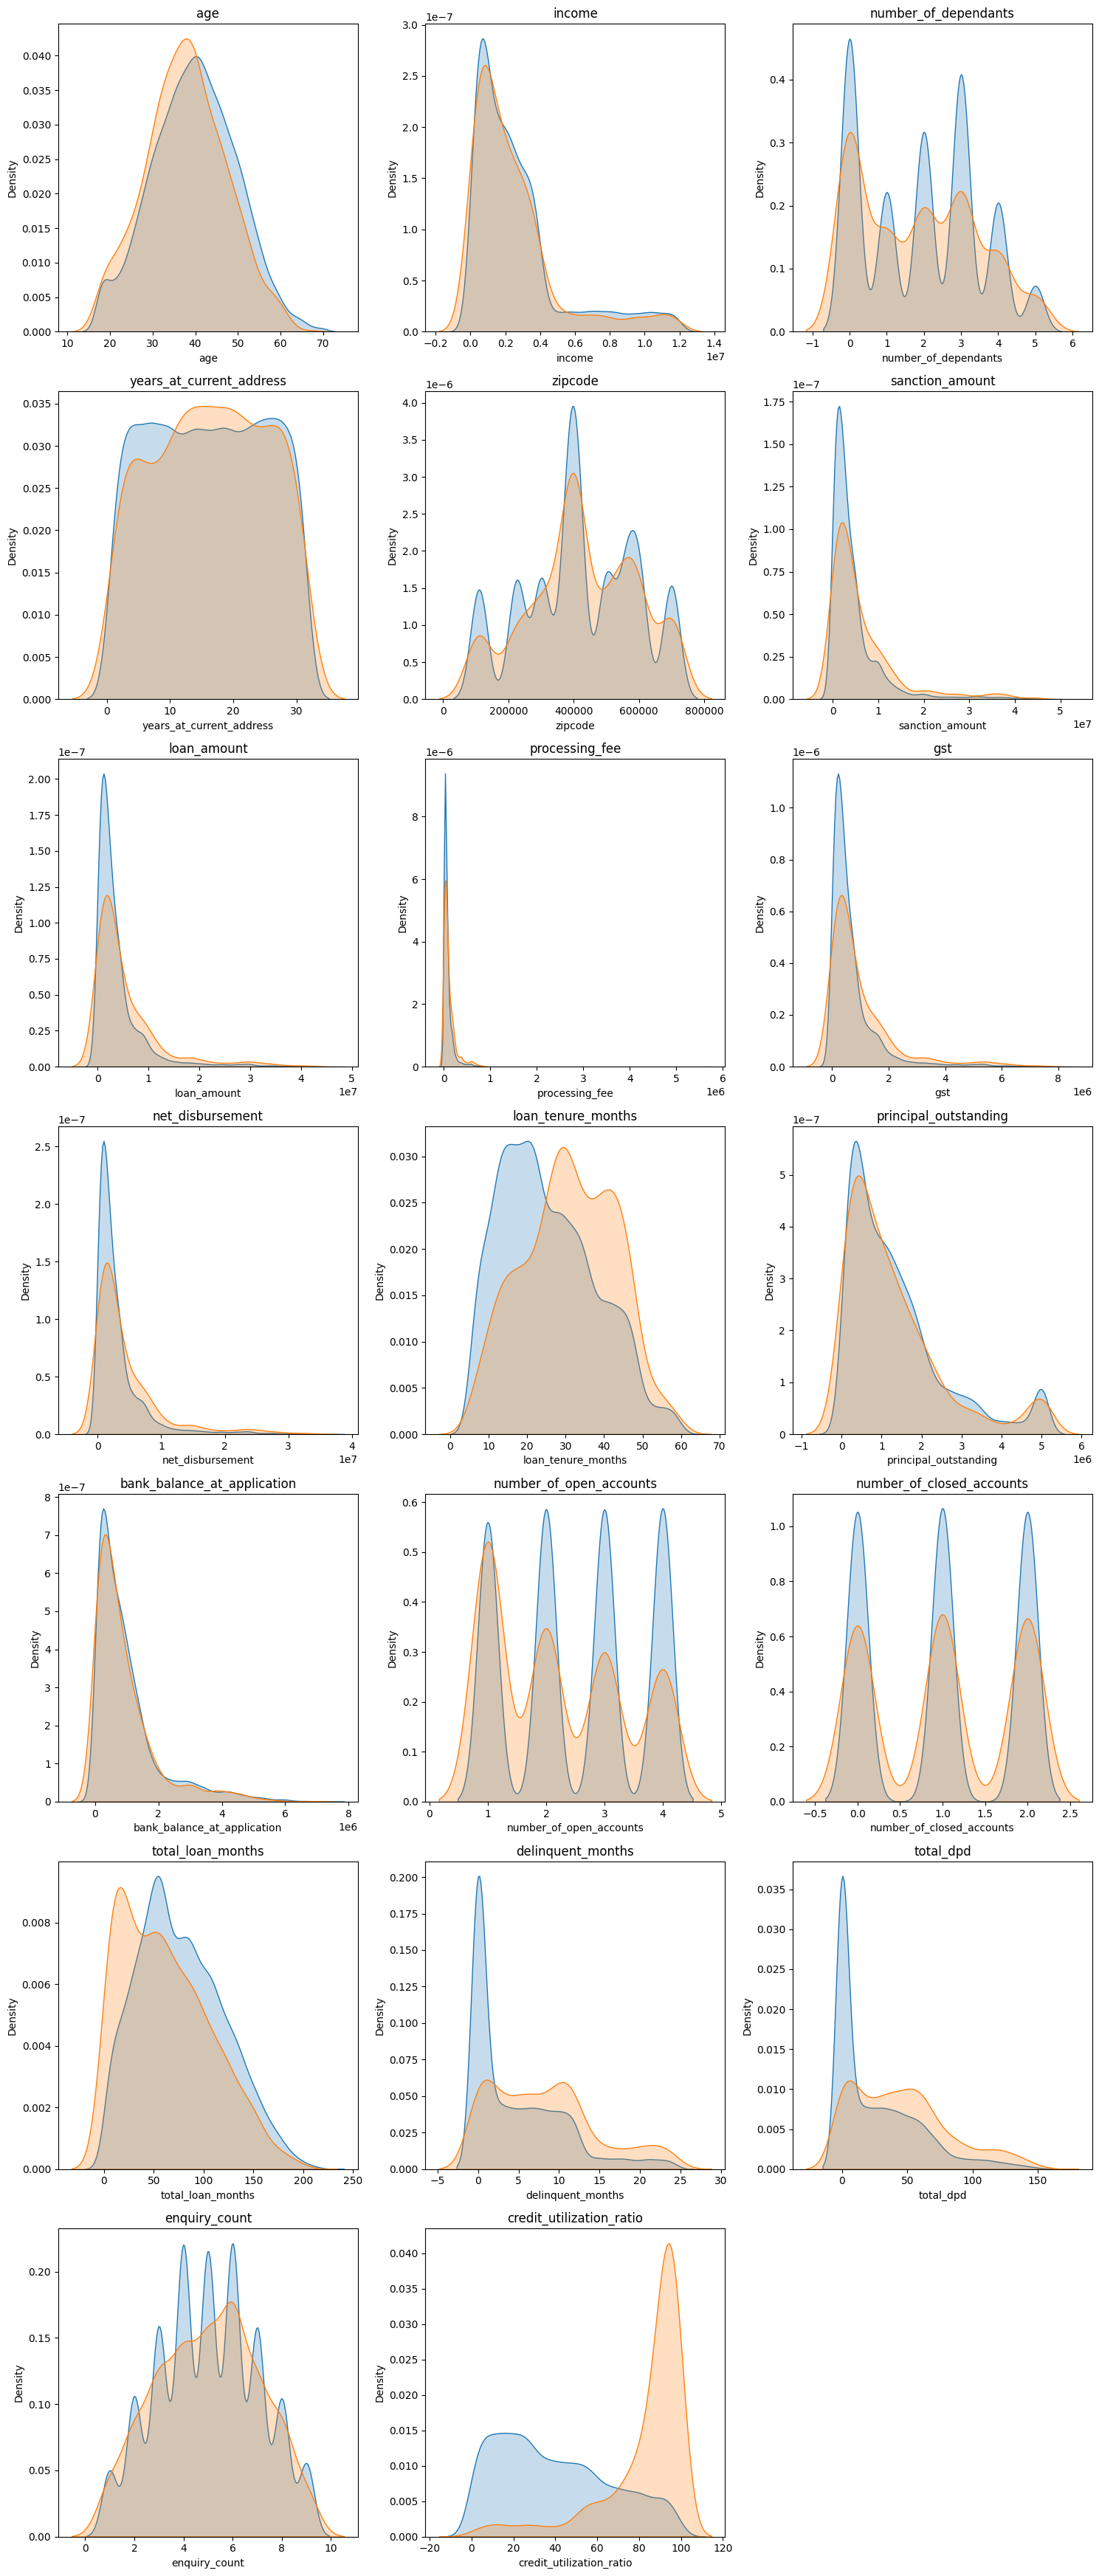

In [62]:
fig_test, axes_test = plt.subplots(n_rows_test, n_cols_test, figsize=(15, 5*n_rows_test))
axes_test = axes_test.flatten()

for ax, col in zip(axes_test, num_cols_test):
    sns.kdeplot(df_test[df_test.default==0][col],fill=True,label="Default-0",ax=ax)
    sns.kdeplot(df_test[df_test.default==1][col],fill=True,label="Default-1",ax=ax)
    ax.set_title(col)


# remove extra empty plots
for i in range(len(num_cols_test), len(axes_test)):
    fig_test.delaxes(axes_test[i])


plt.tight_layout()
plt.show()

In [63]:
n_cols=3
n_rows=math.ceil(len(num_cols)/n_cols)


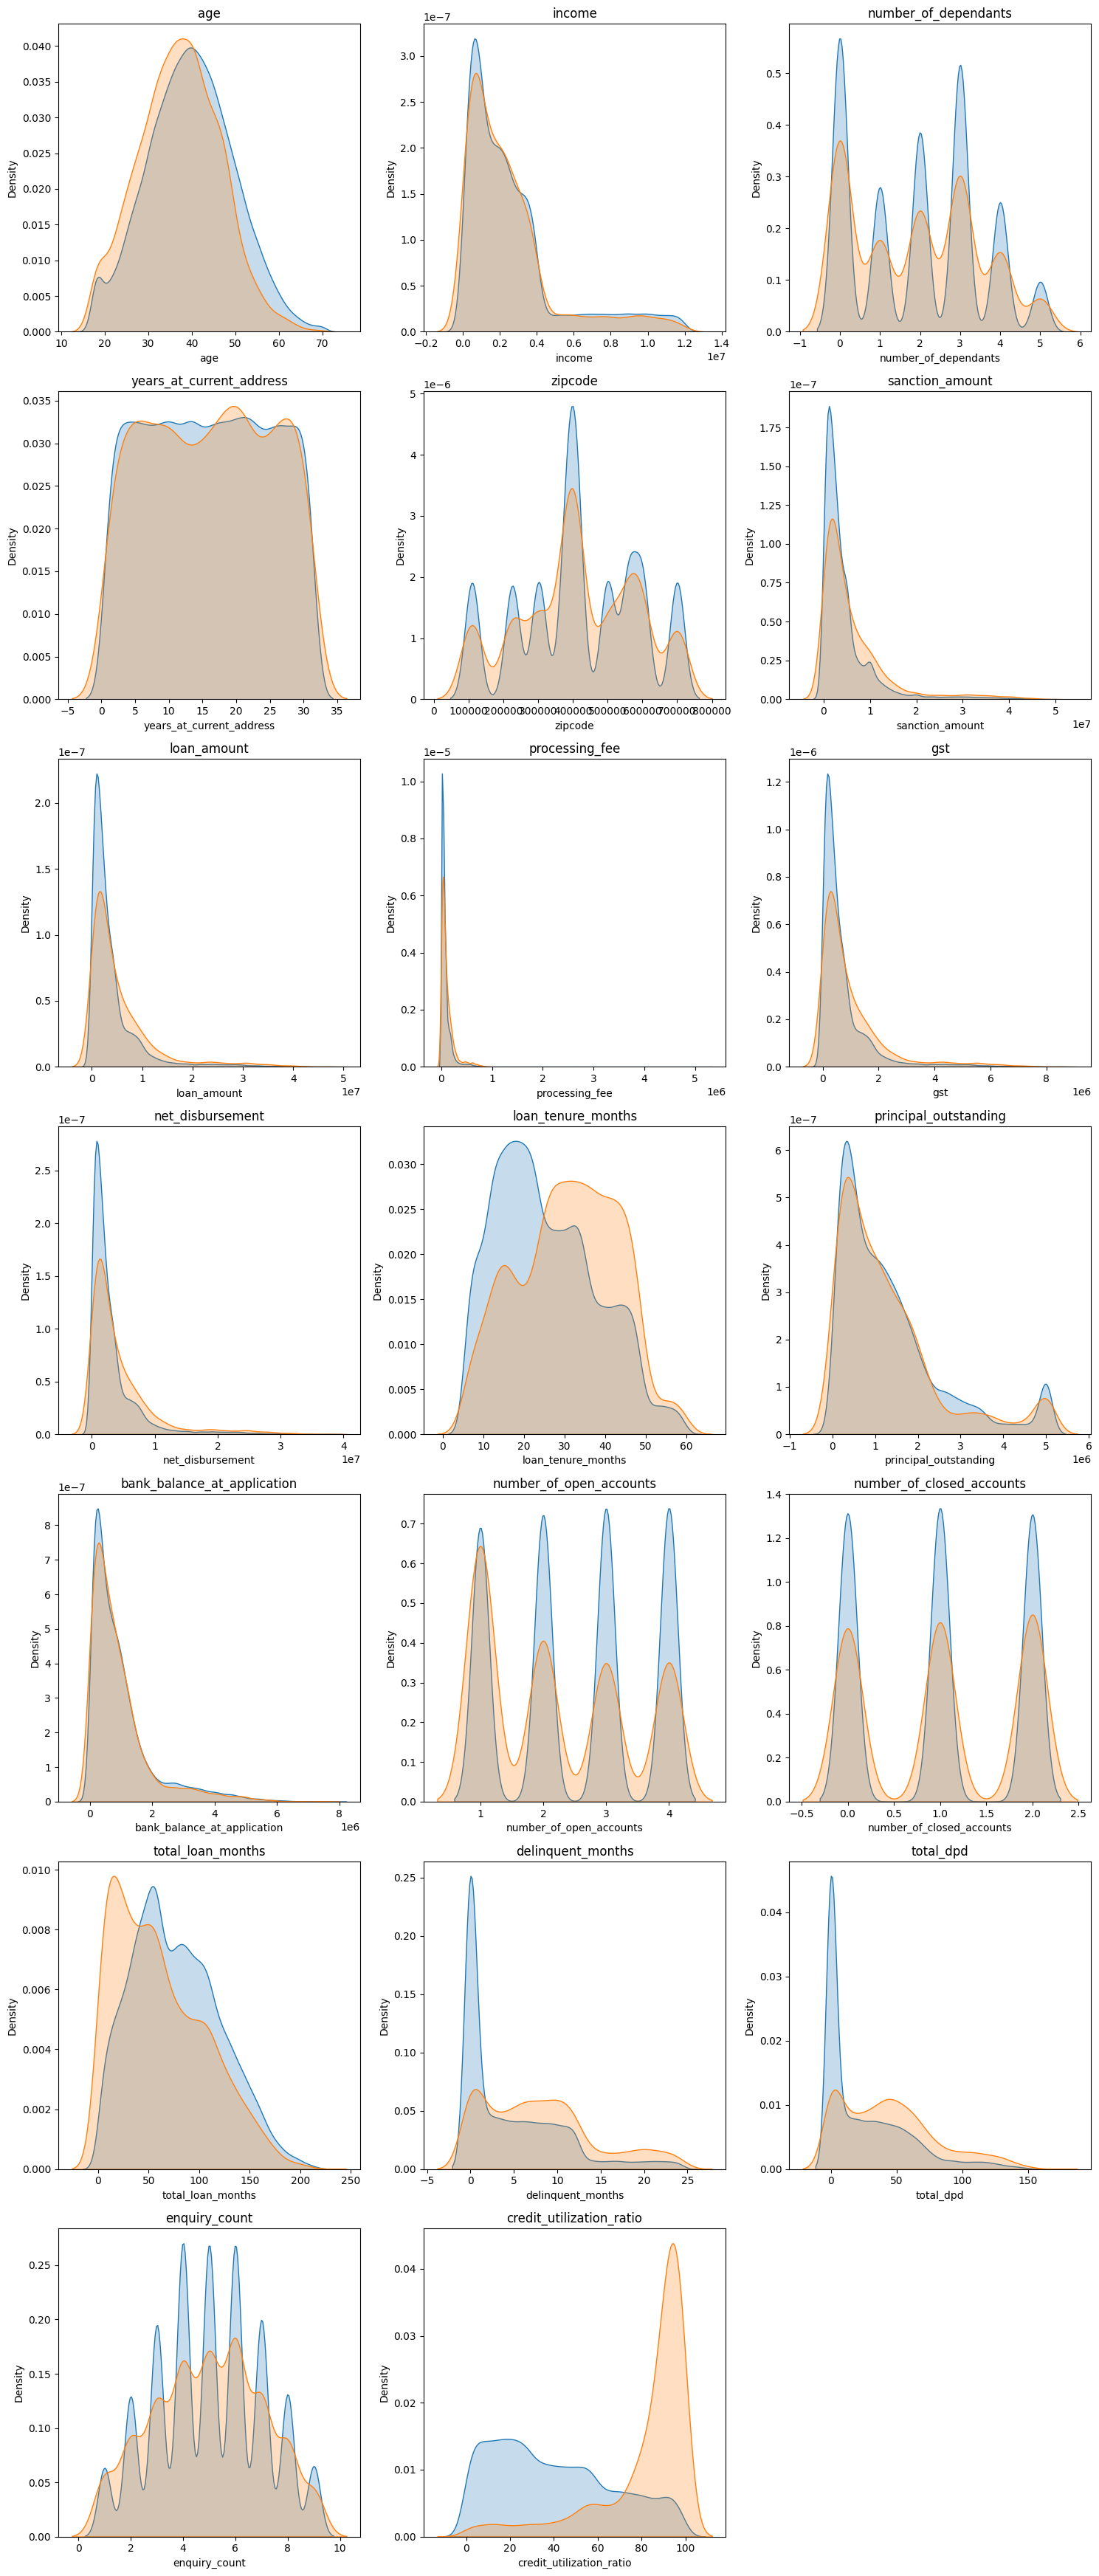

In [64]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.kdeplot(df_train[df_train.default==0][col],fill=True,label="Default-0",ax=ax)
    sns.kdeplot(df_train[df_train.default==1][col],fill=True,label="Default-1",ax=ax)
    ax.set_title(col)


# remove extra empty plots
for i in range(len(num_cols), len(axes)):
    fig.delaxes(axes[i])


plt.tight_layout()
plt.show()

<span style="color:blue">

- There are 5 rows which have processing fee heigher than the loan amount, that's a case of outliers.
- Seven rows contains nan values, that's also an outliers because processing fee is almost lies between 0.5% to 5%

</span>

In [65]:
m_cols_test=3
m_rows_test=math.ceil(len(cat_cols_test)/n_cols_test)


In [66]:
cat_cols_test = df_test.select_dtypes(include=['object','bool']).columns
cat_cols_test

Index(['gender', 'marital_status', 'employment_status', 'residence_type',
       'city', 'state', 'loan_purpose', 'loan_type', 'disbursal_date',
       'installment_start_dt', 'default'],
      dtype='object')

In [67]:
# print(X_train['processing_fee'].corr(X_train['loan_amount']))
(((df_test['processing_fee'] / df_test['loan_amount']) * 100)).isna().sum(),(((df_test['processing_fee'] / df_test['loan_amount']) * 100)>3).sum()
# print(X_train['processing_fee_pct'].describe())

(np.int64(1), np.int64(2))

In [68]:
m_cols=3
m_rows=math.ceil(len(cat_cols)/m_cols)


In [69]:
cat_cols = df_train.select_dtypes(include=['object','bool']).columns
cat_cols

Index(['gender', 'marital_status', 'employment_status', 'residence_type',
       'city', 'state', 'loan_purpose', 'loan_type', 'disbursal_date',
       'installment_start_dt', 'default'],
      dtype='object')

In [70]:
# print(X_train['processing_fee'].corr(X_train['loan_amount']))
(((df_train['processing_fee'] / df_train['loan_amount']) * 100)).isna().sum(),(((df_train['processing_fee'] / df_train['loan_amount']) * 100)>3).sum()
# print(X_train['processing_fee_pct'].describe())

(np.int64(7), np.int64(5))

<span style="color:blue">

## Checking loan to income ratio

</span>

In [71]:
df_test.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'disbursal_date', 'installment_start_dt',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'default'],
      dtype='object')

In [72]:
df_train.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'disbursal_date', 'installment_start_dt',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'default'],
      dtype='object')

In [73]:
df_test['loan_to_income_ratio']=round(df_test['loan_amount']*100/df_test['income'],2)

In [74]:
df_train['loan_to_income_ratio']=round(df_train['loan_amount']*100/df_train['income'],2)

<span style="color:blue">

 - **Insights:** From the below visualization, the orange graph is shifted right, and there are little spike that, it means those who have hieger loan amount to income ratio, they are have higher default cases with respect to normal.

</span>

<Axes: xlabel='loan_to_income_ratio', ylabel='Density'>

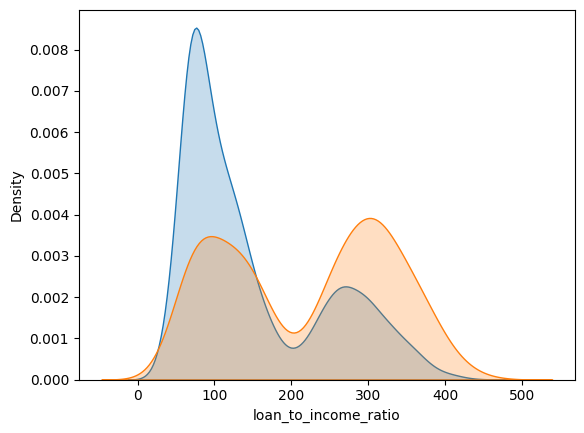

In [75]:
sns.kdeplot(df_test[df_test.default==0]['loan_to_income_ratio'],fill=True,label="Default-0")
sns.kdeplot(df_test[df_test.default==1]['loan_to_income_ratio'],fill=True,label="Default-1")

<Axes: xlabel='loan_to_income_ratio', ylabel='Density'>

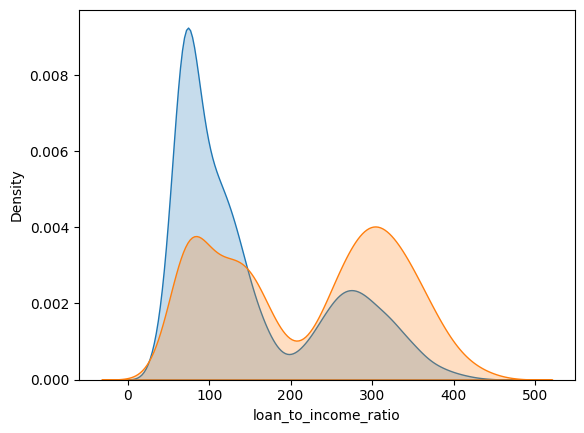

In [76]:
sns.kdeplot(df_train[df_train.default==0]['loan_to_income_ratio'],fill=True,label="Default-0")
sns.kdeplot(df_train[df_train.default==1]['loan_to_income_ratio'],fill=True,label="Default-1")

In [77]:
df_test['delinquent_total_loanmonth_ratio']=round(df_test['delinquent_months']*100/df_test['total_loan_months'],2)
df_test.head(2)

,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,...,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default,loan_to_income_ratio,delinquent_total_loanmonth_ratio
19205,36,M,Married,Self-Employed,3728000,3,Owned,24,Jaipur,Rajasthan,...,2,1,42,0,0,5,98,False,265.29,0.0
15514,43,F,Single,Self-Employed,2493000,0,Owned,23,Delhi,Delhi,...,4,0,125,0,0,5,32,False,123.83,0.0


In [78]:
df_train['delinquent_total_loanmonth_ratio']=round(df_train['delinquent_months']*100/df_train['total_loan_months'],2)
df_train.head(2)

,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,...,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default,loan_to_income_ratio,delinquent_total_loanmonth_ratio
12746,59,M,Married,Self-Employed,11327000,3,Owned,30,Hyderabad,Telangana,...,4,2,152,20,118,4,36,False,206.96,13.16
32495,44,F,Single,Salaried,715000,0,Owned,27,Mumbai,Maharashtra,...,3,1,160,10,62,5,5,False,160.70,6.25


<Axes: xlabel='delinquent_total_loanmonth_ratio', ylabel='Density'>

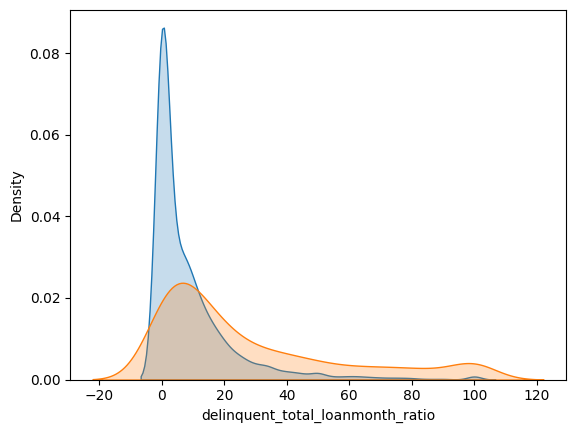

In [79]:
sns.kdeplot(df_test[df_test.default==0]['delinquent_total_loanmonth_ratio'],fill=True,label="Default-0")
sns.kdeplot(df_test[df_test.default==1]['delinquent_total_loanmonth_ratio'],fill=True,label="Default-1")

<Axes: xlabel='delinquent_total_loanmonth_ratio', ylabel='Density'>

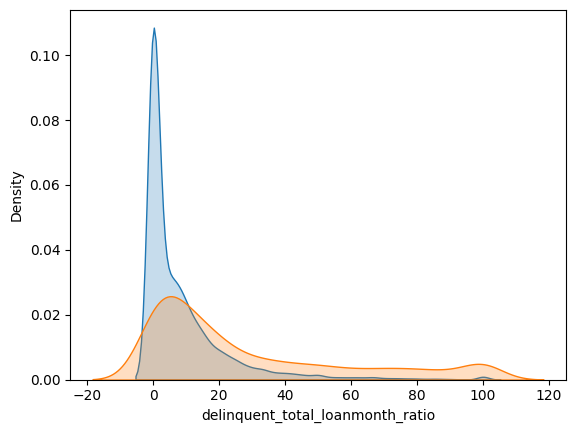

In [80]:
sns.kdeplot(df_train[df_train.default==0]['delinquent_total_loanmonth_ratio'],fill=True,label="Default-0")
sns.kdeplot(df_train[df_train.default==1]['delinquent_total_loanmonth_ratio'],fill=True,label="Default-1")

<span style="color:blue">

- From the above visualization, those who have lower delinquent to loan month ratio, there have less default ratio.

</span>

In [81]:
df_test['avg_dpd_delinquent_ratio']=np.where(
    df_test['delinquent_months']!=0,(
    round(df_test['total_dpd']/df_test['delinquent_months'],2)),0)
df_test['avg_dpd_delinquent_ratio'].describe()

count    12500.000000
mean         3.337814
std          2.896997
min          0.000000
25%          0.000000
50%          4.400000
75%          5.750000
max         10.000000
Name: avg_dpd_delinquent_ratio, dtype: float64

In [82]:
df_train['avg_dpd_delinquent_ratio']=np.where(
    df_train['delinquent_months']!=0,(
    round(df_train['total_dpd']/df_train['delinquent_months'],2)),0)
df_train['avg_dpd_delinquent_ratio'].describe()

count    37500.000000
mean         3.284252
std          2.906640
min          0.000000
25%          0.000000
50%          4.330000
75%          5.742500
max         10.000000
Name: avg_dpd_delinquent_ratio, dtype: float64

<Axes: xlabel='avg_dpd_delinquent_ratio', ylabel='Density'>

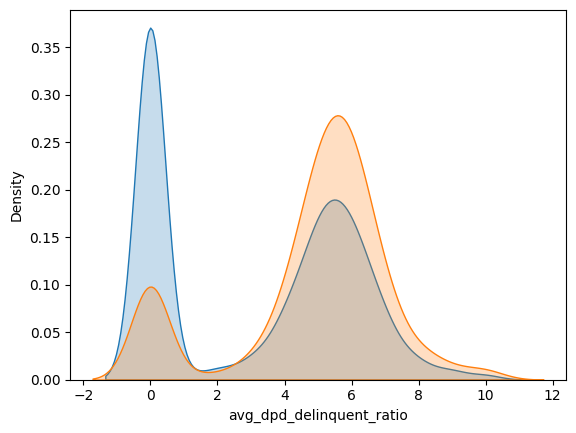

In [83]:
sns.kdeplot(df_test[df_test.default==0]['avg_dpd_delinquent_ratio'],fill=True,label="Default-0")
sns.kdeplot(df_test[df_test.default==1]['avg_dpd_delinquent_ratio'],fill=True,label="Default-1")

<Axes: xlabel='avg_dpd_delinquent_ratio', ylabel='Density'>

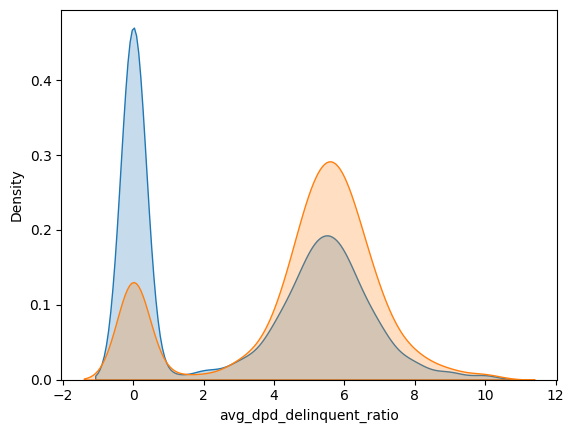

In [84]:
sns.kdeplot(df_train[df_train.default==0]['avg_dpd_delinquent_ratio'],fill=True,label="Default-0")
sns.kdeplot(df_train[df_train.default==1]['avg_dpd_delinquent_ratio'],fill=True,label="Default-1")

<span style="color:blue">

- From the above visualization, we can conclude that people how have higher avg_dpd, those are risky, and they have higher default cases.

</span>

<span style="color:blue">

## Feature Selection

### Multicolinearity and VIF (Variance Inflation Factor)

- There are some feature, which does not carry any information that need to remove such as loan id, customer id etc.
- Few featues need to remove based on the suggestion given SME.
- Checking collinarity using the heatmap

</span>

In [85]:
df_test.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'disbursal_date', 'installment_start_dt',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'default', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio'],
      dtype='object')

In [86]:
df_train.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'disbursal_date', 'installment_start_dt',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'default', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio'],
      dtype='object')

In [87]:
numeric_cols_test = df_test.select_dtypes(include='number').columns
numeric_cols_test

Index(['age', 'income', 'number_of_dependants', 'years_at_current_address',
       'zipcode', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio',
       'loan_to_income_ratio', 'delinquent_total_loanmonth_ratio',
       'avg_dpd_delinquent_ratio'],
      dtype='object')

In [88]:
numeric_cols = df_train.select_dtypes(include='number').columns
numeric_cols

Index(['age', 'income', 'number_of_dependants', 'years_at_current_address',
       'zipcode', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio',
       'loan_to_income_ratio', 'delinquent_total_loanmonth_ratio',
       'avg_dpd_delinquent_ratio'],
      dtype='object')

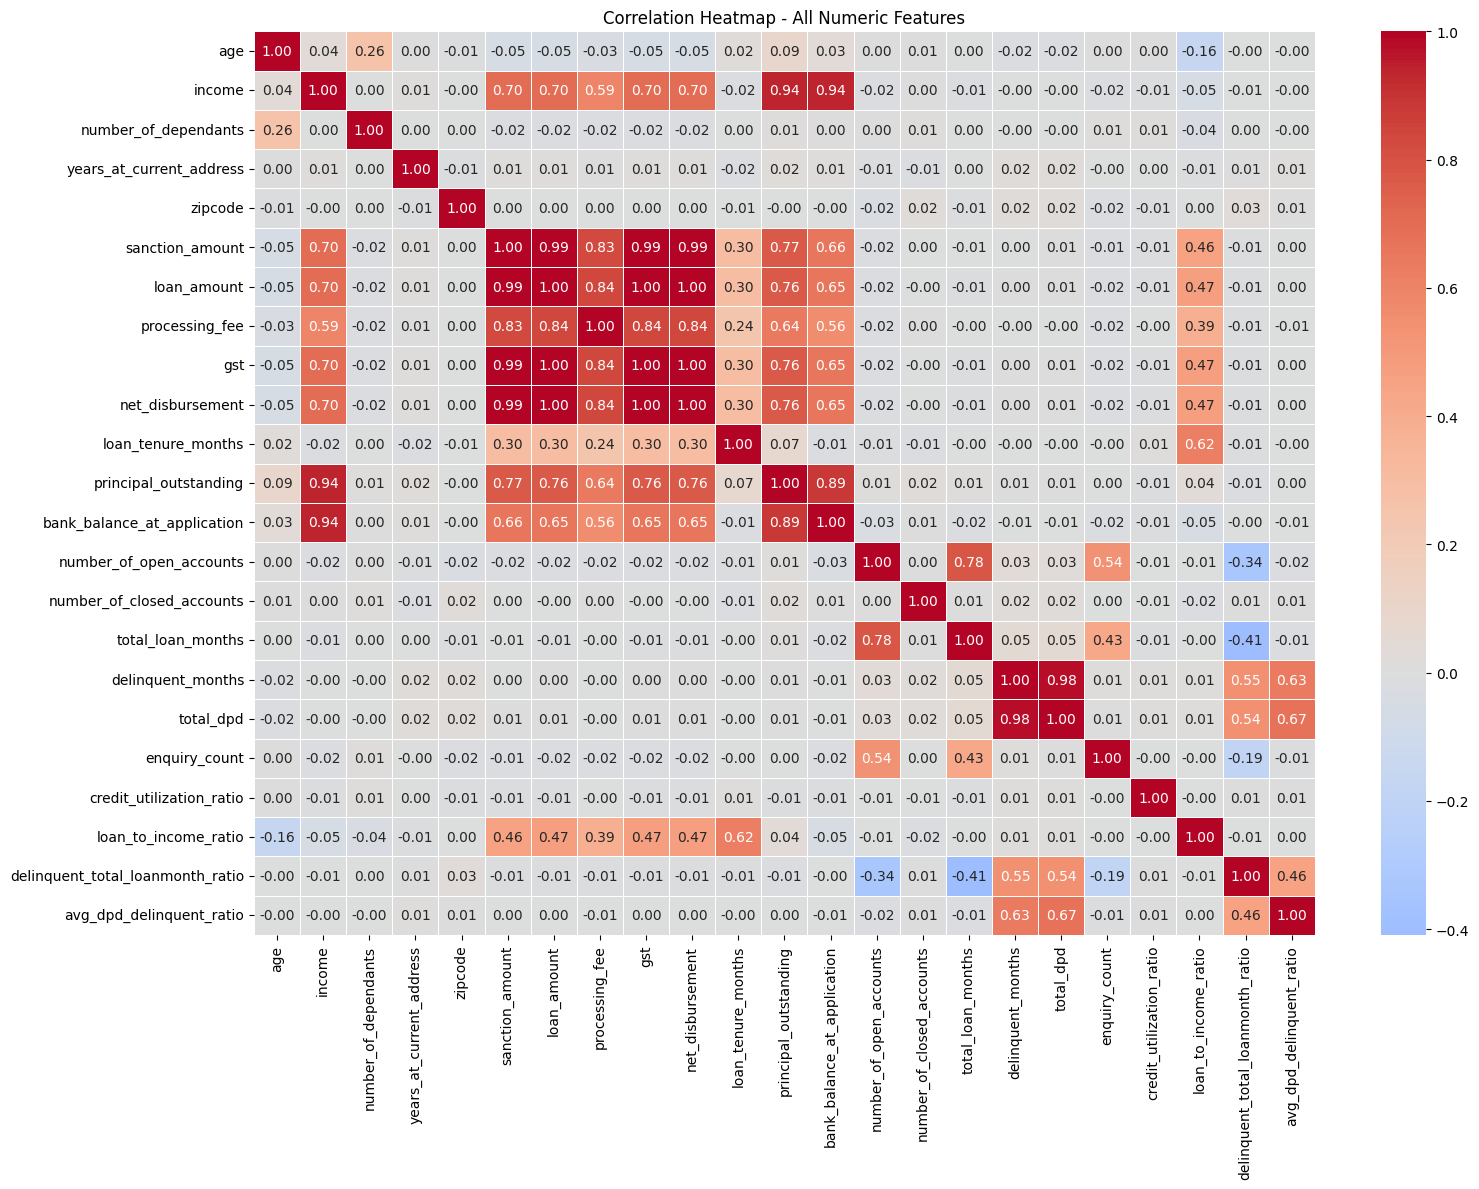

In [89]:
# Only numeric columns

plt.figure(figsize=(16, 12))
sns.heatmap(df_test[numeric_cols_test].corr(), 
            annot=True,          # show numbers
            fmt='.2f',           # 2 decimal places
            cmap='coolwarm',     # red=high, blue=low correlation
            center=0,
            linewidths=0.5)

plt.title('Correlation Heatmap - All Numeric Features')
plt.tight_layout()
plt.show()

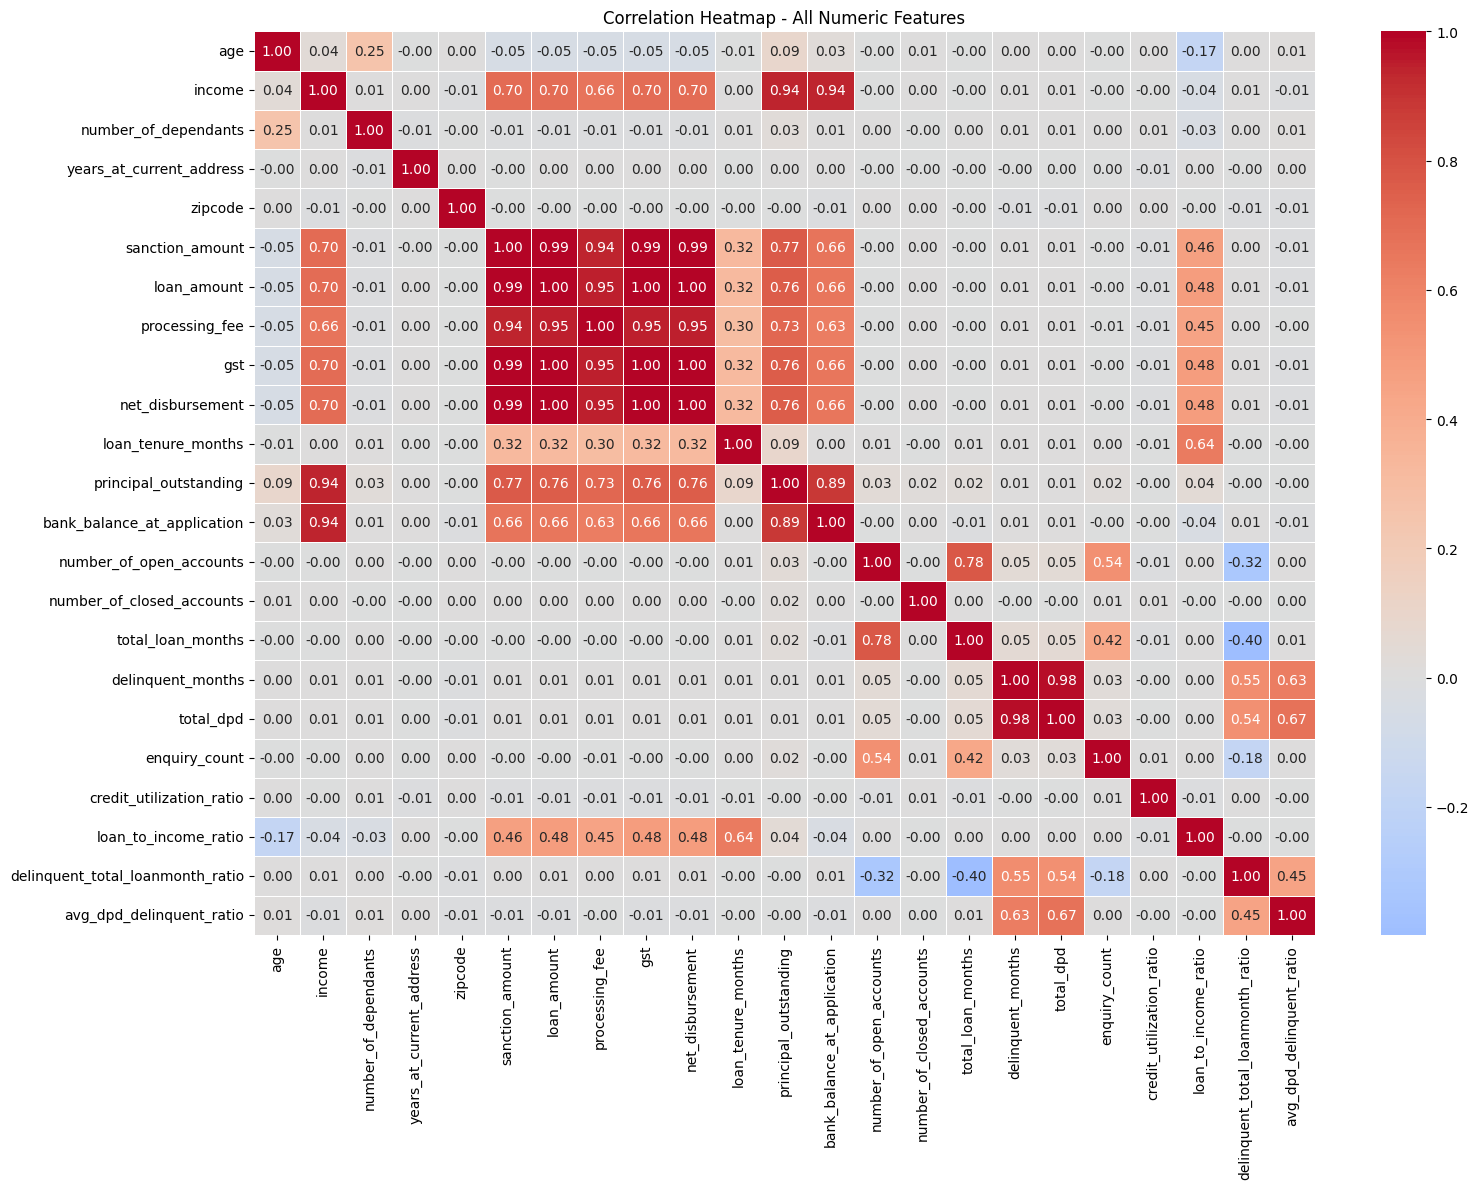

In [90]:
# Only numeric columns

plt.figure(figsize=(16, 12))
sns.heatmap(df_train[numeric_cols].corr(), 
            annot=True,          # show numbers
            fmt='.2f',           # 2 decimal places
            cmap='coolwarm',     # red=high, blue=low correlation
            center=0,
            linewidths=0.5)

plt.title('Correlation Heatmap - All Numeric Features')
plt.tight_layout()
plt.show()

- bank_balance_at_application vs income = 0.94
- principle_outstanding vs income = 0.94


In [91]:
cor_matrix_test=df_test[numeric_cols_test].corr()
for row_index,row in cor_matrix_test.iterrows():
   for col_name,val in row.items():
       if val < -0.09:
           print(f"{row_index} vs {col_name} :{val}")

age vs loan_to_income_ratio :-0.15956146814840846
number_of_open_accounts vs delinquent_total_loanmonth_ratio :-0.33543600303166493
total_loan_months vs delinquent_total_loanmonth_ratio :-0.4091601747250172
enquiry_count vs delinquent_total_loanmonth_ratio :-0.190020629573961
loan_to_income_ratio vs age :-0.15956146814840846
delinquent_total_loanmonth_ratio vs number_of_open_accounts :-0.33543600303166493
delinquent_total_loanmonth_ratio vs total_loan_months :-0.4091601747250172
delinquent_total_loanmonth_ratio vs enquiry_count :-0.190020629573961


In [92]:
cor_matrix=df_train[numeric_cols].corr()
for row_index,row in cor_matrix.iterrows():
   for col_name,val in row.items():
       if val < -0.09:
           print(f"{row_index} vs {col_name} :{val}")

age vs loan_to_income_ratio :-0.1729243119619731
number_of_open_accounts vs delinquent_total_loanmonth_ratio :-0.32412554174607294
total_loan_months vs delinquent_total_loanmonth_ratio :-0.3985353840974039
enquiry_count vs delinquent_total_loanmonth_ratio :-0.1781345545251782
loan_to_income_ratio vs age :-0.1729243119619731
delinquent_total_loanmonth_ratio vs number_of_open_accounts :-0.32412554174607294
delinquent_total_loanmonth_ratio vs total_loan_months :-0.3985353840974039
delinquent_total_loanmonth_ratio vs enquiry_count :-0.1781345545251782


From the above observation -

- sanction amount - loan amount 
- sanction amount - gst
- sanction amount - net disbursement 
- delinquent_month - total_dpd


In [93]:
cor_matrix_test=df_test[numeric_cols_test].corr()
for row_index,row in cor_matrix_test.iterrows():
   for col_name,val in row.items():
       if (val<0):
           print(f"{row_index} vs {col_name} :{val}")

age vs zipcode :-0.0100291045736045
age vs sanction_amount :-0.04816192195950761
age vs loan_amount :-0.04904389294832802
age vs processing_fee :-0.032537660275607144
age vs gst :-0.049043892948328095
age vs net_disbursement :-0.04904389294832808
age vs delinquent_months :-0.019135843162171835
age vs total_dpd :-0.016778585830863647
age vs loan_to_income_ratio :-0.15956146814840846
age vs delinquent_total_loanmonth_ratio :-0.0013407635085294258
age vs avg_dpd_delinquent_ratio :-0.001696130822202651
income vs zipcode :-0.0021524081213112256
income vs loan_tenure_months :-0.01572931061433679
income vs number_of_open_accounts :-0.022491618330174625
income vs total_loan_months :-0.013256883927149339
income vs delinquent_months :-0.0021318280898705976
income vs total_dpd :-0.0017142127911826451
income vs enquiry_count :-0.018659054523084927
income vs credit_utilization_ratio :-0.01050832740122747
income vs loan_to_income_ratio :-0.047421656912797434
income vs delinquent_total_loanmonth_rati

In [94]:
cor_matrix=df_train[numeric_cols].corr()
for row_index,row in cor_matrix.iterrows():
   for col_name,val in row.items():
       if (val<0):
           print(f"{row_index} vs {col_name} :{val}")

age vs years_at_current_address :-0.001334823401438783
age vs sanction_amount :-0.05423758708895483
age vs loan_amount :-0.053513541854682156
age vs processing_fee :-0.04850026060055191
age vs gst :-0.05351354185468237
age vs net_disbursement :-0.05351354185468287
age vs loan_tenure_months :-0.005058995411417068
age vs number_of_open_accounts :-0.0027868888594512124
age vs total_loan_months :-0.0024329028989532467
age vs enquiry_count :-0.00092244882011574
age vs loan_to_income_ratio :-0.1729243119619731
income vs zipcode :-0.006502930034128383
income vs number_of_open_accounts :-0.0007910771649343523
income vs total_loan_months :-0.004388701578683729
income vs enquiry_count :-0.001990287552572567
income vs credit_utilization_ratio :-0.002440802854192807
income vs loan_to_income_ratio :-0.04031364445334664
income vs avg_dpd_delinquent_ratio :-0.006839092983792175
number_of_dependants vs years_at_current_address :-0.013433919370584236
number_of_dependants vs zipcode :-0.0015172130116668

In [95]:
print(df_test['avg_dpd_delinquent_ratio'].isna().sum())
print(df_test['delinquent_total_loanmonth_ratio'].isna().sum())
print((df_test['avg_dpd_delinquent_ratio'] == float('inf')).sum())

0
0
0


In [96]:
print(df_train['avg_dpd_delinquent_ratio'].isna().sum())
print(df_train['delinquent_total_loanmonth_ratio'].isna().sum())
print((df_train['avg_dpd_delinquent_ratio'] == float('inf')).sum())

0
0
0


In [97]:
df_test.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'disbursal_date', 'installment_start_dt',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'default', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio'],
      dtype='object')

In [98]:
df_test.shape

(12500, 34)

In [99]:
df_train.shape

(37500, 34)

In [100]:
df_train.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'disbursal_date', 'installment_start_dt',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'default', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio'],
      dtype='object')

In [101]:
cols_to_drop = ['zipcode',
                'processing_fee', 'loan_amount', 
                'gst', 'net_disbursement',
                ]
new_df_train = df_train.drop(columns=cols_to_drop)

In [102]:
new_df_test = df_test.drop(columns=cols_to_drop)

In [103]:
new_df_train.shape

(37500, 29)

In [104]:
new_df_test.shape

(12500, 29)

In [105]:
new_df_test.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'loan_purpose', 'loan_type', 'sanction_amount',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'disbursal_date', 'installment_start_dt',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'default', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio'],
      dtype='object')

In [106]:
new_df_train.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'loan_purpose', 'loan_type', 'sanction_amount',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'disbursal_date', 'installment_start_dt',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'default', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio'],
      dtype='object')

In [107]:
new_df_train = df_train.drop(columns=['disbursal_date', 'installment_start_dt'])
new_df_test = df_test.drop(columns=['disbursal_date', 'installment_start_dt'])

In [108]:
print(new_df_test[['loan_tenure_months', 'total_loan_months']].corr())
print(new_df_test[['loan_tenure_months', 'total_loan_months']].describe())

                    loan_tenure_months  total_loan_months
loan_tenure_months            1.000000          -0.001034
total_loan_months            -0.001034           1.000000
       loan_tenure_months  total_loan_months
count        12500.000000       12500.000000
mean            25.878960          76.175440
std             12.390517          43.746025
min              6.000000           1.000000
25%             16.000000          43.000000
50%             24.000000          71.000000
75%             35.000000         107.000000
max             59.000000         221.000000


In [109]:
print(new_df_train[['loan_tenure_months', 'total_loan_months']].corr())
print(new_df_train[['loan_tenure_months', 'total_loan_months']].describe())

                    loan_tenure_months  total_loan_months
loan_tenure_months              1.0000             0.0095
total_loan_months               0.0095             1.0000
       loan_tenure_months  total_loan_months
count        37500.000000        37500.00000
mean            25.961040           76.11104
std             12.447444           43.76852
min              6.000000            1.00000
25%             16.000000           42.00000
50%             24.000000           71.00000
75%             35.000000          107.00000
max             59.000000          223.00000


In [110]:
new_df_test.isna().sum()

age                                 0
gender                              0
marital_status                      0
employment_status                   0
income                              0
number_of_dependants                0
residence_type                      0
years_at_current_address            0
city                                0
state                               0
zipcode                             0
loan_purpose                        0
loan_type                           0
sanction_amount                     0
loan_amount                         0
processing_fee                      0
gst                                 0
net_disbursement                    0
loan_tenure_months                  0
principal_outstanding               0
bank_balance_at_application         0
number_of_open_accounts             0
number_of_closed_accounts           0
total_loan_months                   0
delinquent_months                   0
total_dpd                           0
enquiry_coun

In [111]:
new_df_train.isna().sum()

age                                 0
gender                              0
marital_status                      0
employment_status                   0
income                              0
number_of_dependants                0
residence_type                      0
years_at_current_address            0
city                                0
state                               0
zipcode                             0
loan_purpose                        0
loan_type                           0
sanction_amount                     0
loan_amount                         0
processing_fee                      0
gst                                 0
net_disbursement                    0
loan_tenure_months                  0
principal_outstanding               0
bank_balance_at_application         0
number_of_open_accounts             0
number_of_closed_accounts           0
total_loan_months                   0
delinquent_months                   0
total_dpd                           0
enquiry_coun

In [112]:
new_df_test[new_df_test['loan_to_income_ratio'].isna()]

,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,...,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default,loan_to_income_ratio,delinquent_total_loanmonth_ratio,avg_dpd_delinquent_ratio
4950,42,M,Married,Salaried,0,3,Mortgage,13,Bangalore,Karnataka,...,0,142,0,0,7,37,False,NaN,0.0,0.0


In [113]:
new_df_train[new_df_train['loan_to_income_ratio'].isna()]

,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,...,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default,loan_to_income_ratio,delinquent_total_loanmonth_ratio,avg_dpd_delinquent_ratio
45224,43,M,Married,Salaried,0,4,Mortgage,30,Chennai,Tamil Nadu,...,1,112,10,53,7,30,False,NaN,8.93,5.30
2278,46,M,Married,Self-Employed,0,2,Rented,26,Pune,Maharashtra,...,2,129,0,0,7,15,False,NaN,0.00,0.00
11092,39,F,Single,Salaried,0,0,Rented,17,Chennai,Tamil Nadu,...,1,67,0,0,5,12,False,NaN,0.00,0.00
46640,28,F,Married,Salaried,0,4,Rented,24,Jaipur,Rajasthan,...,0,73,0,0,6,30,False,NaN,0.00,0.00
47428,27,M,Single,Self-Employed,0,0,Owned,19,Lucknow,Uttar Pradesh,...,0,99,15,87,4,37,False,NaN,15.15,5.80
13356,34,F,Single,Self-Employed,0,1,Owned,2,Delhi,Delhi,...,2,63,22,125,3,28,False,NaN,34.92,5.68
27457,48,F,Married,Self-Employed,0,3,Owned,5,Pune,Maharashtra,...,1,72,0,0,7,89,False,NaN,0.00,0.00


In [114]:
new_df_test=new_df_test[new_df_test.income>0].copy()

In [115]:
new_df_train=new_df_train[new_df_train.income>0].copy()

In [116]:
# How many rows have income = 0?
print((new_df_test['income'] == 0).sum())

# How many rows have income = NaN?
print(new_df_test['income'].isna().sum())

0
0


In [117]:
# How many rows have income = 0?
print((new_df_train['income'] == 0).sum())

# How many rows have income = NaN?
print(new_df_train['income'].isna().sum())

0
0


In [118]:
new_df_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12499 entries, 19205 to 26116
Data columns (total 32 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   age                               12499 non-null  int64  
 1   gender                            12499 non-null  object 
 2   marital_status                    12499 non-null  object 
 3   employment_status                 12499 non-null  object 
 4   income                            12499 non-null  int64  
 5   number_of_dependants              12499 non-null  int64  
 6   residence_type                    12499 non-null  object 
 7   years_at_current_address          12499 non-null  int64  
 8   city                              12499 non-null  object 
 9   state                             12499 non-null  object 
 10  zipcode                           12499 non-null  int64  
 11  loan_purpose                      12499 non-null  object 
 12  loan_

In [119]:
new_df_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 37493 entries, 12746 to 37784
Data columns (total 32 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   age                               37493 non-null  int64  
 1   gender                            37493 non-null  object 
 2   marital_status                    37493 non-null  object 
 3   employment_status                 37493 non-null  object 
 4   income                            37493 non-null  int64  
 5   number_of_dependants              37493 non-null  int64  
 6   residence_type                    37493 non-null  object 
 7   years_at_current_address          37493 non-null  int64  
 8   city                              37493 non-null  object 
 9   state                             37493 non-null  object 
 10  zipcode                           37493 non-null  int64  
 11  loan_purpose                      37493 non-null  object 
 12  loan_

In [120]:
new_df_test['default'] = new_df_test['default'].astype('int32')
new_df_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12499 entries, 19205 to 26116
Data columns (total 32 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   age                               12499 non-null  int64  
 1   gender                            12499 non-null  object 
 2   marital_status                    12499 non-null  object 
 3   employment_status                 12499 non-null  object 
 4   income                            12499 non-null  int64  
 5   number_of_dependants              12499 non-null  int64  
 6   residence_type                    12499 non-null  object 
 7   years_at_current_address          12499 non-null  int64  
 8   city                              12499 non-null  object 
 9   state                             12499 non-null  object 
 10  zipcode                           12499 non-null  int64  
 11  loan_purpose                      12499 non-null  object 
 12  loan_

In [121]:
new_df_train['default'] = new_df_train['default'].astype('int32')
new_df_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 37493 entries, 12746 to 37784
Data columns (total 32 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   age                               37493 non-null  int64  
 1   gender                            37493 non-null  object 
 2   marital_status                    37493 non-null  object 
 3   employment_status                 37493 non-null  object 
 4   income                            37493 non-null  int64  
 5   number_of_dependants              37493 non-null  int64  
 6   residence_type                    37493 non-null  object 
 7   years_at_current_address          37493 non-null  int64  
 8   city                              37493 non-null  object 
 9   state                             37493 non-null  object 
 10  zipcode                           37493 non-null  int64  
 11  loan_purpose                      37493 non-null  object 
 12  loan_

In [122]:
x_train=new_df_train.drop('default',axis='columns')
y_train=new_df_train['default']

In [123]:
x_test=new_df_test.drop('default',axis='columns')
y_test=new_df_test['default']

## Feature Scaling

In [124]:
from sklearn.preprocessing import MinMaxScaler

In [125]:
new_df_train.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default',
       'loan_to_income_ratio', 'delinquent_total_loanmonth_ratio',
       'avg_dpd_delinquent_ratio'],
      dtype='object')

In [126]:
cos_to_scale=new_df_train.select_dtypes(["int64","float64"]).columns

In [127]:
scaler=MinMaxScaler()

In [128]:
x_train[cos_to_scale]=scaler.fit_transform(x_train[cos_to_scale])
x_train.describe()

,age,income,number_of_dependants,years_at_current_address,zipcode,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,...,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,loan_to_income_ratio,delinquent_total_loanmonth_ratio,avg_dpd_delinquent_ratio
count,37493.000000,37493.000000,37493.000000,37493.000000,37493.000000,37493.000000,37493.000000,37493.000000,37493.000000,37493.000000,...,37493.000000,37493.000000,37493.000000,37493.000000,37493.000000,37493.000000,37493.000000,37493.000000,37493.000000,37493.000000
mean,0.414248,0.212944,0.388905,0.499916,0.523513,0.088835,0.082508,0.014962,0.082508,0.082508,...,0.500938,0.500560,0.338328,0.201854,0.155968,0.501054,0.438652,0.294947,0.103298,0.328442
std,0.189590,0.220504,0.307186,0.297362,0.286498,0.120110,0.112474,0.021376,0.112474,0.112474,...,0.373028,0.407016,0.197167,0.243365,0.191670,0.253663,0.296905,0.228171,0.172975,0.290664
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.288462,0.059081,0.000000,0.233333,0.325424,0.020555,0.018969,0.003424,0.018969,0.018969,...,0.000000,0.000000,0.184685,0.000000,0.000000,0.375000,0.181818,0.110260,0.000000,0.000000
50%,0.403846,0.150097,0.400000,0.500000,0.491525,0.049364,0.045516,0.008219,0.045516,0.045516,...,0.666667,0.500000,0.315315,0.125000,0.076023,0.500000,0.393939,0.201936,0.036800,0.433000
75%,0.538462,0.271199,0.600000,0.766667,0.762712,0.098017,0.095534,0.017251,0.095534,0.095534,...,1.000000,1.000000,0.477477,0.333333,0.269006,0.625000,0.676768,0.506843,0.129500,0.575000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [129]:
cos_to_scale_test=new_df_test.select_dtypes(["int64","float64"]).columns

In [130]:
x_train.shape

(37493, 31)

In [131]:
x_test.shape

(12499, 31)

In [132]:
x_test[cos_to_scale_test]=scaler.fit_transform(x_test[cos_to_scale_test])
x_test.describe()

,age,income,number_of_dependants,years_at_current_address,zipcode,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,...,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,loan_to_income_ratio,delinquent_total_loanmonth_ratio,avg_dpd_delinquent_ratio
count,12499.000000,12499.000000,12499.000000,12499.000000,12499.000000,12499.000000,12499.000000,12499.000000,12499.000000,12499.000000,...,12499.000000,12499.000000,12499.000000,12499.000000,12499.000000,12499.000000,12499.000000,12499.000000,12499.000000,12499.000000
mean,0.415038,0.215701,0.384895,0.502688,0.525004,0.090942,0.086038,0.014062,0.086038,0.086038,...,0.497266,0.500480,0.341683,0.207560,0.170288,0.501450,0.436076,0.292184,0.106060,0.333808
std,0.188781,0.222642,0.306847,0.298107,0.286157,0.123142,0.117102,0.022654,0.117102,0.117102,...,0.372576,0.407218,0.198836,0.244839,0.204894,0.253608,0.295420,0.224853,0.173074,0.289696
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.288462,0.059566,0.000000,0.233333,0.325424,0.021378,0.020245,0.003272,0.020245,0.020245,...,0.000000,0.000000,0.190909,0.000000,0.000000,0.375000,0.181818,0.111499,0.000000,0.000000
50%,0.423077,0.152617,0.400000,0.500000,0.510169,0.051167,0.048115,0.007776,0.048115,0.048115,...,0.333333,0.500000,0.318182,0.125000,0.093168,0.500000,0.393939,0.201509,0.042100,0.440000
75%,0.538462,0.273599,0.600000,0.766667,0.762712,0.099321,0.098640,0.015945,0.098640,0.098640,...,0.666667,1.000000,0.481818,0.375000,0.291925,0.625000,0.676768,0.497276,0.133600,0.575000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [133]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [134]:
def calculate_VIF(data):
    vif_df=pd.DataFrame()
    vif_df['column']=data.columns
    vif_df['VIF']=[variance_inflation_factor(data.values,i) for i in range(data.shape[1])]
    return vif_df

<span style="color:blue">

- Dropping the columns which having hightest VIF, one by one and recalculating the VIF.
- Because one features relate to others, if dropping one it may reduce other too.
    
</span>

<span style = "color:blue">

##  Highest VIF - Feature Drop  - Iteration 1

</span>

In [135]:
# x_train=x_train.drop('total_dpd',axis=1)
# x_test=new_df_test.drop('default',axis='columns')

In [136]:
calculate_VIF(x_train[cos_to_scale])

C:\Users\Ravindra\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,column,VIF
0,age,5.802202
1,income,35.467110
2,number_of_dependants,2.734401
3,years_at_current_address,3.455123
4,zipcode,3.843721
5,sanction_amount,101.111620
6,loan_amount,inf
7,processing_fee,14.966511
8,gst,inf
9,net_disbursement,inf


In [137]:
calculate_VIF(x_test[cos_to_scale])

C:\Users\Ravindra\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,column,VIF
0,age,5.909837
1,income,34.178731
2,number_of_dependants,2.721200
3,years_at_current_address,3.471887
4,zipcode,3.863292
5,sanction_amount,102.473045
6,loan_amount,inf
7,processing_fee,4.604751
8,gst,inf
9,net_disbursement,inf


In [138]:
cos_to_scale_vif=x_train.select_dtypes(["int64","float64"]).columns
cos_to_scale_vif

Index(['age', 'income', 'number_of_dependants', 'years_at_current_address',
       'zipcode', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio',
       'loan_to_income_ratio', 'delinquent_total_loanmonth_ratio',
       'avg_dpd_delinquent_ratio'],
      dtype='object')

In [139]:
x_train.columns

Index(['age', 'gender', 'marital_status', 'employment_status', 'income',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio',
       'loan_to_income_ratio', 'delinquent_total_loanmonth_ratio',
       'avg_dpd_delinquent_ratio'],
      dtype='object')

In [140]:
x_train_vif=x_train.drop('total_dpd',axis=1)

In [141]:
x_test_vif=x_test.drop('total_dpd',axis=1)

<span style="color:red">

## Dropped column:

- cust_id, loan_id, zip code, loan amount, gst, processing fee, net disbursement amount, total_dpd,

</span>

<span style="color:blue">

- VIF measures how much one column is explained by all other columns combined.
- Total_dpd = 51.29 meant it was almost perfectly predictable from other columns — meaning it was adding noise not signal to the model.

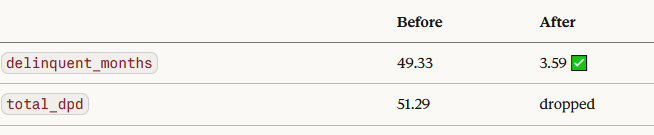

- This proves they were causing each other's high VIF — removing one fixed the other completely. This is exactly why we do VIF iteratively!
</span>

In [142]:
cos_to_scale_vif_test=x_train_vif.select_dtypes(["int64","float64"]).columns
cos_to_scale_vif_test

Index(['age', 'income', 'number_of_dependants', 'years_at_current_address',
       'zipcode', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'enquiry_count', 'credit_utilization_ratio', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio'],
      dtype='object')

In [143]:
cos_to_scale_vif_train=x_train_vif.select_dtypes(["int64","float64"]).columns
cos_to_scale_vif_train

Index(['age', 'income', 'number_of_dependants', 'years_at_current_address',
       'zipcode', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'enquiry_count', 'credit_utilization_ratio', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio'],
      dtype='object')

In [144]:
calculate_VIF(x_test_vif[cos_to_scale_vif_test])

C:\Users\Ravindra\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,column,VIF
0,age,5.909261
1,income,34.174227
2,number_of_dependants,2.721044
3,years_at_current_address,3.471611
4,zipcode,3.862341
5,sanction_amount,102.462746
6,loan_amount,inf
7,processing_fee,4.604665
8,gst,inf
9,net_disbursement,inf


In [145]:
calculate_VIF(x_train_vif[cos_to_scale_vif_train])

C:\Users\Ravindra\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,column,VIF
0,age,5.799147
1,income,35.464736
2,number_of_dependants,2.734200
3,years_at_current_address,3.454257
4,zipcode,3.842096
5,sanction_amount,101.111112
6,loan_amount,inf
7,processing_fee,14.965808
8,gst,inf
9,net_disbursement,inf


<span style = "color:blue">

##  Highest VIF - Feature Drop  - Iteration 2

</span>

In [146]:
x_train_vif_2=x_train_vif.drop('income',axis=1)

In [147]:
cos_to_scale_vif_train_2=x_train_vif_2.select_dtypes(["int64","float64"]).columns
cos_to_scale_vif_train_2

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'enquiry_count', 'credit_utilization_ratio', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio'],
      dtype='object')

In [148]:
calculate_VIF(x_train_vif_2[cos_to_scale_vif_train_2])

C:\Users\Ravindra\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,column,VIF
0,age,5.766250
1,number_of_dependants,2.734008
2,years_at_current_address,3.448876
3,zipcode,3.832748
4,sanction_amount,101.097856
5,loan_amount,inf
6,processing_fee,14.960522
7,gst,inf
8,net_disbursement,inf
9,loan_tenure_months,6.188890


In [149]:
x_test_vif_2=x_test_vif.drop('income',axis=1)

In [150]:
cos_to_scale_vif_test_2=x_test_vif_2.select_dtypes(["int64","float64"]).columns
cos_to_scale_vif_test_2

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'enquiry_count', 'credit_utilization_ratio', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio'],
      dtype='object')

In [151]:
calculate_VIF(x_test_vif_2[cos_to_scale_vif_test_2])

C:\Users\Ravindra\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,column,VIF
0,age,5.878958
1,number_of_dependants,2.720143
2,years_at_current_address,3.465490
3,zipcode,3.854416
4,sanction_amount,102.459771
5,loan_amount,inf
6,processing_fee,4.602926
7,gst,inf
8,net_disbursement,inf
9,loan_tenure_months,6.010960


<span style="color:red">

## Dropped column:

- cust_id, loan_id, zip code, loan amount, gst, processing fee, net disbursement amount, total_dpd,income,

</span>

## After Dropping Income 
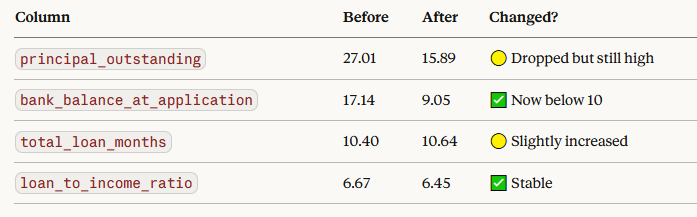

<span style = "color:blue">

##  Highest VIF - Feature Drop  - Iteration 3

- From the above VIF table, - principal_outstanding, still have very high VIF value.
- As here total paid amount is not given, principle outstanding can not be derived from existing column and it carries unique information.
- 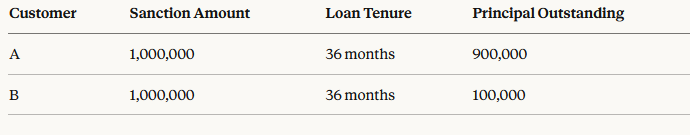
- Customer B has almost finished paying — much lower default risk.
- The VIF is high at 15.89 — but dropping it means losing unique repayment progress information.

</span>

In [152]:
# Create a repayment progress ratio
x_train_vif_2['repayment_progress'] = 1 - (x_train_vif_2['principal_outstanding'] / x_train_vif_2['sanction_amount'])

# Then drop principal_outstanding

In [153]:
# Create a repayment progress ratio
x_test_vif_2['repayment_progress'] = 1 - (x_test_vif_2['principal_outstanding'] / x_test_vif_2['sanction_amount'])

# Then drop principal_outstanding

In [154]:
# How many rows have sanction_amount = 0?
print((x_train_vif_2['sanction_amount'] == 0).sum())

# See those rows
print(x_train_vif_2[x_train_vif_2['sanction_amount'] == 0][['sanction_amount', 'principal_outstanding']])

1
       sanction_amount  principal_outstanding
16224              0.0               0.001178


In [155]:
# How many rows have sanction_amount = 0?
print((x_test_vif_2['sanction_amount'] == 0).sum())

# See those rows
print(x_test_vif_2[x_test_vif_2['sanction_amount'] == 0][['sanction_amount', 'principal_outstanding']])

1
       sanction_amount  principal_outstanding
27208              0.0                    0.0


In [156]:
print(x_train_vif_2.loc[16224])

age                                      0.538462
gender                                          M
marital_status                             Single
employment_status                   Self-Employed
number_of_dependants                          0.0
residence_type                              Owned
years_at_current_address                 0.033333
city                                        Delhi
state                                       Delhi
zipcode                                       0.0
loan_purpose                             Personal
loan_type                               Unsecured
sanction_amount                               0.0
loan_amount                              0.000021
processing_fee                           0.000004
gst                                      0.000021
net_disbursement                         0.000021
loan_tenure_months                       0.075472
principal_outstanding                    0.001178
bank_balance_at_application              0.002321


In [157]:
print(x_test_vif_2.loc[27208])

age                                  0.673077
gender                                      M
marital_status                        Married
employment_status                    Salaried
number_of_dependants                      0.6
residence_type                       Mortgage
years_at_current_address             0.966667
city                                    Delhi
state                                   Delhi
zipcode                                   0.0
loan_purpose                         Personal
loan_type                           Unsecured
sanction_amount                           0.0
loan_amount                               0.0
processing_fee                            0.0
gst                                       0.0
net_disbursement                          0.0
loan_tenure_months                   0.320755
principal_outstanding                     0.0
bank_balance_at_application          0.000377
number_of_open_accounts                   1.0
number_of_closed_accounts         

In [158]:
x_train_vif_2.shape, y_train.shape

((37493, 30), (37493,))

In [159]:
y_train = y_train.drop(index=16224)

In [160]:
x_train_vif_2 = x_train_vif_2.drop(index=16224)


In [161]:
y_test = y_test.drop(index=27208)

In [162]:
x_test_vif_2 = x_test_vif_2.drop(index=27208)

In [163]:
x_train_vif_2.isna().sum()

age                                 0
gender                              0
marital_status                      0
employment_status                   0
number_of_dependants                0
residence_type                      0
years_at_current_address            0
city                                0
state                               0
zipcode                             0
loan_purpose                        0
loan_type                           0
sanction_amount                     0
loan_amount                         0
processing_fee                      0
gst                                 0
net_disbursement                    0
loan_tenure_months                  0
principal_outstanding               0
bank_balance_at_application         0
number_of_open_accounts             0
number_of_closed_accounts           0
total_loan_months                   0
delinquent_months                   0
enquiry_count                       0
credit_utilization_ratio            0
loan_to_inco

In [164]:
x_test_vif_2.isna().sum()

age                                 0
gender                              0
marital_status                      0
employment_status                   0
number_of_dependants                0
residence_type                      0
years_at_current_address            0
city                                0
state                               0
zipcode                             0
loan_purpose                        0
loan_type                           0
sanction_amount                     0
loan_amount                         0
processing_fee                      0
gst                                 0
net_disbursement                    0
loan_tenure_months                  0
principal_outstanding               0
bank_balance_at_application         0
number_of_open_accounts             0
number_of_closed_accounts           0
total_loan_months                   0
delinquent_months                   0
enquiry_count                       0
credit_utilization_ratio            0
loan_to_inco

In [165]:
x_train_vif_3=x_train_vif_2.drop('principal_outstanding',axis=1)

In [166]:
x_test_vif_3=x_test_vif_2.drop('principal_outstanding',axis=1)

In [167]:
x_test_vif_3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12498 entries, 19205 to 26116
Data columns (total 29 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   age                               12498 non-null  float64
 1   gender                            12498 non-null  object 
 2   marital_status                    12498 non-null  object 
 3   employment_status                 12498 non-null  object 
 4   number_of_dependants              12498 non-null  float64
 5   residence_type                    12498 non-null  object 
 6   years_at_current_address          12498 non-null  float64
 7   city                              12498 non-null  object 
 8   state                             12498 non-null  object 
 9   zipcode                           12498 non-null  float64
 10  loan_purpose                      12498 non-null  object 
 11  loan_type                         12498 non-null  object 
 12  sanct

In [168]:
x_train_vif_3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 37492 entries, 12746 to 37784
Data columns (total 29 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   age                               37492 non-null  float64
 1   gender                            37492 non-null  object 
 2   marital_status                    37492 non-null  object 
 3   employment_status                 37492 non-null  object 
 4   number_of_dependants              37492 non-null  float64
 5   residence_type                    37492 non-null  object 
 6   years_at_current_address          37492 non-null  float64
 7   city                              37492 non-null  object 
 8   state                             37492 non-null  object 
 9   zipcode                           37492 non-null  float64
 10  loan_purpose                      37492 non-null  object 
 11  loan_type                         37492 non-null  object 
 12  sanct

In [169]:
cos_to_scale_vif_test_3=x_test_vif_3.select_dtypes(["int64","float64"]).columns
cos_to_scale_vif_test_3

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio',
       'repayment_progress'],
      dtype='object')

In [170]:
calculate_VIF(x_test_vif_3[cos_to_scale_vif_test_3])

C:\Users\Ravindra\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,column,VIF
0,age,7.302570
1,number_of_dependants,2.734747
2,years_at_current_address,3.675331
3,zipcode,4.150430
4,sanction_amount,106.478572
5,loan_amount,inf
6,processing_fee,4.603049
7,gst,inf
8,net_disbursement,inf
9,loan_tenure_months,6.097961


In [171]:
cos_to_scale_vif_train_3=x_train_vif_3.select_dtypes(["int64","float64"]).columns
cos_to_scale_vif_train_3

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio',
       'repayment_progress'],
      dtype='object')

<span style="color:red">

## Dropped column:

- cust_id, loan_id, zip code, loan amount, gst, processing fee, net disbursement amount, total_dpd,

</span>

In [172]:
calculate_VIF(x_train_vif_3[cos_to_scale_vif_train_3])

C:\Users\Ravindra\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,column,VIF
0,age,6.955069
1,number_of_dependants,2.757553
2,years_at_current_address,3.625767
3,zipcode,4.064136
4,sanction_amount,103.915708
5,loan_amount,inf
6,processing_fee,14.960527
7,gst,inf
8,net_disbursement,inf
9,loan_tenure_months,6.247811


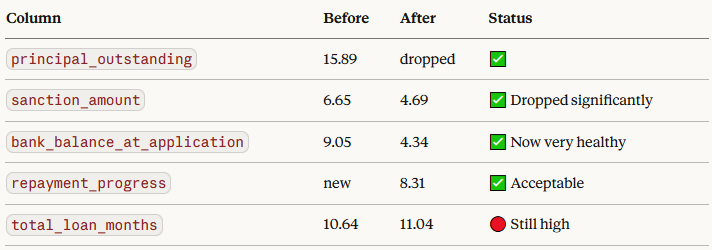

<span style = "color:blue">

##  Highest VIF - Feature Drop  - Iteration 4

</span>

In [173]:
print(x_train_vif_3[['total_loan_months', 'loan_tenure_months']].corr())

                    total_loan_months  loan_tenure_months
total_loan_months            1.000000            0.009509
loan_tenure_months           0.009509            1.000000


In [174]:
print(x_test_vif_3[['total_loan_months', 'loan_tenure_months']].corr())

                    total_loan_months  loan_tenure_months
total_loan_months            1.000000           -0.001064
loan_tenure_months          -0.001064            1.000000


<span style="color:blue">
    
## VIF-Analysis
</span>

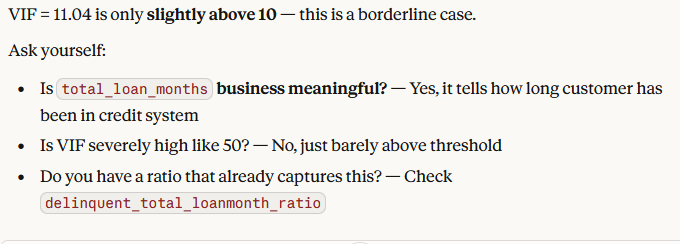

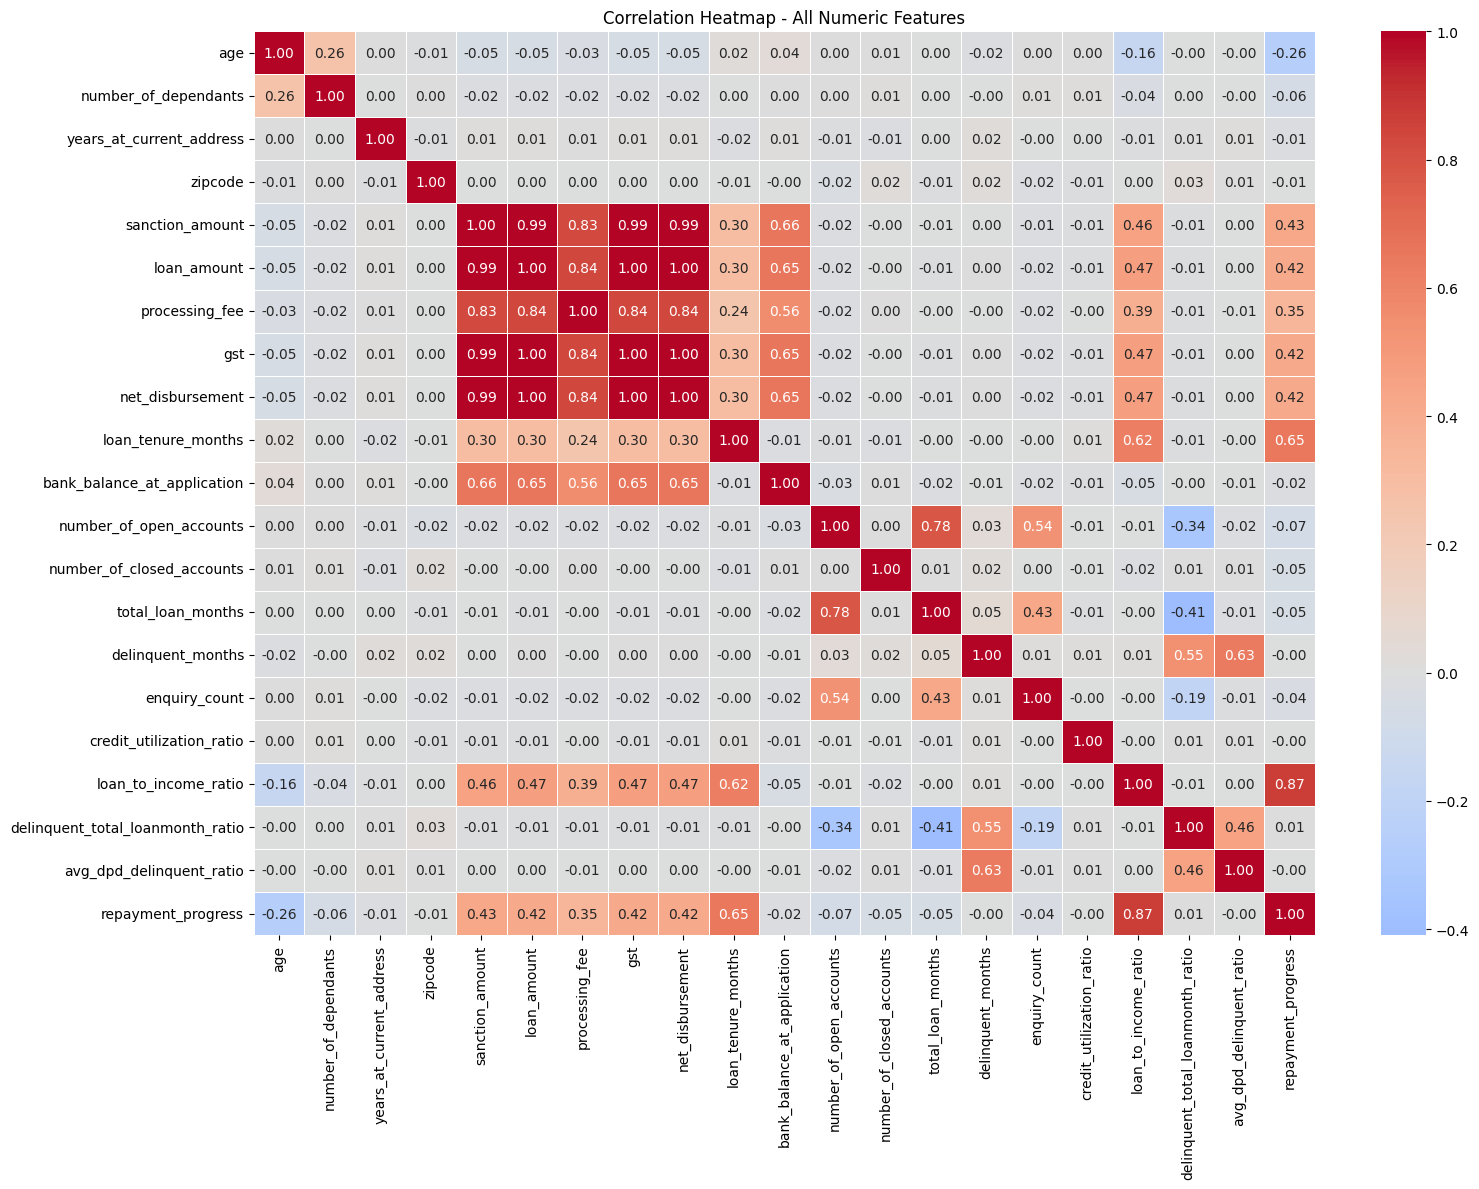

In [175]:
# Only numeric columns

plt.figure(figsize=(16, 12))
sns.heatmap(x_test_vif_3[cos_to_scale_vif_test_3].corr(), 
            annot=True,          # show numbers
            fmt='.2f',           # 2 decimal places
            cmap='coolwarm',     # red=high, blue=low correlation
            center=0,
            linewidths=0.5)

plt.title('Correlation Heatmap - All Numeric Features')
plt.tight_layout()
plt.show()

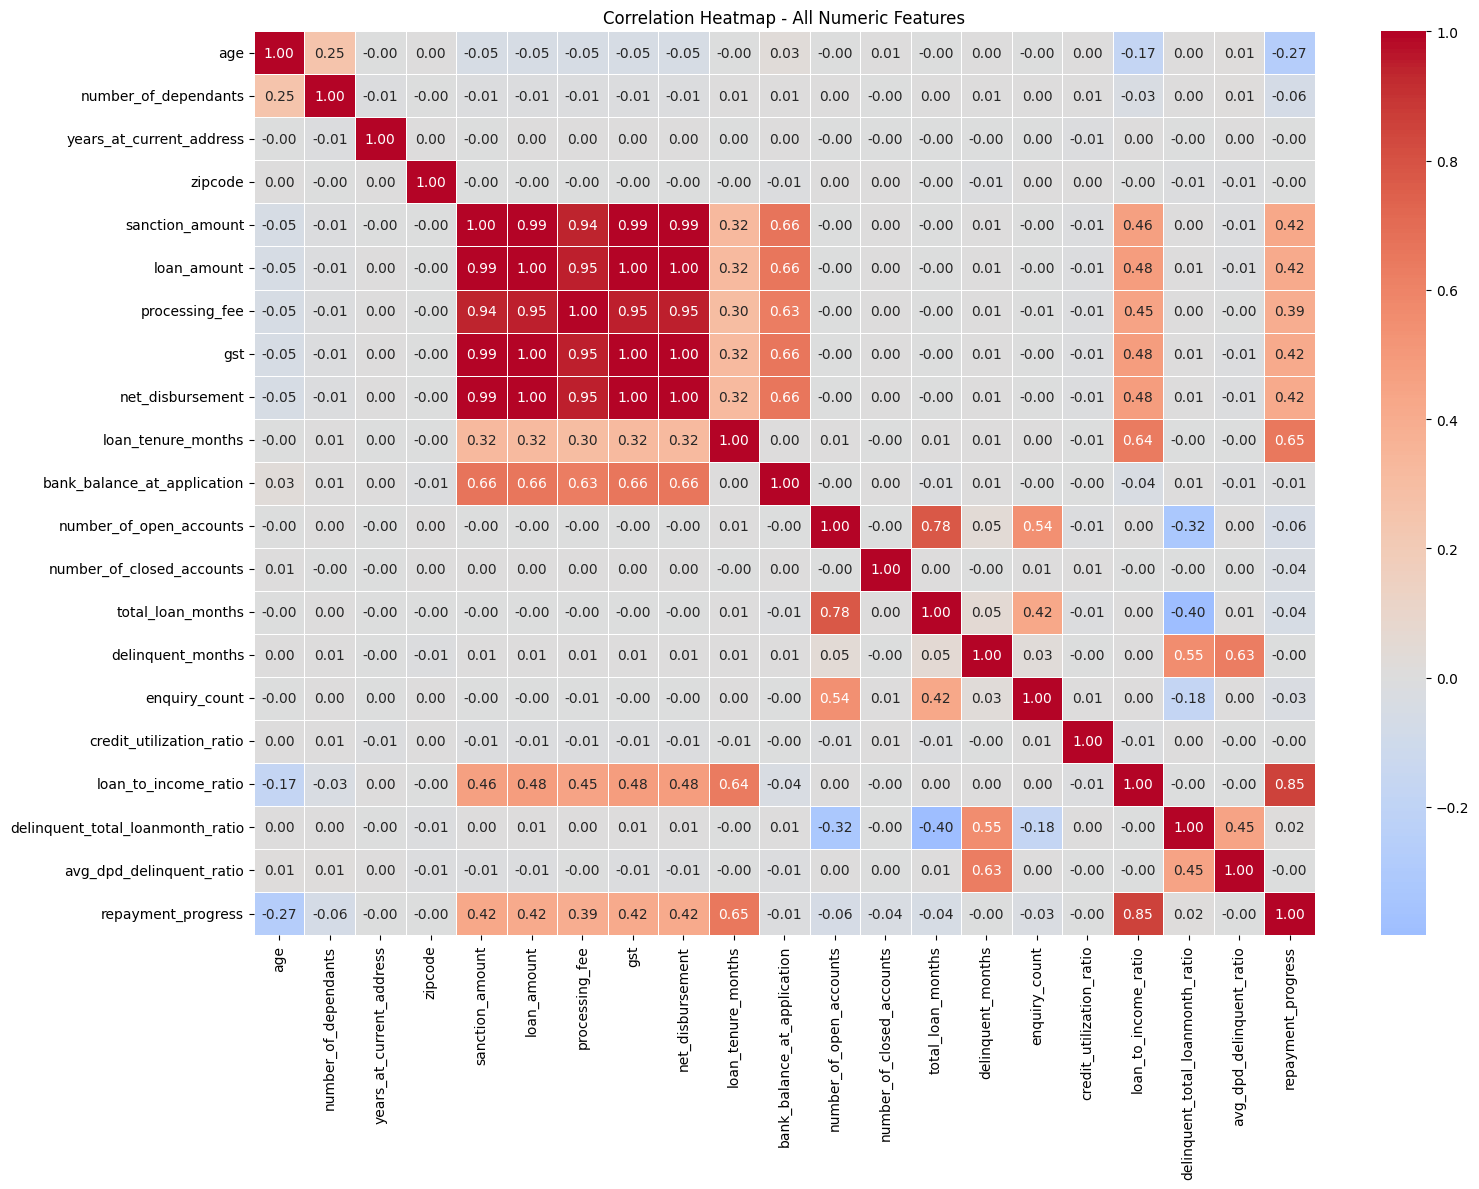

In [176]:
# Only numeric columns

plt.figure(figsize=(16, 12))
sns.heatmap(x_train_vif_3[cos_to_scale_vif_train_3].corr(), 
            annot=True,          # show numbers
            fmt='.2f',           # 2 decimal places
            cmap='coolwarm',     # red=high, blue=low correlation
            center=0,
            linewidths=0.5)

plt.title('Correlation Heatmap - All Numeric Features')
plt.tight_layout()
plt.show()

<span style="color:red">

## Weight of Evidence (WOE), Information Value (IV)

- Influence of categorical variable on target variable.
- For classification - we use WOE and IV
- **IV (Information Value)** measures how powerful a feature is in predicting the target (default vs non-default)
- 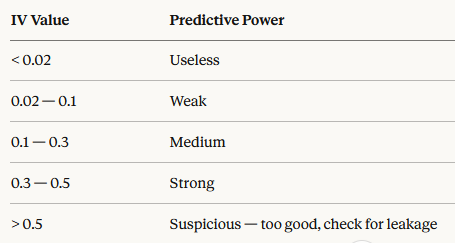
- **WoE (Weight of Evidence)** measures how strongly each category/bin of a feature separates defaults from non-defaults
- WoE = ln(Distribution of Events (good) / Distribution of Non-Events (bad))
- 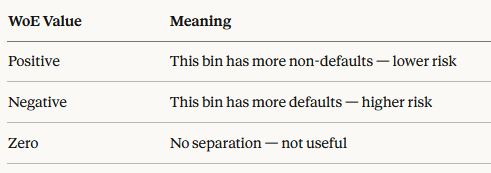
- 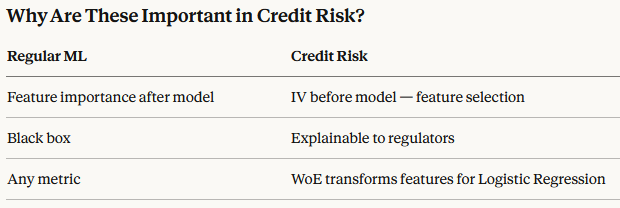

</span>

In [177]:
x_test_vif_3.columns

Index(['age', 'gender', 'marital_status', 'employment_status',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio',
       'repayment_progress'],
      dtype='object')

In [178]:
x_test_vif_4=x_test_vif_3
# .drop(['disbursal_date','installment_start_dt'],axis=1)

In [179]:
# 
x_train_vif_4=x_train_vif_3
    # .drop(['disbursal_date','installment_start_dt'],axis=1)

In [180]:
x_test_vif_4.shape,x_train_vif_3.shape

((12498, 29), (37492, 29))

In [181]:
cat_cols_test_1 = x_test_vif_4.select_dtypes(include=['object','bool']).columns
cat_cols_test_1

Index(['gender', 'marital_status', 'employment_status', 'residence_type',
       'city', 'state', 'loan_purpose', 'loan_type'],
      dtype='object')

In [182]:
cat_cols_train_1 = x_train_vif_4.select_dtypes(include=['object','bool']).columns
cat_cols_train_1

Index(['gender', 'marital_status', 'employment_status', 'residence_type',
       'city', 'state', 'loan_purpose', 'loan_type'],
      dtype='object')

In [183]:
temp_train=pd.concat([x_train_vif_4,y_train],axis=1)
temp_test=pd.concat([x_test_vif_4,y_test],axis=1)

In [184]:
temp_test.columns

Index(['age', 'gender', 'marital_status', 'employment_status',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio',
       'repayment_progress', 'default'],
      dtype='object')

In [185]:
temp_train.columns

Index(['age', 'gender', 'marital_status', 'employment_status',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio',
       'repayment_progress', 'default'],
      dtype='object')

In [186]:
def calculate_woe_iv(df,feature,target):
    # grouping and counting total default and non default
    grouped=df.groupby(feature)[target].agg(['count','sum'])
    grouped=grouped.rename(columns={'count':'total','sum':'bad'})

    # calculating non default
    grouped['good']=grouped['total']-grouped['bad']

    # calculating total good-non default and total bad -total default
    total_good=grouped['good'].sum()
    total_bad=grouped['bad'].sum()

    # calculating percentage of good-non default and bad-default
    grouped['good_pct']=grouped['good']/total_good
    grouped['bad_pct']=grouped['bad']/total_bad

    # calcualting weight of evidance using the formula
    grouped['woe']=np.log(grouped['good_pct']/grouped['bad_pct'])

    # calculating information value
    grouped['IV']=grouped['woe']*(grouped['good_pct']-grouped['bad_pct'])

    # infinite or undefined handling
    grouped['woe']=grouped['woe'].replace([np.inf,-np.inf],0)
    grouped['IV']=grouped['IV'].replace([np.inf,-np.inf],0)

    total_iv=grouped['IV'].sum()
    
    return grouped,total_iv

In [187]:
calculate_woe_iv(df=temp_test,feature='loan_purpose',target='default')

(              total  bad  good  good_pct   bad_pct       woe        IV
 loan_purpose                                                          
 Auto           2486   99  2387  0.208946  0.092179  0.818346  0.095556
 Education      1935  185  1750  0.153186  0.172253 -0.117311  0.002237
 Home           3721  599  3122  0.273284  0.557728 -0.713359  0.202911
 Personal       4356  191  4165  0.364583  0.177840  0.717872  0.134058,
 np.float64(0.43476125834916024))

In [188]:
calculate_woe_iv(df=temp_train,feature='loan_purpose',target='default')

(              total   bad   good  good_pct   bad_pct       woe        IV
 loan_purpose                                                            
 Auto           7448   327   7121  0.207797  0.101458  0.716915  0.076236
 Education      5620   559   5061  0.147684  0.173441 -0.160759  0.004141
 Home          11304  1734   9570  0.279261  0.538008 -0.655726  0.169667
 Personal      13120   603  12517  0.365257  0.187093  0.668997  0.119192,
 np.float64(0.36923514096150756))

In [189]:
temp_test[temp_test.loan_purpose=='Auto'][['loan_purpose','default']].value_counts()

loan_purpose  default
Auto          0          2387
              1            99
Name: count, dtype: int64

In [190]:
temp_train[temp_train.loan_purpose=='Auto'][['loan_purpose','default']].value_counts()

loan_purpose  default
Auto          0          7121
              1           327
Name: count, dtype: int64

In [191]:
iv_values_train={}

for feature in x_train_vif_4.columns:
    if x_train_vif_4[feature].dtype=='object':
        _,iv=calculate_woe_iv(pd.concat([x_train_vif_4,y_train],axis=1),feature,'default')
        iv_values_train[feature]=iv
        
iv_values_train

{'gender': np.float64(0.0004734386528504607),
 'marital_status': np.float64(0.0011329079327390564),
 'employment_status': np.float64(0.003963972530488743),
 'residence_type': np.float64(0.24659815838464944),
 'city': np.float64(0.0019081988740125772),
 'state': np.float64(0.0019028002985705238),
 'loan_purpose': np.float64(0.36923514096150756),
 'loan_type': np.float64(0.1632689146981865)}

In [192]:
iv_values_test={}

for feature in x_test_vif_4.columns:
    if x_test_vif_4[feature].dtype=='object':
        _,iv=calculate_woe_iv(pd.concat([x_test_vif_4,y_test],axis=1),feature,'default')
        iv_values_test[feature]=iv
        
iv_values_test

{'gender': np.float64(0.0001993857017148767),
 'marital_status': np.float64(0.005589418774824545),
 'employment_status': np.float64(0.000805677832980953),
 'residence_type': np.float64(0.24881288261631854),
 'city': np.float64(0.01173004198048955),
 'state': np.float64(0.010450047962486558),
 'loan_purpose': np.float64(0.43476125834916024),
 'loan_type': np.float64(0.1821731166971511)}

In [193]:
iv_values_train={}

for feature in x_train_vif_4.columns:
    if x_train_vif_4[feature].dtype=='object':
        _,iv=calculate_woe_iv(pd.concat([x_train_vif_4,y_train],axis=1),feature,'default')
        iv_values_train[feature]=iv
        
iv_values_train

{'gender': np.float64(0.0004734386528504607),
 'marital_status': np.float64(0.0011329079327390564),
 'employment_status': np.float64(0.003963972530488743),
 'residence_type': np.float64(0.24659815838464944),
 'city': np.float64(0.0019081988740125772),
 'state': np.float64(0.0019028002985705238),
 'loan_purpose': np.float64(0.36923514096150756),
 'loan_type': np.float64(0.1632689146981865)}

In [194]:
df_IV_test = pd.DataFrame(list(iv_values_test.items()),columns=['feature','IV'])
df_IV_test=df_IV_test.sort_values(by='IV',ascending=False)
df_IV_test

,feature,IV
6,loan_purpose,0.434761
3,residence_type,0.248813
7,loan_type,0.182173
4,city,0.011730
5,state,0.010450
1,marital_status,0.005589
2,employment_status,0.000806
0,gender,0.000199


In [195]:
df_IV_train = pd.DataFrame(list(iv_values_train.items()),columns=['feature','IV'])
df_IV_train=df_IV_train.sort_values(by='IV',ascending=False)
df_IV_train

,feature,IV
6,loan_purpose,0.369235
3,residence_type,0.246598
7,loan_type,0.163269
2,employment_status,0.003964
4,city,0.001908
5,state,0.001903
1,marital_status,0.001133
0,gender,0.000473


In [196]:
iv_values_test

{'gender': np.float64(0.0001993857017148767),
 'marital_status': np.float64(0.005589418774824545),
 'employment_status': np.float64(0.000805677832980953),
 'residence_type': np.float64(0.24881288261631854),
 'city': np.float64(0.01173004198048955),
 'state': np.float64(0.010450047962486558),
 'loan_purpose': np.float64(0.43476125834916024),
 'loan_type': np.float64(0.1821731166971511)}

In [197]:
df_IV_test = pd.DataFrame(list(iv_values_test.items()),columns=['feature','IV'])
df_IV_test=df_IV_test.sort_values(by='IV',ascending=False)
df_IV_test

,feature,IV
6,loan_purpose,0.434761
3,residence_type,0.248813
7,loan_type,0.182173
4,city,0.011730
5,state,0.010450
1,marital_status,0.005589
2,employment_status,0.000806
0,gender,0.000199


In [198]:
print(x_test_vif_4['employment_status'].value_counts(normalize=True) * 100)
print(x_test_vif_4['marital_status'].value_counts(normalize=True) * 100)

employment_status
Self-Employed    65.114418
Salaried         34.885582
Name: proportion, dtype: float64
marital_status
Married    54.712754
Single     45.287246
Name: proportion, dtype: float64


In [199]:
print(x_train_vif_4['employment_status'].value_counts(normalize=True) * 100)
print(x_train_vif_4['marital_status'].value_counts(normalize=True) * 100)

employment_status
Self-Employed    64.120346
Salaried         35.879654
Name: proportion, dtype: float64
marital_status
Married    54.961058
Single     45.038942
Name: proportion, dtype: float64


In [200]:
# This shows DEFAULT RATE per group
print(temp_test.groupby('employment_status')['default'].mean() * 100)
print(temp_test.groupby('marital_status')['default'].mean() * 100)

employment_status
Salaried         8.899083
Self-Employed    8.429590
Name: default, dtype: float64
marital_status
Married    8.057912
Single     9.240283
Name: default, dtype: float64


In [201]:
# This shows DEFAULT RATE per group
print(temp_train.groupby('employment_status')['default'].mean() * 100)
print(temp_train.groupby('marital_status')['default'].mean() * 100)

employment_status
Salaried         9.262563
Self-Employed    8.223794
Name: default, dtype: float64
marital_status
Married    8.356789
Single     8.889020
Name: default, dtype: float64


In [202]:
print(temp_test.groupby('gender')['default'].mean() * 100)

gender
F    8.728427
M    8.502079
Name: default, dtype: float64


In [203]:
print(temp_train.groupby('gender')['default'].mean() * 100)

gender
F    8.806628
M    8.456894
Name: default, dtype: float64


<span style="color:blue">

- From the above output: the IV values are below to <0.02 - city,state,marital_status,employment_status,gender.
- 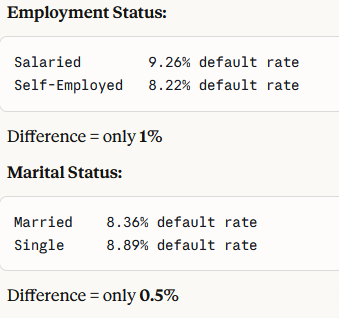

### IV Interpretation:

 - IV is low because the default rates between categories are almost identical
 - The model cannot learn anything from these features because:
  - Salaried vs Self-Employed default at nearly the same rate
  - Married vs Single default at nearly the same rate.
  - You assumed employment status matters — the data says in this dataset it does not separate defaulters from non-defaulters meaningfully
  - 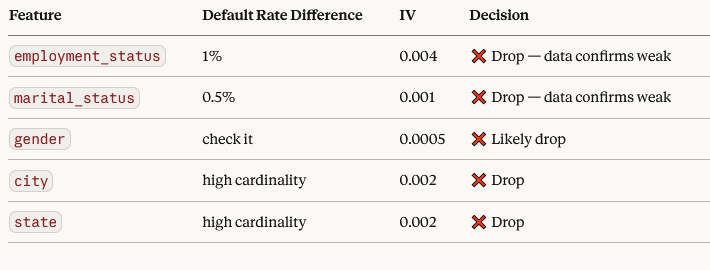
  - All three demographic features show:
   - Less than 1% difference in default rates between categories
   - IV below 0.02 — useless predictors
   - Data confirms they cannot separate defaulters from non-defaulters

</span>

In [204]:
# Drop low IV categorical columns
cat_cols_to_drop = ['employment_status', 'marital_status', 
                'gender', 'city', 'state']

x_train_vif_5 = x_train_vif_4.drop(columns=cat_cols_to_drop)
x_test_vif_5 = x_test_vif_4.drop(columns=cat_cols_to_drop)

In [205]:
x_train_vif_5.shape,y_train.shape

((37492, 24), (37492,))

In [206]:
x_test_vif_5.shape,y_test.shape

((12498, 24), (12498,))

In [207]:
iv_values_test_1={}

for feature in x_test_vif_5.columns:
    if x_test_vif_5[feature].dtype=='object':
        _,iv=calculate_woe_iv(pd.concat([x_test_vif_5,y_test],axis=1),feature,'default')
        
    else:
        x_binned=pd.cut(x_test_vif_5[feature],bins=10,labels=False)
        _,iv=calculate_woe_iv(pd.concat([x_binned,y_test],axis=1),feature,'default')
    iv_values_test_1[feature]=iv
        
iv_values_test_1

{'age': np.float64(0.04638484531291248),
 'number_of_dependants': np.float64(0.011466843824558915),
 'residence_type': np.float64(0.24881288261631854),
 'years_at_current_address': np.float64(0.011599897804958601),
 'zipcode': np.float64(0.011256660625811692),
 'loan_purpose': np.float64(0.43476125834916024),
 'loan_type': np.float64(0.1821731166971511),
 'sanction_amount': np.float64(0.09203671390030961),
 'loan_amount': np.float64(0.09381306078530911),
 'processing_fee': np.float64(0.015560873482533941),
 'gst': np.float64(0.09381306078530911),
 'net_disbursement': np.float64(0.09381306078530911),
 'loan_tenure_months': np.float64(0.2420074292731123),
 'bank_balance_at_application': np.float64(0.008327136889857954),
 'number_of_open_accounts': np.float64(0.08043165161120663),
 'number_of_closed_accounts': np.float64(0.0004557828391112478),
 'total_loan_months': np.float64(0.1819661596422478),
 'delinquent_months': np.float64(0.34766161464043616),
 'enquiry_count': np.float64(0.010175

In [208]:
iv_values_train_1={}

for feature in x_train_vif_5.columns:
    if x_train_vif_5[feature].dtype=='object':
        _,iv=calculate_woe_iv(pd.concat([x_train_vif_5,y_train],axis=1),feature,'default')
        
    else:
        x_binned=pd.cut(x_train_vif_5[feature],bins=10,labels=False)
        _,iv=calculate_woe_iv(pd.concat([x_binned,y_train],axis=1),feature,'default')
    iv_values_train_1[feature]=iv
        
iv_values_train_1

{'age': np.float64(0.08910867359672536),
 'number_of_dependants': np.float64(0.0019362964841476125),
 'residence_type': np.float64(0.24659815838464944),
 'years_at_current_address': np.float64(0.0020854584024337574),
 'zipcode': np.float64(0.0016720140989614062),
 'loan_purpose': np.float64(0.36923514096150756),
 'loan_type': np.float64(0.1632689146981865),
 'sanction_amount': np.float64(0.09561074087833715),
 'loan_amount': np.float64(0.0997629515907705),
 'processing_fee': np.float64(0.011565234192297437),
 'gst': np.float64(0.0997629515907705),
 'net_disbursement': np.float64(0.0997629515907705),
 'loan_tenure_months': np.float64(0.2190196250162581),
 'bank_balance_at_application': np.float64(0.006328924738665639),
 'number_of_open_accounts': np.float64(0.08466215154655732),
 'number_of_closed_accounts': np.float64(0.001198250290438227),
 'total_loan_months': np.float64(0.19038776176729963),
 'delinquent_months': np.float64(0.3539263702468499),
 'enquiry_count': np.float64(0.0078696

In [209]:
iv_values_test_1={}

for feature in x_test_vif_5.columns:
    if x_test_vif_5[feature].dtype=='object':
        _,iv=calculate_woe_iv(pd.concat([x_test_vif_5,y_test],axis=1),feature,'default')
        
    else:
        x_binned=pd.cut(x_test_vif_5[feature],bins=10,labels=False)
        _,iv=calculate_woe_iv(pd.concat([x_binned,y_test],axis=1),feature,'default')
    iv_values_test_1[feature]=iv
        
iv_values_test_1

{'age': np.float64(0.04638484531291248),
 'number_of_dependants': np.float64(0.011466843824558915),
 'residence_type': np.float64(0.24881288261631854),
 'years_at_current_address': np.float64(0.011599897804958601),
 'zipcode': np.float64(0.011256660625811692),
 'loan_purpose': np.float64(0.43476125834916024),
 'loan_type': np.float64(0.1821731166971511),
 'sanction_amount': np.float64(0.09203671390030961),
 'loan_amount': np.float64(0.09381306078530911),
 'processing_fee': np.float64(0.015560873482533941),
 'gst': np.float64(0.09381306078530911),
 'net_disbursement': np.float64(0.09381306078530911),
 'loan_tenure_months': np.float64(0.2420074292731123),
 'bank_balance_at_application': np.float64(0.008327136889857954),
 'number_of_open_accounts': np.float64(0.08043165161120663),
 'number_of_closed_accounts': np.float64(0.0004557828391112478),
 'total_loan_months': np.float64(0.1819661596422478),
 'delinquent_months': np.float64(0.34766161464043616),
 'enquiry_count': np.float64(0.010175

In [210]:
df_IV_train_1 = pd.DataFrame(list(iv_values_train_1.items()),columns=['feature','IV'])
df_IV_train_1=df_IV_train_1.sort_values(by='IV',ascending=False)
df_IV_train_1

,feature,IV
19,credit_utilization_ratio,2.352728
21,delinquent_total_loanmonth_ratio,0.716664
20,loan_to_income_ratio,0.475809
22,avg_dpd_delinquent_ratio,0.401656
5,loan_purpose,0.369235
17,delinquent_months,0.353926
2,residence_type,0.246598
12,loan_tenure_months,0.219020
16,total_loan_months,0.190388
6,loan_type,0.163269


In [211]:
df_IV_test_1 = pd.DataFrame(list(iv_values_test_1.items()),columns=['feature','IV'])
df_IV_test_1=df_IV_test_1.sort_values(by='IV',ascending=False)
df_IV_test_1

,feature,IV
19,credit_utilization_ratio,2.618766
21,delinquent_total_loanmonth_ratio,0.665929
20,loan_to_income_ratio,0.496101
5,loan_purpose,0.434761
23,repayment_progress,0.433234
22,avg_dpd_delinquent_ratio,0.428156
17,delinquent_months,0.347662
2,residence_type,0.248813
12,loan_tenure_months,0.242007
6,loan_type,0.182173


## Col drop after IV evaluation 

- number_of_open_accounts 	0.084662
- enquiry_count 	0.007870
- bank_balance_at_application 	0.006329
- years_at_current_address 	0.002085
- number_of_dependants 	0.001936
- repayment_progress 	0.001275
- number_of_closed_accounts 	0.001198

<span style="color:red">

## Dropped column:

- cust_id, loan_id, zip code, loan amount, gst, processing fee, net disbursement amount, total_dpd,income, enquiry_count, bank_balance_at_application,years_at_current_address, number_of_dependants, repayment_progress,number_of_closed_accounts

</span>

In [212]:
# Drop low IV categorical columns
cat_cols_to_drop_last_itr = ['enquiry_count', 'bank_balance_at_application',
                         'years_at_current_address', 'number_of_dependants', 'repayment_progress','number_of_closed_accounts']

x_train_vif_5 = x_train_vif_5.drop(columns=cat_cols_to_drop_last_itr)
x_test_vif_5 = x_test_vif_5.drop(columns=cat_cols_to_drop_last_itr)

In [213]:
x_train_vif_5.shape,y_train.shape,x_test_vif_5.shape,y_test.shape

((37492, 18), (37492,), (12498, 18), (12498,))

<span style="color:green">

## Feature Encoding

</span>

In [214]:
x_test_vif_5.head(3)

,age,residence_type,zipcode,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,number_of_open_accounts,total_loan_months,delinquent_months,credit_utilization_ratio,loan_to_income_ratio,delinquent_total_loanmonth_ratio,avg_dpd_delinquent_ratio
19205,0.346154,Owned,0.325424,Home,Secured,0.248323,0.213746,0.034544,0.213746,0.213746,0.754717,0.333333,0.186364,0.0,0.989899,0.548695,0.0,0.0
15514,0.480769,Owned,0.000000,Education,Secured,0.082618,0.065970,0.010662,0.065970,0.065970,0.226415,1.000000,0.563636,0.0,0.323232,0.219343,0.0,0.0
30367,0.230769,Owned,0.000000,Auto,Secured,0.086354,0.071097,0.011490,0.071097,0.071097,0.547170,0.666667,0.340909,0.0,0.828283,0.179484,0.0,0.0


In [215]:
x_train_vif_5.head(3)

,age,residence_type,zipcode,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,number_of_open_accounts,total_loan_months,delinquent_months,credit_utilization_ratio,loan_to_income_ratio,delinquent_total_loanmonth_ratio,avg_dpd_delinquent_ratio
12746,0.788462,Owned,0.661017,Home,Secured,0.634301,0.489626,0.088375,0.489626,0.489626,0.415094,1.000000,0.680180,0.833333,0.363636,0.415167,0.1316,0.590
32495,0.500000,Owned,0.491525,Education,Secured,0.021170,0.022884,0.004130,0.022884,0.022884,0.830189,0.666667,0.716216,0.416667,0.050505,0.306759,0.0625,0.620
43675,0.384615,Mortgage,0.830508,Home,Secured,0.217588,0.235329,0.042476,0.235329,0.235329,0.490566,0.000000,0.238739,0.500000,0.000000,0.758694,0.2222,0.558


In [216]:
x_test_encoded=pd.get_dummies(x_test_vif_5,drop_first=True)
x_train_encoded=pd.get_dummies(x_train_vif_5,drop_first=True)

In [217]:
x_train_encoded.head(5)

,age,zipcode,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,number_of_open_accounts,total_loan_months,...,credit_utilization_ratio,loan_to_income_ratio,delinquent_total_loanmonth_ratio,avg_dpd_delinquent_ratio,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
12746,0.788462,0.661017,0.634301,0.489626,0.088375,0.489626,0.489626,0.415094,1.000000,0.680180,...,0.363636,0.415167,0.1316,0.590,True,False,False,True,False,False
32495,0.500000,0.491525,0.021170,0.022884,0.004130,0.022884,0.022884,0.830189,0.666667,0.716216,...,0.050505,0.306759,0.0625,0.620,True,False,True,False,False,False
43675,0.384615,0.830508,0.217588,0.235329,0.042476,0.235329,0.235329,0.490566,0.000000,0.238739,...,0.000000,0.758694,0.2222,0.558,False,False,False,True,False,False
9040,0.461538,0.762712,0.043452,0.034315,0.006194,0.034315,0.034315,0.641509,0.666667,0.337838,...,0.878788,0.194976,0.0000,0.000,False,False,True,False,False,False
13077,0.769231,0.510169,0.021016,0.017775,0.003208,0.017775,0.017775,0.169811,0.000000,0.265766,...,0.717172,0.046893,0.0000,0.000,True,False,False,False,True,True


In [218]:
x_test_encoded.head(5)

,age,zipcode,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,number_of_open_accounts,total_loan_months,...,credit_utilization_ratio,loan_to_income_ratio,delinquent_total_loanmonth_ratio,avg_dpd_delinquent_ratio,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
19205,0.346154,0.325424,0.248323,0.213746,0.034544,0.213746,0.213746,0.754717,0.333333,0.186364,...,0.989899,0.548695,0.0000,0.000,True,False,False,True,False,False
15514,0.480769,0.000000,0.082618,0.065970,0.010662,0.065970,0.065970,0.226415,1.000000,0.563636,...,0.323232,0.219343,0.0000,0.000,True,False,True,False,False,False
30367,0.230769,0.000000,0.086354,0.071097,0.011490,0.071097,0.071097,0.547170,0.666667,0.340909,...,0.828283,0.179484,0.0000,0.000,True,False,False,False,False,False
35347,0.365385,0.510169,0.038473,0.032779,0.005297,0.032779,0.032779,0.754717,1.000000,0.563636,...,0.484848,0.567833,0.0240,0.700,True,False,False,True,False,False
41814,0.576923,0.830508,0.035382,0.028260,0.004567,0.028260,0.028260,0.716981,0.666667,0.590909,...,0.979798,0.406184,0.1069,0.636,False,False,False,True,False,False


<span style="color:orange">

## Model Training

- Logistic regression - High Explainability
- Random Forest
- XGB
- No handling of class imbalance
- Target Recall: >90%
- Target Precision: >50%
</span>

## Logistic Regression

In [219]:
x_train_encoded.shape,y_train.shape,x_test_encoded.shape,y_test.shape

((37492, 21), (37492,), (12498, 21), (12498,))

In [220]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

In [221]:
log_model=LogisticRegression()


In [222]:
log_model.fit(x_train_encoded,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [223]:
y_pred_lg=log_model.predict(x_test_encoded)

In [224]:
report_lg=classification_report(y_test,y_pred_lg)
print(report_lg)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11424
           1       0.85      0.72      0.78      1074

    accuracy                           0.96     12498
   macro avg       0.91      0.85      0.88     12498
weighted avg       0.96      0.96      0.96     12498



## Random Forest

In [225]:
from sklearn.ensemble import RandomForestClassifier

In [226]:
rf_model=RandomForestClassifier()
rf_model.fit(x_train_encoded,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [227]:
y_pred_rf=rf_model.predict(x_test_encoded)
report_rf=classification_report(y_test,y_pred_rf)
print(report_rf)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11424
           1       0.87      0.69      0.77      1074

    accuracy                           0.96     12498
   macro avg       0.92      0.84      0.87     12498
weighted avg       0.96      0.96      0.96     12498



## XGB Classifier

In [228]:
from xgboost import XGBClassifier

In [229]:
xgb_model=XGBClassifier()
xgb_model.fit(x_train_encoded,y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [230]:
y_pred_xgb=xgb_model.predict(x_test_encoded)
report_xgb=classification_report(y_test,y_pred_xgb)
print(report_xgb)

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     11424
           1       0.82      0.75      0.78      1074

    accuracy                           0.96     12498
   macro avg       0.90      0.87      0.88     12498
weighted avg       0.96      0.96      0.96     12498



## Randomized Search CV

- 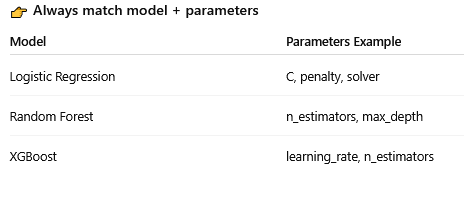

### Random Search CV with logistic regression

In [231]:
from sklearn.model_selection import RandomizedSearchCV

# Example model
from sklearn.ensemble import RandomForestClassifier


In [232]:
# Parameter distribution (not grid, use ranges)
param_dist_lg = {
    # for logistic regression 
    'C': np.logspace(-3, 3, 50),
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga'],
    'class_weight': [None, 'balanced']
    
}

# Random Search
random_search = RandomizedSearchCV(
       
    estimator=log_model,
    param_distributions=param_dist_lg,
    n_iter=20,              # number of random combinations
    scoring='roc_auc',     # or 'accuracy', 'f1'
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)



In [233]:

# Fit
random_search.fit(x_train_encoded,y_train)



Fitting 5 folds for each of 20 candidates, totalling 100 fits


,estimator,LogisticRegression()
,param_distributions,"{'C': array([1.0000...00000000e+03]), 'class_weight': [None, 'balanced'], 'penalty': ['l1', 'l2'], 'solver': ['liblinear', 'saga']}"
,n_iter,20
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,5
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [234]:
# Best params
print("Best Params:", random_search.best_params_)

# Best model
best_model_rcv = random_search.best_estimator_

# Predictions
y_pred_rcv = best_model_rcv.predict(x_test_encoded)

# Evaluation
print(classification_report(y_test, y_pred_rcv))


Best Params: {'solver': 'saga', 'penalty': 'l2', 'class_weight': 'balanced', 'C': np.float64(2.6826957952797246)}
              precision    recall  f1-score   support

           0       0.99      0.92      0.96     11424
           1       0.54      0.95      0.69      1074

    accuracy                           0.93     12498
   macro avg       0.77      0.94      0.82     12498
weighted avg       0.96      0.93      0.93     12498



### Random Search CV with Random Forest Classifier

In [235]:
# Parameter distribution (not grid, use ranges)
param_dist_rf = {
    # for random forest 
    
    'n_estimators': np.arange(100, 1000, 100),
    'max_depth': [None, 5, 10, 20, 30, 50],
    'min_samples_split': np.arange(2, 20, 2),
    'min_samples_leaf': np.arange(1, 10, 1),
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True, False],
    'criterion': ['gini', 'entropy']
    
}

# Random Search
random_search_rf = RandomizedSearchCV(
       
    estimator=rf_model,
    param_distributions=param_dist_rf,
    n_iter=20,              # number of random combinations
    scoring='roc_auc',     # or 'accuracy', 'f1'
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)



In [236]:

# Fit
random_search_rf.fit(x_train_encoded,y_train)



Fitting 5 folds for each of 20 candidates, totalling 100 fits


,estimator,RandomForestClassifier()
,param_distributions,"{'bootstrap': [True, False], 'criterion': ['gini', 'entropy'], 'max_depth': [None, 5, ...], 'max_features': ['sqrt', 'log2', ...], ...}"
,n_iter,20
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,5
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [237]:
# Best params
print("Best Params:", random_search_rf.best_params_)

# Best model
best_model_rf = random_search_rf.best_estimator_

# Predictions
y_pred_rf = best_model_rf.predict(x_test_encoded)

# Evaluation
print(classification_report(y_test, y_pred_rf))


Best Params: {'n_estimators': np.int64(300), 'min_samples_split': np.int64(4), 'min_samples_leaf': np.int64(2), 'max_features': 'sqrt', 'max_depth': 30, 'criterion': 'entropy', 'bootstrap': True}
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11424
           1       0.88      0.68      0.77      1074

    accuracy                           0.96     12498
   macro avg       0.93      0.84      0.88     12498
weighted avg       0.96      0.96      0.96     12498



- Note - Did not find any improvement, so taking the class imbalance handling
- Logistic Regression and XBG class imbalance handling

##  Class Imbalance - Model Performance Improvement

In [238]:
# class imbalance issue
y_train.value_counts()

default
0    34269
1     3223
Name: count, dtype: int64

In [239]:
from imblearn.under_sampling import RandomUnderSampler

In [240]:
rus=RandomUnderSampler(random_state=42)

In [241]:
x_train_rus,y_train_rus=rus.fit_resample(x_train_encoded,y_train)

In [242]:
y_train_rus.value_counts()

default
0    3223
1    3223
Name: count, dtype: int64

### Checking rus train with logitic models - Attempt 1

In [243]:
log_model_rus=LogisticRegression()
log_model_rus.fit(x_train_rus,y_train_rus)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [244]:


y_pred_lg_rus=log_model_rus.predict(x_test_encoded)
report_lg_rus=classification_report(y_test,y_pred_lg_rus)
print(report_lg_rus)

              precision    recall  f1-score   support

           0       1.00      0.91      0.95     11424
           1       0.51      0.96      0.67      1074

    accuracy                           0.92     12498
   macro avg       0.75      0.94      0.81     12498
weighted avg       0.95      0.92      0.93     12498



### Checking rus train with XGBoost models - Attempt 1

In [245]:
xgb_model_rus=XGBClassifier()
xgb_model_rus.fit(x_train_rus,y_train_rus)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [246]:

y_pred_xgb_rus=xgb_model_rus.predict(x_test_encoded)
report_xgb_rus=classification_report(y_test,y_pred_xgb_rus)
print(report_xgb_rus)

              precision    recall  f1-score   support

           0       1.00      0.93      0.96     11424
           1       0.55      0.97      0.70      1074

    accuracy                           0.93     12498
   macro avg       0.77      0.95      0.83     12498
weighted avg       0.96      0.93      0.94     12498



## Model Performance Improvement - Attempt 2

- Logistic Regression
- Handling Class Imbalance using **SMOTE Tomek**
- Parameter tuning using **optuna**

In [247]:
from imblearn.combine import SMOTETomek

In [248]:
smt=SMOTETomek(random_state=42)

In [249]:

x_train_smt,y_train_smt=smt.fit_resample(x_train_encoded,y_train)
y_train_smt.value_counts()

default
0    34252
1    34252
Name: count, dtype: int64

In [250]:
log_model_smt=LogisticRegression()
log_model_smt.fit(x_train_smt,y_train_smt)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


<span style="color:red">

### Top Model Performer (remark)

</span>

In [251]:


y_pred_lg_smt=log_model_smt.predict(x_test_encoded)
report_lg_smt=classification_report(y_test,y_pred_lg_smt)
print(report_lg_smt)

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11424
           1       0.56      0.94      0.71      1074

    accuracy                           0.93     12498
   macro avg       0.78      0.94      0.83     12498
weighted avg       0.96      0.93      0.94     12498



In [252]:
xgb_model_smt=XGBClassifier()
xgb_model_smt.fit(x_train_smt,y_train_smt)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [253]:

y_pred_xgb_smt=xgb_model_smt.predict(x_test_encoded)
report_xgb_smt=classification_report(y_test,y_pred_xgb_smt)
print(report_xgb_smt)

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     11424
           1       0.76      0.81      0.78      1074

    accuracy                           0.96     12498
   macro avg       0.87      0.89      0.88     12498
weighted avg       0.96      0.96      0.96     12498



<span style="color:blue">
    
## Optuna - Hypter paramter tuning

</span>

In [254]:
import optuna
from sklearn.model_selection import cross_val_score

In [255]:
def objective(trial):
    C=trial.suggest_float("C",1,5)
    solver=trial.suggest_categorical("solver",["newton-cg","lbfgs","liblinear","sag","saga"])
    model_lg=LogisticRegression(C=C,solver=solver,max_iter=1000)
    scores=cross_val_score(model_lg,x_train_encoded,y_train,scoring="accuracy")
    accuracy=np.mean(scores)
    return accuracy

study=optuna.create_study(direction="maximize")
study.optimize(objective,n_trials=10)

print("Best Parameters:",study.best_params)
print("Best Cross-Validation Accuracy:",study.best_value)

[I 2026-03-29 20:32:24,687] A new study created in memory with name: no-name-64937992-640d-4793-9ba2-ae79db52d563
[I 2026-03-29 20:32:31,414] Trial 0 finished with value: 0.960978284256697 and parameters: {'C': 4.022592766494801, 'solver': 'saga'}. Best is trial 0 with value: 0.960978284256697.
[I 2026-03-29 20:32:37,885] Trial 1 finished with value: 0.960924940254326 and parameters: {'C': 3.2994269590185947, 'solver': 'saga'}. Best is trial 0 with value: 0.960978284256697.
[I 2026-03-29 20:32:39,794] Trial 2 finished with value: 0.9609782878136752 and parameters: {'C': 3.472393967228399, 'solver': 'newton-cg'}. Best is trial 2 with value: 0.9609782878136752.
[I 2026-03-29 20:32:40,919] Trial 3 finished with value: 0.9610582878108296 and parameters: {'C': 2.6150095705879486, 'solver': 'lbfgs'}. Best is trial 3 with value: 0.9610582878108296.
[I 2026-03-29 20:32:42,623] Trial 4 finished with value: 0.9607915784699095 and parameters: {'C': 1.7230272677615486, 'solver': 'liblinear'}. Best

Best Parameters: {'C': 2.6150095705879486, 'solver': 'lbfgs'}
Best Cross-Validation Accuracy: 0.9610582878108296


In [256]:
optuna_model=LogisticRegression(**study.best_params,max_iter=2000)
optuna_model.fit(x_train_encoded,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,2.6150095705879486
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [257]:
y_pred_opt=optuna_model.predict(x_test_encoded)
report_opt=classification_report(y_test,y_pred_opt)
print(report_opt)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11424
           1       0.84      0.73      0.78      1074

    accuracy                           0.96     12498
   macro avg       0.91      0.86      0.88     12498
weighted avg       0.96      0.96      0.96     12498



In [258]:
import optuna
from sklearn.metrics import make_scorer,f1_score
from sklearn.model_selection import cross_val_score

In [259]:
def objective(trial):
    param ={
    "C" : trial.suggest_float("C",1e-4,1e4,log=True),
    'solver' : trial.suggest_categorical("solver",["lbfgs","liblinear","saga","newton-cg"]),
    'tol' : trial.suggest_float("tol",1e-6,1e-1,log=True),
    'class_weight' : trial.suggest_categorical("class_weight",[None,'balanced'])
    }
    model=LogisticRegression(**param,max_iter=10000)

    # calculate cross validated f1-score
    f1_scorer=make_scorer(f1_score,average='macro')
    scores=cross_val_score(log_model_smt,x_train_smt,y_train_smt,cv=3,scoring=f1_scorer,n_jobs=-1)
    return np.mean(scores)

study_logistic=optuna.create_study(direction="maximize")
study_logistic.optimize(objective,n_trials=50)

[I 2026-03-29 20:32:59,515] A new study created in memory with name: no-name-08944fa2-6a52-49af-a2c4-6013257d4c92
[I 2026-03-29 20:33:01,056] Trial 0 finished with value: 0.945954912821778 and parameters: {'C': 10.802721201822553, 'solver': 'lbfgs', 'tol': 5.63114414897018e-05, 'class_weight': None}. Best is trial 0 with value: 0.945954912821778.
[I 2026-03-29 20:33:06,360] Trial 1 finished with value: 0.945954912821778 and parameters: {'C': 118.72261206771842, 'solver': 'saga', 'tol': 0.014991343848261666, 'class_weight': None}. Best is trial 0 with value: 0.945954912821778.
[I 2026-03-29 20:33:07,025] Trial 2 finished with value: 0.945954912821778 and parameters: {'C': 4338.610264158976, 'solver': 'lbfgs', 'tol': 0.0005857075484529201, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.945954912821778.
[I 2026-03-29 20:33:07,690] Trial 3 finished with value: 0.945954912821778 and parameters: {'C': 0.002636276007188146, 'solver': 'newton-cg', 'tol': 9.092633324178872e-06, 'cla

In [260]:
print('Best trial:')
trial = study_logistic.best_trial
print('  F1-score: {}'.format(trial.value))
print('  Params: ')
for key, value in trial.params.items():
    print('    {}: {}'.format(key, value))
    
best_model_logistic = LogisticRegression(**study_logistic.best_params)
best_model_logistic.fit(x_train_smt,y_train_smt)
# log_model_smt,,cv=3,scoring=f1_scorer,n_jobs=-1

# Evaluate on the test set
y_pred = best_model_logistic.predict(x_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

Best trial:
  F1-score: 0.945954912821778
  Params: 
    C: 10.802721201822553
    solver: lbfgs
    tol: 5.63114414897018e-05
    class_weight: None
              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11424
           1       0.57      0.94      0.71      1074

    accuracy                           0.93     12498
   macro avg       0.78      0.94      0.83     12498
weighted avg       0.96      0.93      0.94     12498



## Optuna- Attempt - Wih XGBoost

1. XGBoost
2. Handle Class Imbalance Using SMOTE Tomek
3. Parameter tunning using optuna

In [261]:
# Define the objective function for Optuna
def objective(trial):
    param = {
        'objective': 'binary:logistic',
        'eval_metric': 'logloss',
        'verbosity': 0,
        'booster': 'gbtree',
        'lambda': trial.suggest_float('lambda', 1e-3, 10.0, log=True),
        'alpha': trial.suggest_float('alpha', 1e-3, 10.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.4, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'eta': trial.suggest_float('eta', 0.01, 0.3),
        'gamma': trial.suggest_float('gamma', 0, 10),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'max_delta_step': trial.suggest_int('max_delta_step', 0, 10)
    }

    model_xgb = XGBClassifier(**param)
    
    # Calculate the cross-validated f1_score
    f1_scorer = make_scorer(f1_score, average='macro')
    scores = cross_val_score(model_xgb, x_train_smt,y_train_smt, cv=3, scoring=f1_scorer, n_jobs=-1)
    
    return np.mean(scores)

study_xgb = optuna.create_study(direction='maximize')
study_xgb.optimize(objective, n_trials=50)

[I 2026-03-29 20:33:41,534] A new study created in memory with name: no-name-da1ff203-710c-43f2-816d-79b3d120b329
[I 2026-03-29 20:33:46,181] Trial 0 finished with value: 0.970755760359566 and parameters: {'lambda': 3.404207639346488, 'alpha': 0.275663189907529, 'subsample': 0.9378038551178964, 'colsample_bytree': 0.9898052163416823, 'max_depth': 7, 'eta': 0.14424303998073718, 'gamma': 1.119471849578072, 'scale_pos_weight': 6.724139970025893, 'min_child_weight': 1, 'max_delta_step': 9}. Best is trial 0 with value: 0.970755760359566.
[I 2026-03-29 20:33:49,258] Trial 1 finished with value: 0.9646966354542262 and parameters: {'lambda': 0.9146895833425495, 'alpha': 0.7979217686216684, 'subsample': 0.7147265438985189, 'colsample_bytree': 0.635640234405145, 'max_depth': 5, 'eta': 0.18637498311225256, 'gamma': 0.4541549316925553, 'scale_pos_weight': 5.9195283008116855, 'min_child_weight': 10, 'max_delta_step': 5}. Best is trial 0 with value: 0.970755760359566.
[I 2026-03-29 20:33:52,757] Tri

In [262]:
print('Best trial:')
trial = study_xgb.best_trial
print('  F1-score: {}'.format(trial.value))
print('  Params: ')
for key, value in trial.params.items():
    print('    {}: {}'.format(key, value))
    
best_params = study_xgb.best_params
best_model_xgb = XGBClassifier(**best_params)
best_model_xgb.fit(x_train_smt, y_train_smt)

# Evaluate on the test set
y_pred = best_model_xgb.predict(x_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

Best trial:
  F1-score: 0.976257276036146
  Params: 
    lambda: 0.0018601841164229635
    alpha: 0.5153263074616521
    subsample: 0.7593358949531541
    colsample_bytree: 0.6226123633119328
    max_depth: 10
    eta: 0.2550081217192996
    gamma: 0.6940396382025816
    scale_pos_weight: 5.818970087663782
    min_child_weight: 1
    max_delta_step: 2
              precision    recall  f1-score   support

           0       0.99      0.97      0.98     11424
           1       0.71      0.85      0.77      1074

    accuracy                           0.96     12498
   macro avg       0.85      0.91      0.87     12498
weighted avg       0.96      0.96      0.96     12498



In [263]:
y_pred_lg_smt=log_model_smt.predict(x_test_encoded)
report_lg_smt=classification_report(y_test,y_pred_lg_smt)
print(report_lg_smt)

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11424
           1       0.56      0.94      0.71      1074

    accuracy                           0.93     12498
   macro avg       0.78      0.94      0.83     12498
weighted avg       0.96      0.93      0.94     12498



## Detailed Discussion and Model Evaluation Analysis

- This is imbalanced credit default prediction, the most important metric is Class 1 (default) performance — specifically Recall (catching actual defaulters) and F1-score for class 1.
- 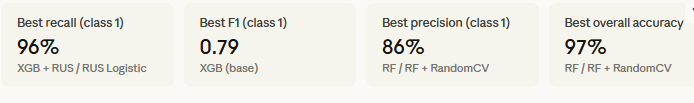

### Base Model -

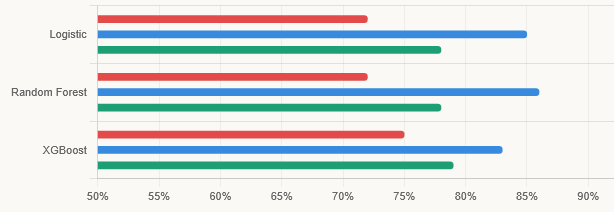

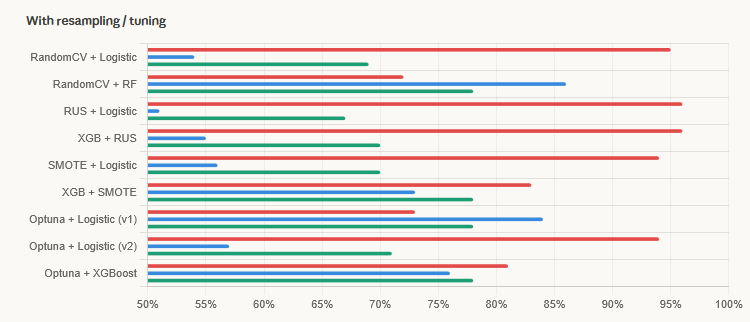

<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>Model Recommendation - Credit Default Prediction</title>
    <style>
        body {
            font-family: Arial, sans-serif;
            line-height: 1.6;
            margin: 20px;
            color: #333;
        }
        h1, h2, h3 {
            color: #2c3e50;
        }
        .section {
            margin-bottom: 25px;
        }
        .highlight {
            background-color: #f4f6f7;
            padding: 10px;
            border-left: 5px solid #3498db;
        }
        ul {
            margin-left: 20px;
        }
    </style>
</head>
<body>

<h1>Model Recommendation for Credit Default Prediction</h1>

<div class="section">
<p>
        Based on the evaluation of multiple models for an imbalanced credit default dataset,
        the recommended approach is:
</p>

<h2 class="highlight">XGBoost + SMOTE Tomek</h2>
</div>

<div class="section">
<h2>The Core Trade-off</h2>
<p>The models can be categorized into two groups based on performance:</p>

<h3>Group A — High Recall, Low Precision</h3>
<ul>
<li>Models: RUS, RandomCV + Logistic, SMOTE + Logistic, Optuna v2</li>
<li>Recall: 94–96% (captures most defaulters)</li>
<li>Precision: 51–57% (high false positives)</li>
<li>Implication: Detects most defaulters but generates many false alarms</li>
</ul>

<h3>Group B — Balanced Precision & Recall</h3>
<ul>
<li>Models: Base models, Random Forest variants, XGBoost + SMOTE, Optuna + XGBoost</li>
        <li>Recall: 72–83%</li>
        <li>Precision: 73–86%</li>
        <li>F1 Score: ~0.78–0.79</li>
        <li>Implication: More practical and balanced performance</li>
    </ul>
</div>

<div class="section">
    <h2>🏆 Recommended Model: XGBoost + SMOTE Tomek</h2>
    <ul>
        <li>F1 Score: 0.78 (Class 1)</li>
        <li>Recall: 83% (highest among balanced models)</li>
        <li>Precision: 73% (significantly better than high-recall models)</li>
    </ul>

<h3>Why this model?</h3>
    <ul>
        <li>Combines SMOTE (oversampling) with Tomek links (noise removal)</li>
        <li>Theoretically robust resampling approach</li>
        <li>XGBoost performs exceptionally well on tabular and imbalanced data</li>
    </ul>
</div>

<div class="section">
<h2>🥈 Runner-up: Optuna + XGBoost</h2>
    <ul>
        <li>F1 Score: 0.78</li>
        <li>Recall: 81%</li>
        <li>Precision: 76%</li>
    </ul>

<p>
        This model provides slightly better precision but slightly lower recall.
        Optuna tuning makes it more robust and potentially better for generalization.
    </p>
</div>

<div class="section">
    <h2>⚠️ Models to Avoid for Production</h2>
    <ul>
        <li>RUS + Logistic Regression</li>
        <li>RandomCV + Logistic Regression</li>
    </ul>

<p>
        These models have low precision (51–54%), meaning nearly half of the predicted defaults
        are false positives, which can be costly in a lending environment.
    </p>
</div>

<div class="section">
    <h2>💡 Final Business Insight</h2>
    <p>
        The optimal model depends on business priorities:
    </p>
    <ul>
        <li>
            <strong>High Recall Priority:</strong> If missing a defaulter is very costly,
            choose high-recall models (Group A).
        </li>
        <li>
            <strong>Balanced Approach:</strong> If false positives are costly (rejecting good customers),
            prefer XGBoost + SMOTE Tomek.
        </li>
    </ul>
</div>

</body>
</html>


In [264]:
from sklearn.metrics import roc_curve

probabilities = best_model_logistic.predict_proba(x_test_encoded)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, probabilities)

fpr[:5], tpr[:5], thresholds[:5]

(array([0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 8.7535014e-05,
        8.7535014e-05]),
 array([0.        , 0.0009311 , 0.15456238, 0.15456238, 0.17318436]),
 array([       inf, 1.        , 0.99957565, 0.9995703 , 0.9993348 ]))

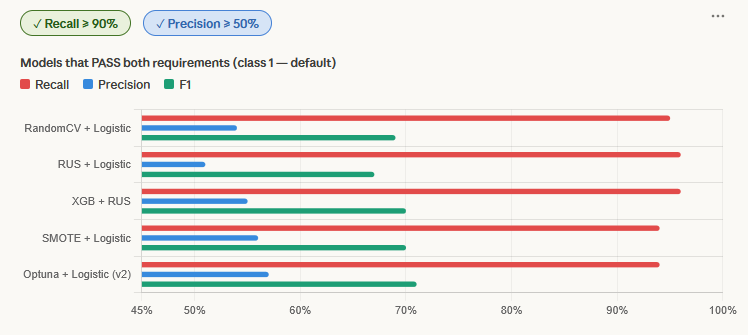

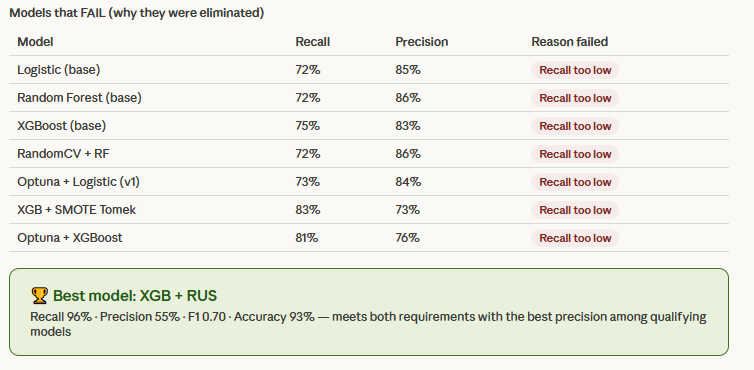

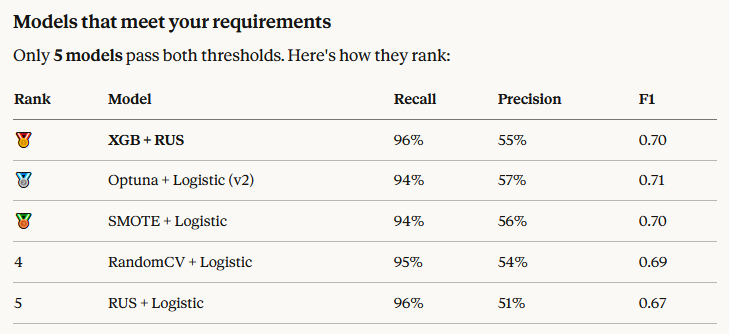

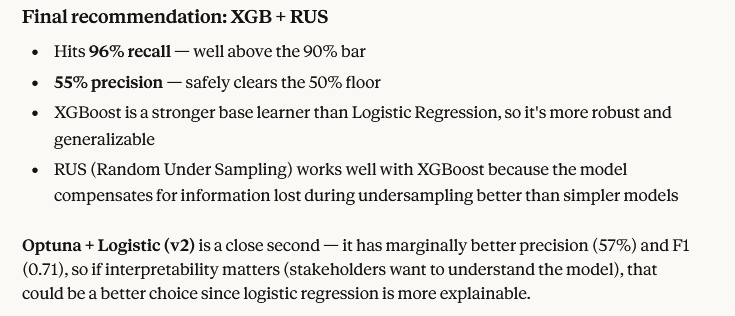


In [265]:
from sklearn.metrics import auc

area = auc(fpr, tpr)
area

0.9836761054514916

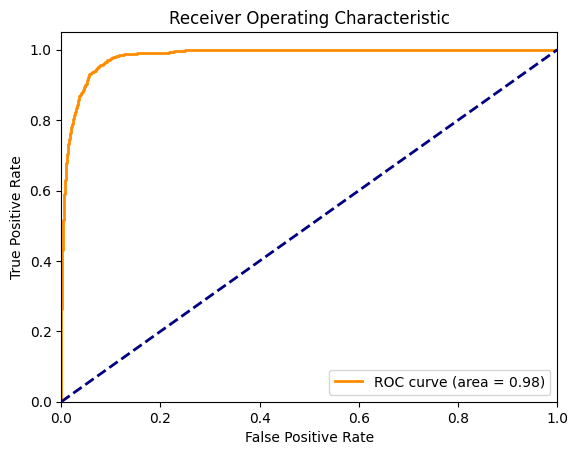

In [266]:
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % area)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

<span style="color: red">
    
## Rank Ordering and KS Statistics, Gini Coefficient

</span>

---
---

In [267]:
best_model_xgb_rus=xgb_model_rus

In [271]:
# y_pred_lg_smt=log_model_smt.predict(x_test_encoded)
best_report=classification_report(y_test,y_pred_xgb_rus)
print(best_report)

              precision    recall  f1-score   support

           0       1.00      0.93      0.96     11424
           1       0.55      0.97      0.70      1074

    accuracy                           0.93     12498
   macro avg       0.77      0.95      0.83     12498
weighted avg       0.96      0.93      0.94     12498



In [272]:
y_pred_best=y_pred_xgb_rus

In [273]:
# y_pred_lg_smt=log_model_smt.predict(x_test_encoded)
best_report=classification_report(y_test,y_pred_best)
print(best_report)

              precision    recall  f1-score   support

           0       1.00      0.93      0.96     11424
           1       0.55      0.97      0.70      1074

    accuracy                           0.93     12498
   macro avg       0.77      0.95      0.83     12498
weighted avg       0.96      0.93      0.94     12498



--------------------------------------------------------
--------------------------------------------------------

In [274]:
prob=best_model_xgb_rus.predict_proba(x_test_encoded)
print(prob)

[[1.3635075e-01 8.6364925e-01]
 [9.9999869e-01 1.2834787e-06]
 [9.9996603e-01 3.3958138e-05]
 ...
 [9.9987751e-01 1.2247331e-04]
 [5.3009450e-02 9.4699055e-01]
 [2.2038203e-01 7.7961797e-01]]


In [275]:
from sklearn.metrics import roc_curve

probabilities =best_model_xgb_rus.predict_proba(x_test_encoded)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, probabilities)

fpr[:5], tpr[:5], thresholds[:5]

(array([0., 0., 0., 0., 0.]),
 array([0.        , 0.0009311 , 0.00372439, 0.00744879, 0.03165736]),
 array([       inf, 0.999997  , 0.99999607, 0.99999344, 0.9999795 ],
       dtype=float32))

In [276]:
area=auc(fpr,tpr)
area

0.984828120028272

In [277]:
probabilities = best_model_xgb_rus.predict_proba(x_test_encoded)[:,1]

df_eval = pd.DataFrame({
    'Default Truth': y_test,
    'Default Probability': probabilities
})
df_eval.head(3)

,Default Truth,Default Probability
19205,0,0.863649
15514,0,0.000001
30367,0,0.000034


In [278]:
df_eval['Decile'] = pd.qcut(df_eval['Default Probability'], 10, labels=False, duplicates='drop')
df_eval.head(3)

,Default Truth,Default Probability,Decile
19205,0,0.863649,8
15514,0,0.000001,1
30367,0,0.000034,4


In [279]:
df_eval[df_eval.Decile==8]['Default Probability'].describe()

count    1250.000000
mean        0.508581
std         0.300793
min         0.079216
25%         0.211919
50%         0.504136
75%         0.807703
max         0.947188
Name: Default Probability, dtype: float64

In [280]:
df_decile = df_eval.groupby('Decile').apply(lambda x: pd.Series({
    'Minimum Probability': x['Default Probability'].min(),
    'Maximum Probability': x['Default Probability'].max(),
    'Events': x['Default Truth'].sum(),
    'Non-events': x['Default Truth'].count() - x['Default Truth'].sum(),    
}))
df_decile.reset_index(inplace=True)
df_decile

C:\Users\Ravindra\AppData\Local\Temp\ipykernel_5480\4037021561.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_decile = df_eval.groupby('Decile').apply(lambda x: pd.Series({


,Decile,Minimum Probability,Maximum Probability,Events,Non-events
0,0,9.816461e-09,6.451568e-07,0.0,1250.0
1,1,6.459640e-07,2.548048e-06,0.0,1250.0
2,2,2.550722e-06,7.102959e-06,0.0,1250.0
3,3,7.107032e-06,1.971361e-05,0.0,1249.0
4,4,1.973044e-05,6.001845e-05,0.0,1250.0
5,5,6.002996e-05,2.783275e-04,0.0,1250.0
6,6,2.784382e-04,2.520553e-03,0.0,1249.0
7,7,2.525247e-03,7.904924e-02,6.0,1244.0
8,8,7.921597e-02,9.471881e-01,181.0,1069.0
9,9,9.476744e-01,9.999970e-01,887.0,363.0


In [281]:
df_decile['Event Rate'] = df_decile['Events']*100 / (df_decile['Events']+df_decile['Non-events'])
df_decile['Non-event Rate'] = df_decile['Non-events']*100 / (df_decile['Events']+df_decile['Non-events'])
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate
0,0,9.816461e-09,6.451568e-07,0.0,1250.0,0.00,100.00
1,1,6.459640e-07,2.548048e-06,0.0,1250.0,0.00,100.00
2,2,2.550722e-06,7.102959e-06,0.0,1250.0,0.00,100.00
3,3,7.107032e-06,1.971361e-05,0.0,1249.0,0.00,100.00
4,4,1.973044e-05,6.001845e-05,0.0,1250.0,0.00,100.00
5,5,6.002996e-05,2.783275e-04,0.0,1250.0,0.00,100.00
6,6,2.784382e-04,2.520553e-03,0.0,1249.0,0.00,100.00
7,7,2.525247e-03,7.904924e-02,6.0,1244.0,0.48,99.52
8,8,7.921597e-02,9.471881e-01,181.0,1069.0,14.48,85.52
9,9,9.476744e-01,9.999970e-01,887.0,363.0,70.96,29.04


In [282]:
df_decile = df_decile.sort_values(by='Decile', ascending=False).reset_index(drop=True)
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate
0,9,9.476744e-01,9.999970e-01,887.0,363.0,70.96,29.04
1,8,7.921597e-02,9.471881e-01,181.0,1069.0,14.48,85.52
2,7,2.525247e-03,7.904924e-02,6.0,1244.0,0.48,99.52
3,6,2.784382e-04,2.520553e-03,0.0,1249.0,0.00,100.00
4,5,6.002996e-05,2.783275e-04,0.0,1250.0,0.00,100.00
5,4,1.973044e-05,6.001845e-05,0.0,1250.0,0.00,100.00
6,3,7.107032e-06,1.971361e-05,0.0,1249.0,0.00,100.00
7,2,2.550722e-06,7.102959e-06,0.0,1250.0,0.00,100.00
8,1,6.459640e-07,2.548048e-06,0.0,1250.0,0.00,100.00
9,0,9.816461e-09,6.451568e-07,0.0,1250.0,0.00,100.00


In [283]:
df_decile['Cum Events'] =  df_decile['Events'].cumsum()
df_decile['Cum Non-events'] =  df_decile['Non-events'].cumsum()
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events
0,9,9.476744e-01,9.999970e-01,887.0,363.0,70.96,29.04,887.0,363.0
1,8,7.921597e-02,9.471881e-01,181.0,1069.0,14.48,85.52,1068.0,1432.0
2,7,2.525247e-03,7.904924e-02,6.0,1244.0,0.48,99.52,1074.0,2676.0
3,6,2.784382e-04,2.520553e-03,0.0,1249.0,0.00,100.00,1074.0,3925.0
4,5,6.002996e-05,2.783275e-04,0.0,1250.0,0.00,100.00,1074.0,5175.0
5,4,1.973044e-05,6.001845e-05,0.0,1250.0,0.00,100.00,1074.0,6425.0
6,3,7.107032e-06,1.971361e-05,0.0,1249.0,0.00,100.00,1074.0,7674.0
7,2,2.550722e-06,7.102959e-06,0.0,1250.0,0.00,100.00,1074.0,8924.0
8,1,6.459640e-07,2.548048e-06,0.0,1250.0,0.00,100.00,1074.0,10174.0
9,0,9.816461e-09,6.451568e-07,0.0,1250.0,0.00,100.00,1074.0,11424.0


In [284]:
df_decile['Cum Event Rate'] = df_decile['Cum Events'] * 100 / df_decile['Events'].sum()
df_decile['Cum Non-event Rate'] = df_decile['Cum Non-events']*100 / df_decile['Non-events'].sum()
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events,Cum Event Rate,Cum Non-event Rate
0,9,9.476744e-01,9.999970e-01,887.0,363.0,70.96,29.04,887.0,363.0,82.588454,3.177521
1,8,7.921597e-02,9.471881e-01,181.0,1069.0,14.48,85.52,1068.0,1432.0,99.441341,12.535014
2,7,2.525247e-03,7.904924e-02,6.0,1244.0,0.48,99.52,1074.0,2676.0,100.000000,23.424370
3,6,2.784382e-04,2.520553e-03,0.0,1249.0,0.00,100.00,1074.0,3925.0,100.000000,34.357493
4,5,6.002996e-05,2.783275e-04,0.0,1250.0,0.00,100.00,1074.0,5175.0,100.000000,45.299370
5,4,1.973044e-05,6.001845e-05,0.0,1250.0,0.00,100.00,1074.0,6425.0,100.000000,56.241246
6,3,7.107032e-06,1.971361e-05,0.0,1249.0,0.00,100.00,1074.0,7674.0,100.000000,67.174370
7,2,2.550722e-06,7.102959e-06,0.0,1250.0,0.00,100.00,1074.0,8924.0,100.000000,78.116246
8,1,6.459640e-07,2.548048e-06,0.0,1250.0,0.00,100.00,1074.0,10174.0,100.000000,89.058123
9,0,9.816461e-09,6.451568e-07,0.0,1250.0,0.00,100.00,1074.0,11424.0,100.000000,100.000000


In [285]:
df_decile['KS'] = abs(df_decile['Cum Event Rate'] - df_decile['Cum Non-event Rate'])
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events,Cum Event Rate,Cum Non-event Rate,KS
0,9,9.476744e-01,9.999970e-01,887.0,363.0,70.96,29.04,887.0,363.0,82.588454,3.177521,79.410933
1,8,7.921597e-02,9.471881e-01,181.0,1069.0,14.48,85.52,1068.0,1432.0,99.441341,12.535014,86.906327
2,7,2.525247e-03,7.904924e-02,6.0,1244.0,0.48,99.52,1074.0,2676.0,100.000000,23.424370,76.575630
3,6,2.784382e-04,2.520553e-03,0.0,1249.0,0.00,100.00,1074.0,3925.0,100.000000,34.357493,65.642507
4,5,6.002996e-05,2.783275e-04,0.0,1250.0,0.00,100.00,1074.0,5175.0,100.000000,45.299370,54.700630
5,4,1.973044e-05,6.001845e-05,0.0,1250.0,0.00,100.00,1074.0,6425.0,100.000000,56.241246,43.758754
6,3,7.107032e-06,1.971361e-05,0.0,1249.0,0.00,100.00,1074.0,7674.0,100.000000,67.174370,32.825630
7,2,2.550722e-06,7.102959e-06,0.0,1250.0,0.00,100.00,1074.0,8924.0,100.000000,78.116246,21.883754
8,1,6.459640e-07,2.548048e-06,0.0,1250.0,0.00,100.00,1074.0,10174.0,100.000000,89.058123,10.941877
9,0,9.816461e-09,6.451568e-07,0.0,1250.0,0.00,100.00,1074.0,11424.0,100.000000,100.000000,0.000000


In [286]:
gini_coefficient = 2 * area - 1

print("AUC:", area)
print("Gini Coefficient:", gini_coefficient)

AUC: 0.984828120028272
Gini Coefficient: 0.969656240056544


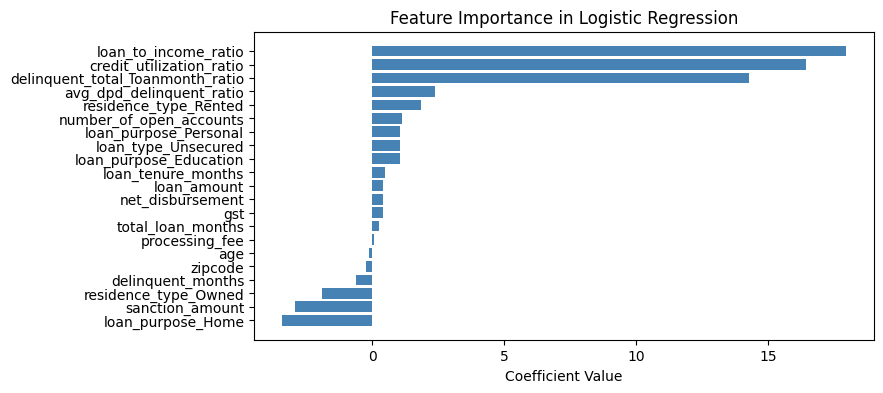

In [287]:
final_model = best_model_logistic

feature_importance = final_model.coef_[0]

# Create a DataFrame for easier handling
coef_df = pd.DataFrame(feature_importance, index=x_train_encoded.columns, columns=['Coefficients'])

# Sort the coefficients for better visualization
coef_df = coef_df.sort_values(by='Coefficients', ascending=True)

# Plotting
plt.figure(figsize=(8, 4))
plt.barh(coef_df.index, coef_df['Coefficients'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Logistic Regression')
plt.show()

In [332]:
x_train_encoded.columns

Index(['age', 'zipcode', 'sanction_amount', 'loan_amount', 'processing_fee',
       'gst', 'net_disbursement', 'loan_tenure_months',
       'number_of_open_accounts', 'total_loan_months', 'delinquent_months',
       'credit_utilization_ratio', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio',
       'residence_type_Owned', 'residence_type_Rented',
       'loan_purpose_Education', 'loan_purpose_Home', 'loan_purpose_Personal',
       'loan_type_Unsecured'],
      dtype='object')

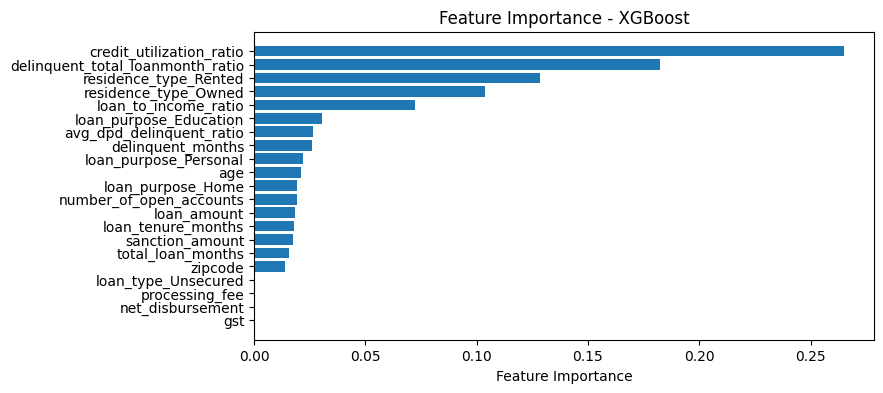

In [288]:
final_model = best_model_xgb_rus

feature_importance = final_model.feature_importances_

# Create DataFrame
coef_df = pd.DataFrame(
    feature_importance,
    index=x_train_encoded.columns,
    columns=['Importance']
)

# Sort
coef_df = coef_df.sort_values(by='Importance', ascending=True)

# Plot
plt.figure(figsize=(8, 4))
plt.barh(coef_df.index, coef_df['Importance'])
plt.xlabel('Feature Importance')
plt.title('Feature Importance - XGBoost')
plt.show()


In [289]:
x_test_encoded.columns

Index(['age', 'zipcode', 'sanction_amount', 'loan_amount', 'processing_fee',
       'gst', 'net_disbursement', 'loan_tenure_months',
       'number_of_open_accounts', 'total_loan_months', 'delinquent_months',
       'credit_utilization_ratio', 'loan_to_income_ratio',
       'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio',
       'residence_type_Owned', 'residence_type_Rented',
       'loan_purpose_Education', 'loan_purpose_Home', 'loan_purpose_Personal',
       'loan_type_Unsecured'],
      dtype='object')

In [290]:
cols_to_scale = [col for col in cos_to_scale if col in x_train_encoded.columns]
cols_to_scale

['age',
 'zipcode',
 'sanction_amount',
 'loan_amount',
 'processing_fee',
 'gst',
 'net_disbursement',
 'loan_tenure_months',
 'number_of_open_accounts',
 'total_loan_months',
 'delinquent_months',
 'credit_utilization_ratio',
 'loan_to_income_ratio',
 'delinquent_total_loanmonth_ratio',
 'avg_dpd_delinquent_ratio']

In [291]:
test_cols=cos_to_scale
test_cols

Index(['age', 'income', 'number_of_dependants', 'years_at_current_address',
       'zipcode', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio',
       'loan_to_income_ratio', 'delinquent_total_loanmonth_ratio',
       'avg_dpd_delinquent_ratio'],
      dtype='object')

<span style="color:red">
    
## Exporting Model For Web Application

</span>

In [298]:
final_model=best_model_xgb_rus

In [310]:
cols_to_scale = [col for col in cos_to_scale if col in x_train_encoded.columns]
cols_to_scale

['age',
 'zipcode',
 'sanction_amount',
 'loan_amount',
 'processing_fee',
 'gst',
 'net_disbursement',
 'loan_tenure_months',
 'number_of_open_accounts',
 'total_loan_months',
 'delinquent_months',
 'credit_utilization_ratio',
 'loan_to_income_ratio',
 'delinquent_total_loanmonth_ratio',
 'avg_dpd_delinquent_ratio']

In [311]:
final_feature_names = x_train_encoded.columns.tolist()
final_feature_names

['age',
 'zipcode',
 'sanction_amount',
 'loan_amount',
 'processing_fee',
 'gst',
 'net_disbursement',
 'loan_tenure_months',
 'number_of_open_accounts',
 'total_loan_months',
 'delinquent_months',
 'credit_utilization_ratio',
 'loan_to_income_ratio',
 'delinquent_total_loanmonth_ratio',
 'avg_dpd_delinquent_ratio',
 'residence_type_Owned',
 'residence_type_Rented',
 'loan_purpose_Education',
 'loan_purpose_Home',
 'loan_purpose_Personal',
 'loan_type_Unsecured']

In [ ]:
import joblib

# 1. Get the list of features your FINAL model actually uses
# This is the 'x_train_encoded' or 'x_test_encoded' you used in cell 219/301
final_feature_names = x_train_encoded.columns.tolist()

# 2. Re-fit a fresh scaler on ONLY these features
final_scaler = StandardScaler()
final_scaler.fit(x_train_encoded) 

# 3. Save this NEW scaler
joblib.dump(final_scaler, 'scaler.pkl')
print("New scaler saved with features:", final_feature_names)

In [299]:
from joblib import dump

# Fix 1: filter cols_to_scale to only columns present in final encoded dataset
cols_to_scale = [col for col in cos_to_scale if col in x_train_encoded.columns]

final_model = best_model_xgb_rus

model_data = {
    'model':         final_model,
    'features':      x_train_encoded.columns.tolist(),  # tolist() so it's not an Index object
    'scaler':        scaler,
    'cols_to_scale': cols_to_scale,
}

dump(model_data, '../artifacts/model_data.joblib')
print("Saved successfully!")

Saved successfully!


In [300]:
print(x_train_encoded.columns.tolist())
print(x_test_encoded.columns.tolist())
print(x_train_encoded.shape, x_test_encoded.shape)

['age', 'zipcode', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months', 'number_of_open_accounts', 'total_loan_months', 'delinquent_months', 'credit_utilization_ratio', 'loan_to_income_ratio', 'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio', 'residence_type_Owned', 'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home', 'loan_purpose_Personal', 'loan_type_Unsecured']
['age', 'zipcode', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months', 'number_of_open_accounts', 'total_loan_months', 'delinquent_months', 'credit_utilization_ratio', 'loan_to_income_ratio', 'delinquent_total_loanmonth_ratio', 'avg_dpd_delinquent_ratio', 'residence_type_Owned', 'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home', 'loan_purpose_Personal', 'loan_type_Unsecured']
(37492, 21) (12498, 21)


In [301]:
from sklearn.metrics import classification_report, roc_auc_score

y_pred = final_model.predict(x_test_encoded)
y_prob = final_model.predict_proba(x_test_encoded)[:, 1]

print(classification_report(y_test, y_pred))
print("AUC-ROC:", roc_auc_score(y_test, y_prob))

              precision    recall  f1-score   support

           0       1.00      0.93      0.96     11424
           1       0.55      0.97      0.70      1074

    accuracy                           0.93     12498
   macro avg       0.77      0.95      0.83     12498
weighted avg       0.96      0.93      0.94     12498

AUC-ROC: 0.984828120028272


Recall = 0.96 — out of all actual defaulters, model catches 96% ✅ Excellent
Precision = 0.55 — out of all predicted defaulters, only 55% actually default ⚠️ Moderate
Model is very good at catching defaulters but raises false alarms on good customers

In [302]:
print(final_model)
print("AUC-ROC:", roc_auc_score(y_test, y_prob))

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)
AUC-ROC: 0.984828120028272


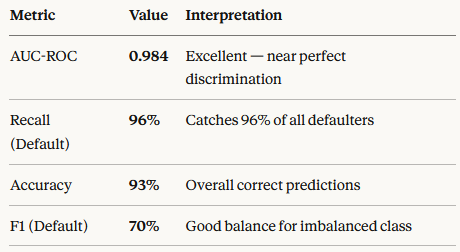

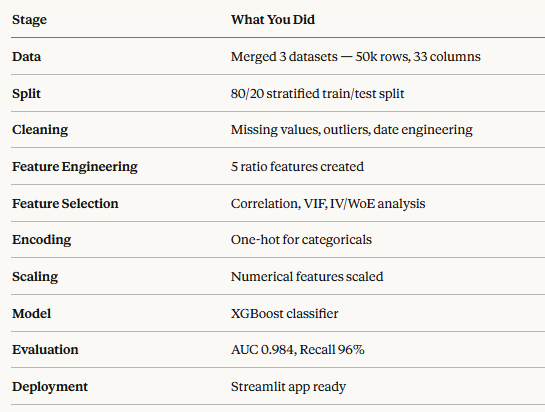

# These bureau features might be computed AFTER default occurs
# If so, they are leaking future information
print(x_train_encoded[['delinquent_months', 
                         'avg_dpd_delinquent_ratio',
                         'delinquent_total_loanmonth_ratio']].describe())

In [304]:
# Check correlation of these features with target
print(df_train[['delinquent_months', 'avg_dpd_delinquent_ratio', 
                'delinquent_total_loanmonth_ratio', 'default']].corr()['default'])

delinquent_months                   0.162795
avg_dpd_delinquent_ratio            0.158200
delinquent_total_loanmonth_ratio    0.315194
default                             1.000000
Name: default, dtype: float64


# Imoprant Note

"
I was facing error because scaling happned before the VIF and drop, so at that time there was 20 columns but later i dropped few features after VIF calcuation, so recreating the joblib file

"

<span style="color:red">

## Dropped column:

- cust_id,
- loan_id,
- zip code,
- loan amount,
- gst,
- processing fee,
- net disbursement amount,
- total_dpd,income,
- enquiry_count,
- bank_balance_at_application,
- years_at_current_address,
- number_of_dependants,
- repayment_progress,
- number_of_closed_accounts

</span>

In [325]:
l1=['cust_id','loan_id','zipcode','loan_amount','gst','processing_fee','net_disbursement_amount','total_dpd,income','enquiry_count','bank_balance_at_application','years_at_current_address','number_of_dependants','repayment_progress','number_of_closed_accounts']